Parte de este *script* se basa en [este](https://harpy.readthedocs.io/en/latest/tutorials/general/Harpy_xenium_transcriptomics_subset.html) y [este](https://harpy.readthedocs.io/en/latest/tutorials/advanced/Harpy_transcriptomics_xenium.html) tutorial de `Harpy`.

# 0. Carga de librerías y definición de rutas

In [1]:
# Importación de librerías

from pathlib import Path # Gestión de rutas de archivos y directorios.
import harpy as hp # La libreria principal.
import spatialdata as sd # Para leer los objetos de ómicas espaciales y manipularlos.
import matplotlib.pyplot as plt # Para visualizar los datos.
import geopandas as gpd # Necesario para leer los GeoJSONs de las regiones de interés e importar los de Baysor.
from harpy.datasets.registry import get_registry # Función específica para cargar datos de ejemplo de datasets de Harpy.
import cellpose # Para segmentación celular usando Cellpose.
from loguru import logger # Para registro de eventos.
from spatialdata.transformations import get_transformation # Para comprobar las escalas en los chunks generados de la imagen.
import torch # Para crear el entorno de computación local de Dask.
from dask.distributed import Client, LocalCluster # Para crear el entorno de computación local de Dask.
from matplotlib.colors import Normalize # Para normalizar contraste de las imágenes.
import spatialdata_plot # Necesaria para realizar plots de datos de ómicas espaciales.
from napari_spatialdata import Interactive # Para cargar el visualizador interactivo Napari.
import tifffile # Para manejo de archivos .tif, usado en la extracción de máscaras de segmentación para Baysor.
import pandas as pd # Librería general de manipulación de datos, Data Frames, etc.
import numpy as np # Librería general de manejo de datos en arrays y operaciones matemáticas.
from spatialdata_plot import PercentileNormalize # Ajuste de imágenes de spatialdata para visualización.
import matplotlib.patches as patches # Para la adición de ciertos elementos a las figuras creadas con matplotlib.
import shapely.affinity as affinity # Para manipulación de los datos importados desde baysor.
import anndata as ad # Para manejo de objetos tipo AnnData.
from spatialdata.models import TableModel # Para manejar las tablas dentro de los AnnData.
import scanpy as sc # Para análisis de Single-Cell, usado en el análisis de los resultados de segmentación.
import seaborn as sns # Para gráficos estadísticos.
from scipy import stats # Para pruebas estadísticas.
import statsmodels.stats.multitest as smm # Para ajustes múltiples de Holm-Bonferroni.
from sklearn.metrics import silhouette_samples # Para calcular el coeficiente de silueta de cada célula en el clustering.
from scipy.spatial.distance import jensenshannon # Para calcular la distancia de Jensen-Shannon entre las proporciones de tipos celulares.

In [ ]:
# Definición de rutas y creación de carpetas necesarias
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
BAYSOR_INPUTS_DIR = DATA_DIR / "inputs_for_baysor"
BAYSOR_OUTPUTS_DIR = RESULTS_DIR / "baysor_results"
IMAGE_DIR = RESULTS_DIR / "images"
STATS_PRE_DIR = RESULTS_DIR / "statistics" / "prefilter"
STATS_POST_DIR = RESULTS_DIR / "statistics" / "postfilter"
GRAPHS_PRE_DIR = STATS_PRE_DIR / "graphs"
TABLES_PRE_DIR = STATS_PRE_DIR / "tables"
PROP_KEPT_PRE_DIR = TABLES_PRE_DIR / "proportion_kept_lists"
GRAPHS_POST_DIR = STATS_POST_DIR / "graphs"
TABLES_POST_DIR = STATS_POST_DIR / "tables"
PROP_KEPT_POST_DIR = TABLES_POST_DIR / "proportion_kept_lists"
GRAPHS_CLUSTERING_DIR = RESULTS_DIR / "statistics" / "clustering" / "graphs"
TABLES_CLUSTERING_DIR = RESULTS_DIR / "statistics" / "clustering" / "tables"
GRAPHS_CELL_ANNOTATION_DIR = RESULTS_DIR / "statistics" / "cell_annotation" / "graphs"
TABLES_CELL_ANNOTATION_DIR = RESULTS_DIR / "statistics" / "cell_annotation" / "tables"

# Rutas a los almacenes .zarr que contienen los datos del experimento:
SDATA_ORIGINAL_PATH = DATA_DIR / "sdata_original.zarr"
SDATA_FILTERED_PATH = DATA_DIR / "sdata_filtered.zarr"
SDATA_COMPLETE_PATH = DATA_DIR / "sdata_complete.zarr"
SDATA_COMPLETE_PRE_PATH = DATA_DIR / "sdata_complete_prefilter.zarr"
SDATA_COMPLETE_POST_PATH = DATA_DIR / "sdata_complete_postfilter.zarr"
SDATA_NORMALIZED_PATH = DATA_DIR / "sdata_normalized.zarr"
SDATA_CLUSTERING_PATH = DATA_DIR / "sdata_clustering.zarr"

# Ruta donde se guardarán los datos de ejemplo de Harpy (contienen los GeoJSONs de las regiones de interés):
REGISTRY_PATH = DATA_DIR / "registry"

# Creamos las carpetas necesarias
BAYSOR_INPUTS_DIR.mkdir(parents=True, exist_ok=True)
BAYSOR_OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_PRE_DIR.mkdir(parents=True, exist_ok=True)
TABLES_PRE_DIR.mkdir(parents=True, exist_ok=True)
PROP_KEPT_PRE_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_POST_DIR.mkdir(parents=True, exist_ok=True)
TABLES_POST_DIR.mkdir(parents=True, exist_ok=True)
PROP_KEPT_POST_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_CLUSTERING_DIR.mkdir(parents=True, exist_ok=True)
TABLES_CLUSTERING_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_CELL_ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)
TABLES_CELL_ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

# 1. Carga del susbset de datos de cáncer de ovario de 10x Genomics
El primer paso es cargar el [dataset de datos de cáncer de ovario de 10x Genomics](https://www.10xgenomics.com/datasets/xenium-prime-ffpe-human-ovarian-cancer). Dado que el *dataset* original es muy pesado para correrlo en un ordenador convencional, y por aligerar el flujo de trabajo, se utilizará un subset generado por la libreria `Harpy`, guardado en un almacén en formato `.zarr`.

In [3]:
# Procedemos a descargar los datos. Creamos un bucle para evitar descargar los datos si ya los tenemos:
if not SDATA_ORIGINAL_PATH.exists():
    sdata_original = hp.datasets.xenium_human_ovarian_cancer(
    subset=True, processed=False, output=SDATA_ORIGINAL_PATH, path=REGISTRY_PATH,
)
else:
    sdata_original = sd.read_zarr(SDATA_ORIGINAL_PATH)

no parent found for <ome_zarr.reader.Label object at 0x7ab0f4268bc0>: None
no parent found for <ome_zarr.reader.Label object at 0x7ab0f42764e0>: None


In [6]:
# Comprobamos la estructura de los datos descargados:
print(sdata_original)

SpatialData object, with associated Zarr store: /home/parselord/software/tfm_data/data/sdata_original.zarr
├── Images
│     ├── 'he_image_global': DataTree[cyx] (3, 7820, 7820), (3, 3910, 3910), (3, 1955, 1954), (3, 978, 977), (3, 489, 489)
│     └── 'morphology_focus_global': DataTree[cyx] (4, 10000, 10000), (4, 5000, 5000), (4, 2499, 2500), (4, 1249, 1250), (4, 624, 625)
├── Labels
│     ├── 'cell_labels_global': DataTree[yx] (10000, 10000), (5000, 5000), (2499, 2500), (1249, 1250), (624, 625)
│     └── 'nucleus_labels_global': DataTree[yx] (10000, 10000), (5000, 5000), (2499, 2500), (1249, 1250), (624, 625)
├── Points
│     └── 'transcripts_global': DataFrame with shape: (13028066, 3) (2D points)
└── Tables
      └── 'table_global': AnnData (34621, 5101)
with coordinate systems:
    ▸ 'global', with elements:
        he_image_global (Images), morphology_focus_global (Images), cell_labels_global (Labels), nucleus_labels_global (Labels), transcripts_global (Points)
    ▸ 'global_micro

Como se puede comprobar en la celda anterior, el set de datos cargado presenta ya una máscara de segmentación aportada por 10x Genomics (`cell_labels_global` y `nucleus_labels_global`), que mantendremos en el objeto original para usar más adelante. Para crear las nuevas máscaras lo haremos en un objeto nuevo, filtrando los datos presentes en el set para dejar solo aquellos que nos interesan.

Adicionalmente, existen anotaciones manuales de la imagen que indican las distintas regiones del tejido (zona del tumor, necrosis, ovario y trompa de falopio), incluidas con la librería `Harpy`, que son útiles para análisis posteriores. Estas anotaciones se pueden cargar mediante la función `get_registry` de `Harpy` y añadir al objeto de tipo `SpatialData`.

In [ ]:
# Para crear la máscara de segmentación desde cero, vamos a quedarnos solo con aquellos datos del set que nos interesan: la imagen
# de histología, la imagen de morfología y los transcritos.
elements_to_keep = [
    "he_image_global",
    "morphology_focus_global",
    "transcripts_global",
]

# Guardamos estos datos en un nuevo objeto para no modificar el original:
sdata_filtered = sdata_original.subset(element_names=elements_to_keep)

# Guardamos el objeto en un nuevo archivo .zarr:
sdata_filtered.write(SDATA_FILTERED_PATH, overwrite=True)

# Recargamos el objeto para evitar problemas de sincronización de los datos en memoria y en disco.
sdata_filtered = sd.read_zarr(SDATA_FILTERED_PATH)

# Normalizamos el nombre de los canales para evitar posibles problemas por caracteres especiales al guardar los datos en el archivo zarr.
channel_names = hp.im.get_dataarray(
    sdata_filtered, element_name="morphology_focus_global"
).c.data
sdata_filtered.set_channel_names(
    element_name="morphology_focus_global",
    channel_names=[_name.replace("/", "_") for _name in channel_names],
    write=True,
)

# Volvemos a recargar el objeto:
sdata_filtered = sd.read_zarr(SDATA_FILTERED_PATH)

# Leemos el registro de datos de ejemplo de Harpy para poder acceder a los GeoJSONs de las regiones de interés.
registry = get_registry(path=REGISTRY_PATH)

# Cargamos los GeoJSONs de las regiones de interés y los añadimos al objeto sdata_filtered como nuevas formas (shapes).
paths_to_GeoJSONs = {
    "tumor": registry.fetch(
        "transcriptomics/xenium/Xenium_human_ovarian_cancer/training_march_2026/tumor.geojson"
    ),
    "necrosis": registry.fetch(
        "transcriptomics/xenium/Xenium_human_ovarian_cancer/training_march_2026/necrosis.geojson"
    ),
    "ovary": registry.fetch(
        "transcriptomics/xenium/Xenium_human_ovarian_cancer/training_march_2026/ovary.geojson"
    ),
    "fallopian_tube": registry.fetch(
        "transcriptomics/xenium/Xenium_human_ovarian_cancer/training_march_2026/fallopian_tube.geojson"
    ),
    "smooth_muscle": registry.fetch(
        "transcriptomics/xenium/Xenium_human_ovarian_cancer/training_march_2026/smooth_muscle.geojson"
    ),
}

for name, path in paths_to_GeoJSONs.items():
    gdf_regions = gpd.read_file(path)
    sdata_filtered = hp.sh.add_shapes(
        sdata_filtered, input=gdf_regions, output_shapes_name=name, overwrite=True
    )

In [7]:
# Comprobamos la estructura del objeto sdata_filtered para asegurarnos de que se han añadido correctamente las anotaciones (shapes):
print(sdata_filtered)

SpatialData object, with associated Zarr store: /home/parselord/tfm_data/data/sdata_filtered.zarr
├── Images
│     ├── 'he_image_global': DataTree[cyx] (3, 7820, 7820), (3, 3910, 3910), (3, 1955, 1954), (3, 978, 977), (3, 489, 489)
│     └── 'morphology_focus_global': DataTree[cyx] (4, 10000, 10000), (4, 5000, 5000), (4, 2499, 2500), (4, 1249, 1250), (4, 624, 625)
├── Points
│     └── 'transcripts_global': DataFrame with shape: (13028066, 3) (2D points)
└── Shapes
      ├── 'fallopian_tube': GeoDataFrame shape: (1, 3) (2D shapes)
      ├── 'necrosis': GeoDataFrame shape: (15, 3) (2D shapes)
      ├── 'ovary': GeoDataFrame shape: (3, 3) (2D shapes)
      ├── 'smooth_muscle': GeoDataFrame shape: (1, 3) (2D shapes)
      └── 'tumor': GeoDataFrame shape: (3, 3) (2D shapes)
with coordinate systems:
    ▸ 'global', with elements:
        he_image_global (Images), morphology_focus_global (Images), transcripts_global (Points), fallopian_tube (Shapes), necrosis (Shapes), ovary (Shapes), smooth_

Hay que tener en cuenta que tanto las imágenes como los transcritos presentes en este subset de la librería `Harpy` mantienen las coordenadas del experimento original, por lo que la esquina superior izquierda de la imagen (correspondiente a las coordenadas mínimas) no parte de las coordenadas [0, 0]. Podemos comprobar las coordenadas mínimas usando la función `get_transformation` del módulo `SpatialData`.

In [8]:
display(
    get_transformation(sdata_filtered["morphology_focus_global"], get_all=True)
)

{'global': Sequence 
     Translation (c, y, x)
         [    0. 18000. 10000.]
     Identity ,
 'global_micron': Sequence 
     Translation (c, y, x)
         [    0. 18000. 10000.]
     Sequence 
         Identity 
         Scale (c, y, x)
             [1.     0.2125 0.2125]}

Como se puede observar en el bloque anterior, la imagen con las tinciones fluorescentes presenta un desplazamiento en las coordenadas de 18.000 píxeles en el eje Y, y 10.000 píxeles en el eje X. Tanto la imagen como los demás datos (coordenadas de los transcritos, etc), comparten este desplazamiento. Es importante conocer esto para posteriormente exportar e importar las máscaras a otros algoritmos como `Baysor`.

# 2. Segmentación mediante el método tradicional de Xenium
Como se indica en el apartado de introducción del presente trabajo, el método tradicional de Xenium consiste en una segmentación inicial de la imagen en núcleos celulares a partir de la tinción DAPI, seguido de una expansión hacia el citoplasma. Podemos simular dicha segmentación mediante `Harpy` (utilizando `Cellpose` para la segmentación de los núcleos).

In [ ]:
# Necesitamos usar la versión 3.1.1.3 de Cellpose.
# Comprobamos la versión de Cellpose que estamos usando:
logger.info(f"Versión de Cellpose usada: {cellpose.version}")

2026-09-01 15:58:34.179 | INFO     | __main__:<module>:3 - Versión de Cellpose usada: 3.1.1.3


La imagen de tinciones de fluorescencia presenta un tamaño de 10.000 x 10.000 píxeles, demasiada grande para que algoritmos como `Cellpose` la procesen de golpe. Es necesario realizar un *rechunking* de la imagen de tinciones de fluorescencia, para regenerar los *chunks* o fragmentos de la imagen que `Dask` y `Cellpose` utilizan durante el procesamiento en paralelo de la imagen.

In [ ]:
# 1. Rechunking: Preparamos la imagen cruda en fragmentos de 4096x4096 para Cellpose.
arr = hp.im.get_dataarray(sdata_filtered, element_name="morphology_focus_global").data.rechunk((4, 4096, 4096))

# 2. Rescatamos los metadatos espaciales y de canales de la imagen original:
transformations = get_transformation(sdata_filtered.images["morphology_focus_global"], get_all=True)
se = hp.im.get_dataarray(sdata_filtered, element_name="morphology_focus_global")
c_coords = se.c.data

# 3. Sobrescribimos la imagen original añadiéndole la pirámide multiescala:
sdata_filtered = hp.im.add_image(
    sdata_filtered,
    arr=arr,
    output_image_name="morphology_focus_global",
    transformations=transformations,
    c_coords=c_coords,
    scale_factors=[2, 2, 2, 2],
    overwrite=True,
)

# Comprobamos que la imagen se ha guardado con la nueva estructura:
print(sdata_filtered["morphology_focus_global"])

2026-09-01 16:18:07.958 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'morphology_focus_global'
2026-09-01 16:18:10.702 | WARNING  | harpy.utils._io:_incremental_io_on_disk:86 - Element with name 'morphology_focus_global' already exists. Overwriting...


<xarray.DataTree>
Group: /
├── Group: /scale0
│       Dimensions:  (c: 4, y: 10000, x: 10000)
│       Coordinates:
│         * c        (c) <U22 352B 'DAPI' ... 'AlphaSMA_Vimentin'
│         * y        (y) float64 80kB 0.5 1.5 2.5 3.5 ... 9.998e+03 9.998e+03 1e+04
│         * x        (x) float64 80kB 0.5 1.5 2.5 3.5 ... 9.998e+03 9.998e+03 1e+04
│       Data variables:
│           image    (c, y, x) uint16 800MB dask.array<chunksize=(4, 4096, 4096), meta=np.ndarray>
├── Group: /scale1
│       Dimensions:  (c: 4, y: 5000, x: 5000)
│       Coordinates:
│         * c        (c) <U22 352B 'DAPI' ... 'AlphaSMA_Vimentin'
│         * y        (y) float64 40kB 1.0 3.0 5.0 7.0 ... 9.995e+03 9.997e+03 9.999e+03
│         * x        (x) float64 40kB 1.0 3.0 5.0 7.0 ... 9.995e+03 9.997e+03 9.999e+03
│       Data variables:
│           image    (c, y, x) uint16 200MB dask.array<chunksize=(4, 4096, 4096), meta=np.ndarray>
├── Group: /scale2
│       Dimensions:  (c: 4, y: 2500, x: 2500)
│       Coor

Una vez transformada la imagen original, creamos un entorno de computación distribuida usando `Dask`. `Harpy` utiliza `Dask` para usar los chunks de la imagen que hemos creado y procesarla en paralelo, evitando desbordar la memoria. Para este paso es necesario tener instalado en el entorno el paquete `dask-cuda`. Si el dispositivo utilizado presenta una tarjeta gráfica de NVIDIA (como en el presente trabajo), `Dask` puede utilizar la GPU para acelerar el procesamiento. Si no detecta la GPU, `Dask` utilizará la CPU.

In [ ]:
# Configuración del clúster dependiendo de si hay GPU disponible.
if torch.cuda.is_available():
    from dask_cuda import LocalCUDACluster
    device = "cuda"
    # Un worker por GPU.
    cluster = LocalCUDACluster(n_workers=1, threads_per_worker=1, memory_limit="27GB")
else:
    # Fallback a CPU.
    device = "cpu"
    cluster = LocalCluster(n_workers=24, threads_per_worker=1, memory_limit="27GB")

client = Client(cluster)
print(f"Panel de control de Dask: {client.dashboard_link}")

## 2.1. Segmentación nuclear
Procedemos a realizar la segmentación de los núcleos usando `Cellpose`. Según el tutorial, es necesario aportar los siguientes argumentos:
> - diameter: Includes an estimate of the average nucleus diameter and needs to be given in pixels. If set to None, cellpose will try to estimate the diameter, but this might take a long time and is usually far off. As a guideline, you can use approx. 7 micrometer (in this case 33 pixels at 0.2125 micrometer per pixel) for a standard nucleus, but this may vary depending on your specific tissue, sample…
> 
> - device: Defines the device you want to work on. If you only have CPU, you can skip this input parameter.
> 
> - flow_threshold: Indicates something about the shape of the masks. If you increase it, more masks with less round shapes will be accepted. Usually set between 0.6 and 0.95 (max. is 1). Lower this parameter if you start segmenting artefacts. Increase it if the segmentation misses some non-round cells.
> 
> - mask_threshold: Indicates how many of the possible masks are kept. Decreasing the parameter will output more masks. Larger values will output less masks. Usually set between 0 and -6.
> 
> - min_size: Indicates the minimum size of a nucleus.
> 
> - model_type: If segmenting whole cells instead of nuclei, set this to ‘cyto’. You can do this with and without a nucleus channel. When you want to include a nucleus channel for the segmentation, make sure your image is 3D and that the first channel contains the complete cell staining and the second one the nucleus channel (put the channel parameter to np.array([1,0])).

Entre otras cosas, es necesario aportar el diámetro medio de los núcleos, en píxeles. En el ejemplo se indica que un núcleo extandar mide unos 7 µm, y que eso corresponde a 33 píxeles en este set de datos ya que la correspondencia es de 0.2125 µm/pixel. Este valor se puede calcular usando la función `get_transformation` de `Harpy`, como se muestra en el siguiente bloque. 

In [ ]:
display(
    get_transformation(sdata_filtered["morphology_focus_global"], get_all=True)
)  # -> 0.2125 micras/pixel.
microns_per_pixel = 0.2125

# Sabiendo este valor, podemos determinar el diámetro de un núcleo estándar de 7 µm en píxeles:
diameter = 7/microns_per_pixel

print(f"El diámetro de un núcleo estándar en píxeles es {round(diameter,0)}")

{'global': Sequence 
     Translation (c, y, x)
         [    0. 18000. 10000.]
     Identity ,
 'global_micron': Sequence 
     Translation (c, y, x)
         [    0. 18000. 10000.]
     Sequence 
         Identity 
         Scale (c, y, x)
             [1.     0.2125 0.2125]}

El diámetro de un núcleo estándar en píxeles es 33.0


In [ ]:
# Segmentación de los núcleos.
sdata_filtered = hp.im.segment(
    sdata_filtered,
    image_name="morphology_focus_global",
    chunks=None,  # Equivale a decir que use el tamaño de los chunks que ya hemos definido en la imagen (4096x4096).
    depth=200, # Solapamiento entre bloques (en píxeles) para evitar cortes de las máscaras en los bordes.
    model=hp.im.cellpose_callable,
# Parámetros que se aportan a cellpose_callable:
    pretrained_model="nuclei",  # Para segmentación de los núcleos.
    device=device, # Para usar GPU o CPU en función de lo que se determinara en el bloque donde configuramos dask.
    diameter=33, # Diámetro del núcleo en píxeles.
    flow_threshold=0.9,
    cellprob_threshold=-4,
    output_labels_name="nucleus_segmentation_mask",
    output_shapes_name="nucleus_segmentation_mask_boundaries",
    crd=None,  # Aquí podemos definir una región de interés para segmentar si no queremos segmentar toda la imagen.
    channels=[1, 0],  # Escogemos el canal DAPI (1) para segmentar los núcleos y el canal de fondo (0) para el resto.
    overwrite=True,
)

2026-09-01 16:41:08.116 | INFO     | harpy.image.segmentation._segmentation:_segment:681 - Linking labels across chunks.
2026-09-01 16:41:08.123 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'nucleus_segmentation_mask'
no parent found for <ome_zarr.reader.Label object at 0x7f7a0852e1b0>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78f4777290>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78d422cb00>: None
2026-09-01 16:41:18.470 | WARNING  | harpy.utils._io:_incremental_io_on_disk:86 - Element with name 'nucleus_segmentation_mask' already exists. Overwriting...
no parent found for <ome_zarr.reader.Label object at 0x7f79140e1b80>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78c8082180>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78d439bf80>: None
2026-09-01 16:41:25.417 | INFO     | harpy.shape._manager:_mask_to_polygons_rasterio:338 - Finished vectorizing. Dissolving shapes at the bo

Tras llevar a cabo la segmentación nuclear, podemos visualizar la máscara generada. Para ello podemos usar la librería `matplotlib` para obtener toda la imagen y detalles de regiones concretas, o usar el visualizador interactivo `Napari`.

(np.float64(10000.0),
 np.float64(11000.0),
 np.float64(19000.0),
 np.float64(18000.0))

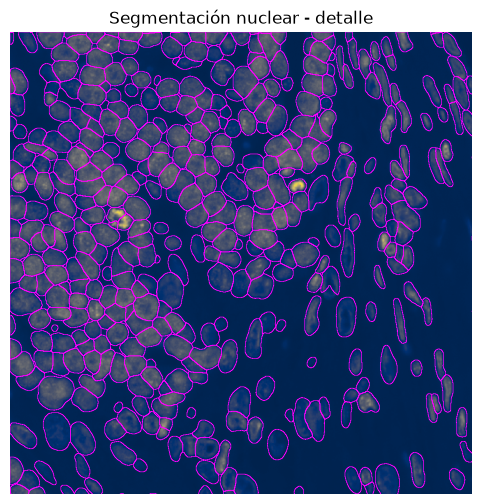

In [ ]:
# Definimos una región concreta del tejido para ver de forma más detallada la segmentación:
min_x = 10000
max_x = 11000
min_y = 18000
max_y = 19000

# Normalizamos el contraste de la imagen para facilitar su visualización:
norm = Normalize(vmax=5000, clip=False)

shapes_name = "nucleus_segmentation_mask_boundaries"

# Hacemos un subset para cargar solo los elementos de interés (la imagen con el canal DAPI y la máscara de segmentación de núcleos):
sdata_crop = sdata_filtered.subset(element_names=["morphology_focus_global", shapes_name])

# Definimos la región de la imagen que queremos comprobar en detalle:
sdata_crop = sdata_crop.query.bounding_box(
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

# Iniciamos la figura de matplotlib:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

ax = (
    sdata_crop.pl.render_images(
        element="morphology_focus_global",
        cmap="cividis",
        channel="DAPI",
        norm=norm,
    )
    .pl.render_shapes(
        element=shapes_name,
        fill_alpha=0,
        outline_width=0.5,
        outline_alpha=1,
        outline_color="magenta",
    )
    .pl.show(
        title="Segmentación nuclear - detalle",
        coordinate_systems="global",
        colorbar=False,
        ax=ax,
        return_ax=True,
    )
)

ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)
ax.invert_yaxis()
ax.axis("off")

In [ ]:
# Podemos usar también el visualizador interactivo Napari para explorar las imágenes y la máscara de segmentación.
interactive = Interactive(sdata=sdata_filtered)

# Abrimos la aplicación:
interactive.run()


## 2.2. Expansión hacia el citoplasma
Una vez realizada la segmentación de los núcleos, el algoritmo de Xenium realiza una expansión de la máscara hacia el citoplasma. Esa expansión simplemente aproxima el tamaño de la célula expandiendo la máscara de los núcleos una distancia predeterminada de 15 μm (5 μm en las últimas versiones del software). Procedemos a realizar el mismo proceso usando `Harpy`.

In [28]:
# Vamos a expandir el núcleo 5 μm, como en las últimas versiones de Xenium. Calculamos la equivalencia en píxeles:
distance = 5/microns_per_pixel

print(f"La distancia de expansión es de {round(distance,0)} píxeles")


La distancia de expansión es de 24.0 píxeles


In [ ]:
# Procedemos a realizar la expansión:
sdata_filtered = hp.im.expand_labels(
    sdata_filtered,
    labels_name="nucleus_segmentation_mask",
    distance=24,  # La distancia a expandir desde el núcleo.
    output_labels_name="nucleus_segmentation_mask_expanded",
    output_shapes_name="nucleus_segmentation_mask_expanded_boundaries",
    overwrite=True,
)

2026-09-01 17:00:13.897 | INFO     | harpy.image.segmentation._map:_combine_dask_arrays:339 - Linking labels across chunks.
2026-09-01 17:00:13.941 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'nucleus_segmentation_mask_expanded'
no parent found for <ome_zarr.reader.Label object at 0x7f78d4016480>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78c80c5310>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78f4305d30>: None
2026-09-01 17:00:23.047 | WARNING  | harpy.utils._io:_incremental_io_on_disk:86 - Element with name 'nucleus_segmentation_mask_expanded' already exists. Overwriting...
no parent found for <ome_zarr.reader.Label object at 0x7f78f42eade0>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78f4755b80>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78f41af6b0>: None
2026-09-01 17:00:30.035 | INFO     | harpy.shape._manager:_mask_to_polygons_rasterio:338 - Finished vectorizing. Dissol

(np.float64(10000.0),
 np.float64(11000.0),
 np.float64(19000.0),
 np.float64(18000.0))

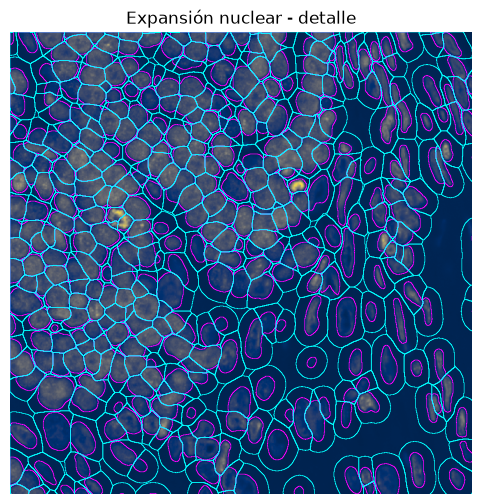

In [ ]:
# Definimos la misma región del tejido para comparar imágenes:
min_x = 10000
max_x = 11000
min_y = 18000
max_y = 19000

# Normalizamos el contraste de la imagen para facilitar su visualización:
norm = Normalize(vmax=5000, clip=False)

# Cargamos la máscara de segmentación nuclear y la nueva máscara expandida:
shapes_name = "nucleus_segmentation_mask_boundaries"
shapes_name_expanded = "nucleus_segmentation_mask_expanded_boundaries"

# Dibujamos la misma región mostrada durante de la segmentación nuclear para comparar:
sdata_crop = sdata_filtered.subset(element_names=["morphology_focus_global", shapes_name, shapes_name_expanded])

sdata_crop = sdata_crop.query.bounding_box(
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

fig, ax = plt.subplots(figsize=(6, 6))

sdata_crop.pl.render_images(
    element="morphology_focus_global",
    cmap="cividis",
    channel="DAPI",
    norm=norm,
).pl.render_shapes(
    element="nucleus_segmentation_mask_boundaries",
    fill_alpha=0,
    outline_width=0.5,
    outline_alpha=1,
    outline_color="magenta",
).pl.render_shapes(
    element="nucleus_segmentation_mask_expanded_boundaries",
    fill_alpha=0,
    outline_width=0.5,
    outline_alpha=1,
    outline_color="cyan",
).pl.show(
    title="Expansión nuclear - detalle",
    coordinate_systems="global",
    colorbar=False,
    ax=ax,
)

ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)
ax.invert_yaxis()
ax.axis("off")

Finalmente, podemos comparar la segmentación celular que hemos realizado mediante este método, y la aportada por 10x Genomics con el set de datos (que, como se indica en la introducción, tiene en cuenta otra información aportada, como la tinción citoplasmática o de membrana).

(np.float64(10000.0),
 np.float64(11000.0),
 np.float64(19000.0),
 np.float64(18000.0))

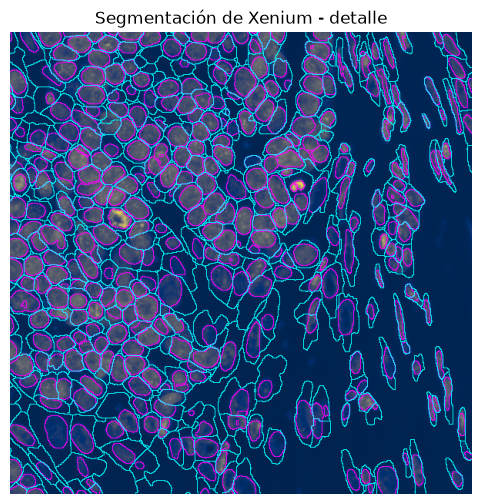

In [ ]:
# Definimos la misma región del tejido para comparar imágenes:
min_x = 10000
max_x = 11000
min_y = 18000
max_y = 19000

# Normalizamos el contraste de la imagen para facilitar su visualización:
norm = Normalize(vmax=5000, clip=False)

# Basándonos en el set de datos original (sdata_original), cargamos las etiquetas correspondientes a los núcleos y las células:
labels_nuclei = "nucleus_labels_global"
labels_cells = "cell_labels_global"

sdata_crop = sdata_original.subset(element_names=["morphology_focus_global", labels_nuclei, labels_cells])

sdata_crop = sdata_crop.query.bounding_box(
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

fig, ax = plt.subplots(figsize=(6, 6))

sdata_crop.pl.render_images(
    element="morphology_focus_global",
    cmap="cividis",
    channel="DAPI",
    norm=norm,
).pl.render_labels( # Hay que usar la función correspondiente a labels, no son shapes.
    element=labels_nuclei,
    fill_alpha=0,
    color="magenta",
    outline_alpha=1,
).pl.render_labels(
    element=labels_cells,
    fill_alpha=0,
    color="cyan",
    outline_alpha=1,
).pl.show(
    title="Segmentación de Xenium - detalle",
    coordinate_systems="global",
    colorbar=False,
    ax=ax,
)

ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)
ax.invert_yaxis()
ax.axis("off")

# 3. Segmentación mediante Cellpose
El proceso de segmentación celular mediante `Cellpose` es similar al realizado anteriormente para la segmentación nuclear. En lugar de usar el modelo de segmentación de núcleos, usaremos el modelo celular.

Para ello, `Cellpose` necesita información de dos canales:
- Un marcador de membrana o citoplasmático.
- Un marcador nuclear (DAPI).

Por lo tanto, en primer lugar tenemos que indicar a `Cellpose` qué canales de la imagen de morfología debe mirar para obtener dicha información.

In [ ]:
# Primero extraemos los datos de la imagen de morfología para poder leer los canales:
se = hp.im.get_dataarray(sdata_filtered, element_name="morphology_focus_global")

# Para que Cellpose inicie la segmentación, hay que aportarle una lista donde se le indique en primera posición el canal
# que corresponde al marcador de membrana, y en segunda el canal del marcador nuclear.
# Por lo tanto, creamos una nueva lista y buscamos en el índice de canales de la imagen de morfología el canal correspondiente
# a los marcadores de membrana (ATP1A1_CD45_E-Cadherin) y al marcador nuclear (DAPI). Las listas de Python empiezan siempre
# desde 0, pero Cellpose cuenta a partir de 1, por lo que es necesario sumar 1 a cada elemento.
channels_idx = [
    se.c.data.tolist().index("ATP1A1_CD45_E-Cadherin") + 1,
    se.c.data.tolist().index("DAPI") + 1,
]

print("Los canales que usará Cellpose son:", channels_idx)

Los canales que usará Cellpose son: [2, 1]


Tras determinar los canales que vamos a usar en la segmentación, podemos iniciar la segmentación de manera similar a como lo hicimos con la segmentación nuclear. No obstante, en el parámetro `diameter`, tenemos que aportar el tamaño esperado para las células, en píxeles. Podemos aportar un valor aproximado midiendo el diámetro de varias células en el visor interactivo `Napari`, usando la imagen `morphology_focus_global` en el canal correspondiente a la tinción de membrana (`ATP1A1_CD45_E-Cadherin`), y calculando el valor medio.

In [34]:
# Anotamos el diámetro aproximado (en píxeles) de varias células medidas en Napari:
cell_diameters = [54, 66, 42, 40, 37, 68, 47, 47, 38]

# Calculamos el valor medido y lo redondeamos a un valor entero:
diameter = round(sum(cell_diameters) / len(cell_diameters))

print(f"El diámetro medio de las células del tejido es de {diameter} píxeles.")

El diámetro medio de las células del tejido es de 49 píxeles.


In [ ]:
# Procedemos a realizar la segmentación celular con Cellpose:
sdata_filtered = hp.im.segment(
    sdata_filtered,
    image_name="morphology_focus_global",
    chunks=None,
    depth=200,
    model=hp.im.cellpose_callable,
    pretrained_model="cyto3", # Usamos "cyto3" para segmentación celular.
    device=device, # El que definimos para el anterior proceso de segmentación.
    diameter=diameter, # El valor medio del diámetro celular, calculado en la célula anterior.
    flow_threshold=0.9,
    cellprob_threshold=-4,
    channels=channels_idx,
    output_labels_name="cellpose_segmentation_mask",
    output_shapes_name="cellpose_segmentation_mask_boundaries",
    crd=None,
    overwrite=True,
)

# Cerramos el cluster una vez que hemos terminado de usar Cellpose y Dask:
client.close()
cluster.close()

2026-09-01 17:38:43.020 | INFO     | harpy.image.segmentation._segmentation:_segment:681 - Linking labels across chunks.
2026-09-01 17:38:43.048 | INFO     | harpy.image._manager:add_element:47 - Writing results to element 'cellpose_segmentation_mask'
no parent found for <ome_zarr.reader.Label object at 0x7f78f43924e0>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78f43b4770>: None
no parent found for <ome_zarr.reader.Label object at 0x7f78f43907d0>: None
2026-09-01 17:38:59.633 | INFO     | harpy.shape._manager:_mask_to_polygons_rasterio:338 - Finished vectorizing. Dissolving shapes at the border of the chunks. This can take a couple minutes if input mask contains many chunks.
2026-09-01 17:39:01.217 | INFO     | harpy.shape._manager:_mask_to_polygons_rasterio:344 - Dissolve is done.
2026-09-01 17:39:04,951 - distributed.nanny - INFO - Closing Nanny at 'tcp://127.0.0.1:38799'. Reason: nanny-close
2026-09-01 17:39:04,951 - distributed.nanny - INFO - Nanny asking worker

In [ ]:
# Comprobamos que el objeto ahora contiene la máscara de segmentación generada mediante Cellpose:
print(sdata_filtered)

SpatialData object, with associated Zarr store: /home/parselord/tfm_data/data/sdata_filtered.zarr
├── Images
│     ├── 'he_image_global': DataTree[cyx] (3, 7820, 7820), (3, 3910, 3910), (3, 1955, 1954), (3, 978, 977), (3, 489, 489)
│     └── 'morphology_focus_global': DataTree[cyx] (4, 10000, 10000), (4, 5000, 5000), (4, 2500, 2500), (4, 1250, 1250), (4, 625, 625)
├── Labels
│     ├── 'cellpose_segmentation_mask': DataArray[yx] (10000, 10000)
│     ├── 'nucleus_segmentation_mask': DataArray[yx] (10000, 10000)
│     └── 'nucleus_segmentation_mask_expanded': DataArray[yx] (10000, 10000)
├── Points
│     └── 'transcripts_global': DataFrame with shape: (13028066, 3) (2D points)
└── Shapes
      ├── 'cellpose_segmentation_mask_boundaries': GeoDataFrame shape: (36509, 1) (2D shapes)
      ├── 'fallopian_tube': GeoDataFrame shape: (1, 3) (2D shapes)
      ├── 'necrosis': GeoDataFrame shape: (15, 3) (2D shapes)
      ├── 'nucleus_segmentation_mask_boundaries': GeoDataFrame shape: (37096, 1) (2

(np.float64(10000.0),
 np.float64(11000.0),
 np.float64(19000.0),
 np.float64(18000.0))

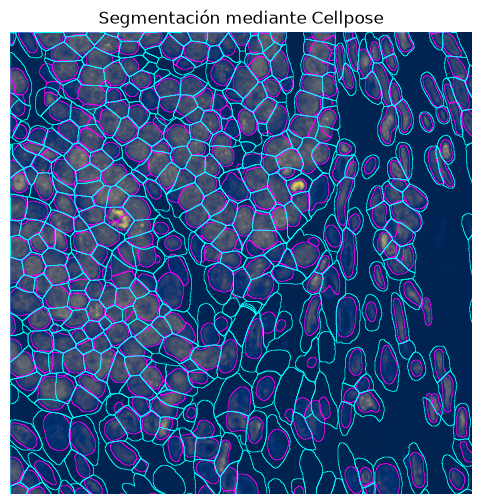

In [ ]:
# Ploteamos la máscara para comprobar que ha funcionado correctamente.
# Definimos la misma región del tejido para comparar imágenes:
min_x = 10000
max_x = 11000
min_y = 18000
max_y = 19000

# Normalizamos el contraste de la imagen para facilitar su visualización:
norm = Normalize(vmax=5000, clip=False)

shapes_name_nuclei = "nucleus_segmentation_mask_boundaries"
shapes_name = "cellpose_segmentation_mask_boundaries"

# Hacemos un subset para cargar solo la información de interés:
sdata_crop = sdata_filtered.subset(element_names=["morphology_focus_global", shapes_name_nuclei, shapes_name])

sdata_crop = sdata_crop.query.bounding_box(
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

ax = (
    sdata_crop.pl.render_images(
        element="morphology_focus_global",
        cmap="cividis",
        channel="DAPI",
        norm=norm,
    )
    .pl.render_shapes(
        element=shapes_name_nuclei,
        fill_alpha=0,
        outline_width=0.5,
        outline_alpha=1,
        outline_color="magenta",
    )
    .pl.render_shapes(
            element=shapes_name,
            fill_alpha=0,
            outline_width=0.5,
            outline_alpha=1,
            outline_color="cyan",
        )
    .pl.show(
        title="Segmentación mediante Cellpose",
        coordinate_systems="global",
        colorbar=False,
        ax=ax,
        return_ax=True,
    )
)

ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)
ax.invert_yaxis()
ax.axis("off")

# 4. Segmentación mediante Baysor

La herramienta de segmentación `Baysor` está escrita en Julia. Para el presente trabajo se ha instalado la versión [cpp-0.8.3](https://github.com/kharchenkolab/Baysor/releases/tag/cpp-0.8.3) de la herramienta. Dicha herramienta se ejecuta desde la terminal y requiere que se le aporte un archivo CSV con las coordenadas de todos los transcritos y el gen al que corresponden. Adicionalmente, se puede aportar una segmentación previa para facilitar la detección de los núcleos o células.

El funcionamiento de la herramienta y los distintos argumentos se pueden comprobar [en la documentación](https://kharchenkolab.github.io/Baysor/dev/segmentation/).

Vamos a realizar la segmentación con `Baysor` de 3 maneras distintas:
- Segmentación básica, sin usar información previa.
- Aportando la máscara de segmentación nuclear generada mediante `Cellpose`.
- Aportando la máscara de segmentación celular generada mediante `Cellpose`.

En primer lugar, es necesario extraer la información de coordenadas de los transcritos del objeto `SpatialData`, así como las máscaras de segmentación mencionadas, para aportarlas posteriormente a `Baysor`.

In [ ]:
# Primero extraemos las máscaras (los arrays) correspondientes a la segmentación nuclear y celular con Cellpose a archivos .tiff:
labels_to_export = ["nucleus_segmentation_mask", "cellpose_segmentation_mask"]

for item in labels_to_export:
    # Extraemos la matriz de etiquetas en formato Dask:
    mask_dask = sdata_filtered.labels[item].data

    # Pasamos la matriz de formato Dask a Numpy.
    # Lo forzamos a tipo uint32 para que soporte más de 65.000 células sin desbordarse.
    mask_numpy = mask_dask.compute().astype(np.uint32)

    # Guardamos la imagen TIFF:
    path_tiff = BAYSOR_INPUTS_DIR / f"{item}.tif"
    tifffile.imwrite(path_tiff, mask_numpy)
    print(f"Máscara guardada en: {path_tiff}")

# A continuación extraemos las coordenadas de los transcritos a un archivo .csv.

# Transformamos el data frame de Dask a un data frame de Pandas:
df_transcripts = sdata_filtered.points["transcripts_global"].compute()

# Como se indicó en la primera sección, las coordenadas de las imágenes y los transcritos comienzan en (x=10000, y=18000).
# Dado que al extraer las máscaras como imágenes .tiff las coordenadas de cada pixel se resetean a (0,0), debemos hacer
# coincidir las coordenadas de los transcritos con las nuevas coordenadas de las imágenes. Para ello, aplicamos el offset exacto
# restando a las coordenadas de cada transcrito los valores de inicio de x y de y.
x_min, y_min = 10000, 18000
df_transcripts["x_local"] = df_transcripts["x"] - x_min
df_transcripts["y_local"] = df_transcripts["y"] - y_min

# Seleccionamos las columnas que Baysor necesita y las renombramos para facilitar su lectura:
df_baysor = df_transcripts[["x_local", "y_local", "gene"]].copy()
df_baysor.rename(columns={"x_local": "x", "y_local": "y", "gene": "gene"}, inplace=True)

# Guardamos el CSV:
path_csv = BAYSOR_INPUTS_DIR / "transcripts_aligned.csv"
df_baysor.to_csv(path_csv, index=False)
print(f"Transcritos guardados en: {path_csv}")

Máscara guardada en: ./data/inputs_for_baysor/nucleus_segmentation_mask.tif
Máscara guardada en: ./data/inputs_for_baysor/cellpose_segmentation_mask.tif
Transcritos guardados en: ./data/inputs_for_baysor/transcripts_aligned.csv


## 4.1. Segmentación con Baysor sin *prior* (información previa)
En la [documentación](https://kharchenkolab.github.io/Baysor/dev/segmentation/) de `Baysor` se pueden consultar el comando y los distintos argumentos que hay que aportar. En particular, hay dos parámetros importantes que ajustar: 
- `-m, --min-molecules-per-cell`. Indica el número mínimo de transcritos que tiene que haber dentro de un mismo vecindario para ser considerado una célula. En la bibliografía ([Rose et al. 2026](https://doi.org/10.64898/2026.04.16.718947)) se menciona por lo general un valor de 20 o 30 transcritos. Tras varias pruebas, en este trabajo se ha determinado un valor de 30 para este argumento.
-  `-s, --scale`. Indica el radio aproximado que deberían tener las células, en las mismas unidades en las que están las coordenadas de los transcritos (en píxeles). Dado que para la segmentación con `Cellpose` definimos un diámetro de 49 píxeles, daremos un valor de 25 píxeles a este parámetro.

Adicionalmente, se emplean también los siguientes argumentos:
- `JULIA_NUM_THREADS` indica el número de hilos que podemos aplicar al procesamiento, depende del procesador donde se estén realizando los cálculos.
- `-x`, `-y` y `-g` se utilizan para indicar los nombres de las columnas del .csv correspondientes a las coordenadas X, Y y los nombres de los genes a los que pertenecen los transcritos.
- `-p` indica que genere un reporte con varios diagnósticos sobre el proceso de segmentación.
- `-o` indica la ruta donde guardar los resultados.

Tras los argumentos, se debe indicar la ruta al archivo .csv que contiene las coordenadas de los transcritos, y posteriormente, la ruta al archivo .tiff que se empleará como *prior*.

En primer lugar realizaremos la segmentación sin aportar ninguna segmentación previa. En la terminal, desde la carpeta donde se encuentra el presente script, escribimos:
```bash
mkdir results/baysor_results/baysor_no_prior
JULIA_NUM_THREADS=30 baysor run -x x -y y -g gene -s 25 -m 30 -p -o results/baysor_results/baysor_no_prior data/inputs_for_baysor/transcripts_aligned.csv
```

También se puede llevar a cabo ejecutando el script en bash correspondiente:
```bash
bash ./baysor_no_prior_segmentation.sh
```

## 4.2. Segmentación con Baysor usando la máscara de segmentación nuclear como *prior*

Para aportar la máscara de segmentación nuclear como *prior*, simplemente se indica la ruta al archivo .tif al final del comando. Mediante el argumento `--prior-segmentation-confidence` podemos indicar cómo de fiable es la segmentación previa aportada. Un valor de 0 indica a la herramienta que no tenga en cuenta la segmentación previa, mientras que un valor de 1 indica que no debe modificar la segmentación previa aportada. Se suele aportar un valor entre 0.2 y 0.7. Dado que la máscara que vamos a aportar solo corresponde a los núcleos, empleamos un valor bajo, de 0.2. De esta manera, el algoritmo identificará los núcleos como los centros de las células, pero tendrá más libertad a la hora de ajustar los límites celulares.

El comando completo para esta segmentación es el siguiente:
```bash
mkdir results/baysor_results/baysor_nuclear_mask_prior
JULIA_NUM_THREADS=30 baysor run -x x -y y -g gene -s 25 -m 30 -p --prior-segmentation-confidence 0.2 -o results/baysor_results/baysor_nuclear_mask_prior data/inputs_for_baysor/transcripts_aligned.csv data/inputs_for_baysor/nucleus_segmentation_mask.tif
```

También se puede llevar a cabo ejecutando el script en bash correspondiente:
```bash
bash ./baysor_nuclear_mask_prior_segmentation.sh
```

## 4.3. Segmentación con Baysor usando la máscara de segmentación celular de Cellpose como *prior*

A diferencia de la máscara de segmentación de núcleos, la segmentación celular completa con `Cellpose` es más fiable, por lo que determinaremos el valor de `--prior-segmentation-confidence` en `0.7`.

El comando completo para esta segmentación es el siguiente:
```bash
mkdir results/baysor_results/baysor_cellpose_cito_prior
JULIA_NUM_THREADS=30 baysor run -x x -y y -g gene -s 25 -m 30 -p --prior-segmentation-confidence 0.7 -o results/baysor_results/baysor_cellpose_cito_prior data/inputs_for_baysor/transcripts_aligned.csv data/inputs_for_baysor/cellpose_segmentation_mask.tif
```

También se puede llevar a cabo ejecutando el script en bash correspondiente:
```bash
bash ./baysor_cellpose_cito_prior_segmentation.sh
```

## 4.4. Incorporación de las máscaras de segmentación celular de Baysor al objeto SpatialData

Una vez finalizados los procesos de segmentación en `Baysor`, hay que incorporar los nuevos polígonos generados. Dado que para extraer las imágenes tuvimos que corregir las coordenadas restando el offset existente, ahora hay que hacer el paso inverso para que las máscaras coincidan con los demás objetos presentes en nuestro SpatialData.

In [ ]:
# Definimos una lista con las nuevas máscaras que vamos a importar:
new_masks = ["baysor_no_prior", "baysor_nuclear_mask_prior", "baysor_cellpose_cito_prior"]

# Definimos una función auxiliar para trasladar cada polígono a su coordenada original.
# En xoff y en yoff añadimos el offset exacto que restamos previamente a las coordenadas de los transcritos del .csv:
def restore_translation(geom):
    return affinity.translate(geom, xoff=10000, yoff=18000)

# Creamos un bucle para importar las tres máscaras, aplicando la transformación en las coordenadas:
for item in new_masks:
    # Cargamos los polígonos generados por Baysor:
    path_baysor_geojson = BAYSOR_OUTPUTS_DIR / f"{item}/segmentation_polygons_2d.json" 
    gdf_baysor = gpd.read_file(path_baysor_geojson)

    # Aplicamos la función creada anteriormente:
    gdf_baysor["geometry"] = gdf_baysor["geometry"].apply(restore_translation)
    # Añadimos las formas alineadas al objeto sdata_filtered:
    sdata_filtered = hp.sh.add_shapes(
        sdata_filtered, 
        input=gdf_baysor, 
        output_shapes_name=f"{item}_segmentation_boundaries", 
        overwrite=True
    )

# Comprobamos que se han añadido las máscaras correctamente:
print(sdata_filtered)

SpatialData object, with associated Zarr store: /home/parselord/software/tfm_data/data/sdata_filtered.zarr
├── Images
│     ├── 'he_image_global': DataTree[cyx] (3, 7820, 7820), (3, 3910, 3910), (3, 1955, 1954), (3, 978, 977), (3, 489, 489)
│     └── 'morphology_focus_global': DataTree[cyx] (4, 10000, 10000), (4, 5000, 5000), (4, 2500, 2500), (4, 1250, 1250), (4, 625, 625)
├── Labels
│     ├── 'cellpose_segmentation_mask': DataArray[yx] (10000, 10000)
│     ├── 'nucleus_segmentation_mask': DataArray[yx] (10000, 10000)
│     └── 'nucleus_segmentation_mask_expanded': DataArray[yx] (10000, 10000)
├── Points
│     └── 'transcripts_global': DataFrame with shape: (13028066, 3) (2D points)
└── Shapes
      ├── 'baysor_cellpose_cito_prior_segmentation_boundaries': GeoDataFrame shape: (39260, 3) (2D shapes)
      ├── 'baysor_no_prior_segmentation_boundaries': GeoDataFrame shape: (77781, 3) (2D shapes)
      ├── 'baysor_nuclear_mask_prior_segmentation_boundaries': GeoDataFrame shape: (57006, 3) 

Podemos crear gráficas de las nuevas máscaras para ver si se han importado correctamente.

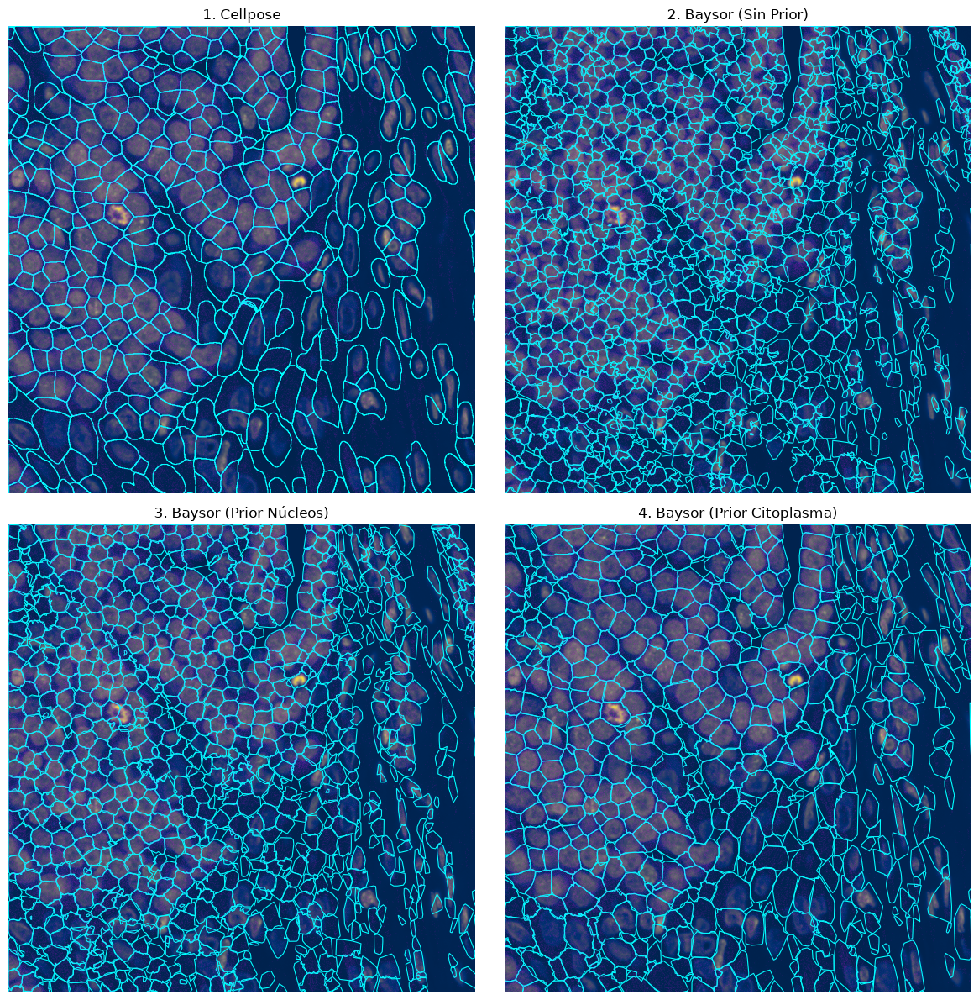

In [ ]:
# 1. Definimos la misma región de interés y los parámetros de normalización:
min_x, max_x = 10000, 11000
min_y, max_y = 18000, 19000
norm = Normalize(vmax=5000, clip=False)

# 2. Hacemos el recorte (bounding box) sobre el objeto completo:
sdata_crop = sdata_filtered.query.bounding_box(
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

# 3. Definimos las máscaras que vamos a dibujar:
mask_cellpose = "cellpose_segmentation_mask_boundaries"
mask_baysor_no_prior = "baysor_no_prior_segmentation_boundaries" 
mask_baysor_nuclei = "baysor_nuclear_mask_prior_segmentation_boundaries" 
mask_baysor_cyto = "baysor_cellpose_cito_prior_segmentation_boundaries"

# 4. Creamos la figura con los 4 subplots:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 12))

# 5. Creamos un diccionario que asocia: Título de la gráfica -> (Nombre de la máscara, Subplot correspondiente):
plot_config = {
    "1. Cellpose": (mask_cellpose, ax1),
    "2. Baysor (Sin Prior)": (mask_baysor_no_prior, ax2),
    "3. Baysor (Prior Núcleos)": (mask_baysor_nuclei, ax3),
    "4. Baysor (Prior Citoplasma)": (mask_baysor_cyto, ax4)
}

# 6. Preparamos el bucle de renderizado:
for title, (mask_name, ax) in plot_config.items():
    # Renderizamos imagen + la máscara específica de esa iteración + transcritos:
    (
        sdata_crop.pl.render_images(
            element="morphology_focus_global",
            cmap="cividis",
            channel="DAPI",
            norm=norm,
        )
        .pl.render_shapes(
            element=mask_name,
            fill_alpha=0,
            outline_width=0.8,
            outline_alpha=1,
            outline_color="cyan",
        )
        .pl.render_points(
            element="transcripts_global",
            color="magenta", 
            size=0.01, 
            alpha=0.6,
        )
        .pl.show(
            title=title,
            coordinate_systems="global",
            colorbar=False,
            ax=ax,
        )
    )
    
    # Aplicamos los límites y ajustes de ejes a cada subplot:
    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)
    ax.invert_yaxis()
    ax.axis("off")

# Ajustamos el espaciado para que no se superpongan los títulos:
plt.tight_layout()
plt.show()

# 5. Análisis visual de las máscaras de segmentación

Como se mencionó anteriormente, podemos explorar el tejido y las máscaras de segmentación usando Napari, para comprobar posibles diferencias en el proceso de segmentación en función de las zonas del tejido. Posteriormente, podemos exportar una región de interés con las máscaras de segmentación creadas usando `matplotlib`.

In [ ]:
# Lanzamos el visor Napari con el objeto sdata_filtered:
interactive = Interactive(sdata_filtered)
interactive.run()

Una vez determinada la región de interés, procedemos a extraer las imágenes con `matplotlib` para su análisis en el apartado de resultados y discusión.

Imagen guardada en ./results/images/vista_general_fluorescencia.tiff


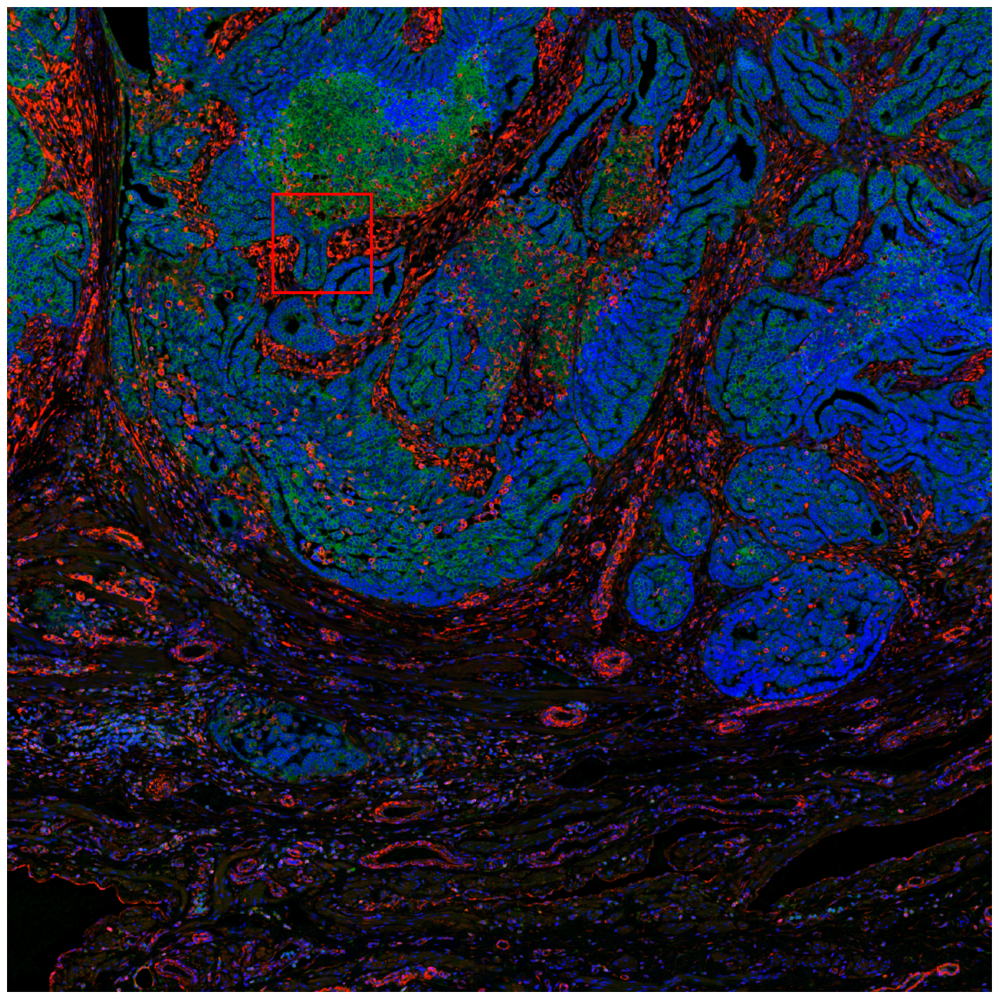

In [ ]:
# En primer lugar extraemos una imagen completa del tejido (la de morfología con marcaje de fluorescencia),
# y un recuadro que indique la posición donde vamos a ampliar para mostrar las diferencias entre las distintas máscaras de segmentación.

# Inicializamos la figura con un tamaño grande para apreciar el tejido:
fig, ax = plt.subplots(figsize=(14, 14))

# Forzamos a que la imagen ocupe el 100% de la figura, sin márgenes:
plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
ax.margins(0, 0)
ax.xaxis.set_major_locator(plt.NullLocator())
ax.yaxis.set_major_locator(plt.NullLocator())

# Renderizamos la imagen completa, pero solo con los canales correspondientes a DAPI,
# marcadores de membrana (ATP1A1_CD45_E-Cadherin) y marcadores de células del estroma (AlphaSMA_Vimentin):
(
    sdata_filtered.pl.render_images(
        "morphology_focus_global",
        channel=['DAPI', 'ATP1A1_CD45_E-Cadherin', 'AlphaSMA_Vimentin'],
        palette=["blue", "green", "red"], 
        alpha=1.0,
        norm=PercentileNormalize(1, 99) # Aumentamos el brillo para que se vea bien en la figura
    )
    .pl.show(ax=ax, coordinate_systems="global")
)

# Indicamos las coordenadas de la región de interés que determinamos previamente en Napari:
y_min, y_max = 19900, 20900
x_min, x_max = 12700, 13700

width_roi = x_max - x_min
height_roi = y_max - y_min

# Dibujamos el recuadro rojo que delimita la región de interés usando el módulo patches de matplotlib.
# patches.Rectangle toma la esquina (x_min, y_min) y sus dimensiones:
rectangle_roi = patches.Rectangle(
    (x_min, y_min), 
    width_roi, 
    height_roi,
    linewidth=3,         # Grosor de la línea.
    edgecolor='red',     # Color del borde.
    facecolor='none',    # Interior transparente.
    linestyle='-'        # Línea continua.
)

# Añadimos el recuadro a los ejes de la imagen:
ax.add_patch(rectangle_roi)

# Ocultamos el título:
ax.set_title("")

# Ocultamos todo rastro de ejes:
plt.axis("off")  

# Exportamos la imagen a un archivo .tiff de alta resolución:
tiff_path = IMAGE_DIR / "vista_general_fluorescencia.tiff"
plt.savefig(
    tiff_path, 
    format="tiff", 
    dpi=300,
    bbox_inches="tight", 
    pad_inches=0,
    transparent=True
)

print(f"Imagen guardada en {tiff_path}")

Imagen guardada en: ./results/images/vista_general_he.tiff


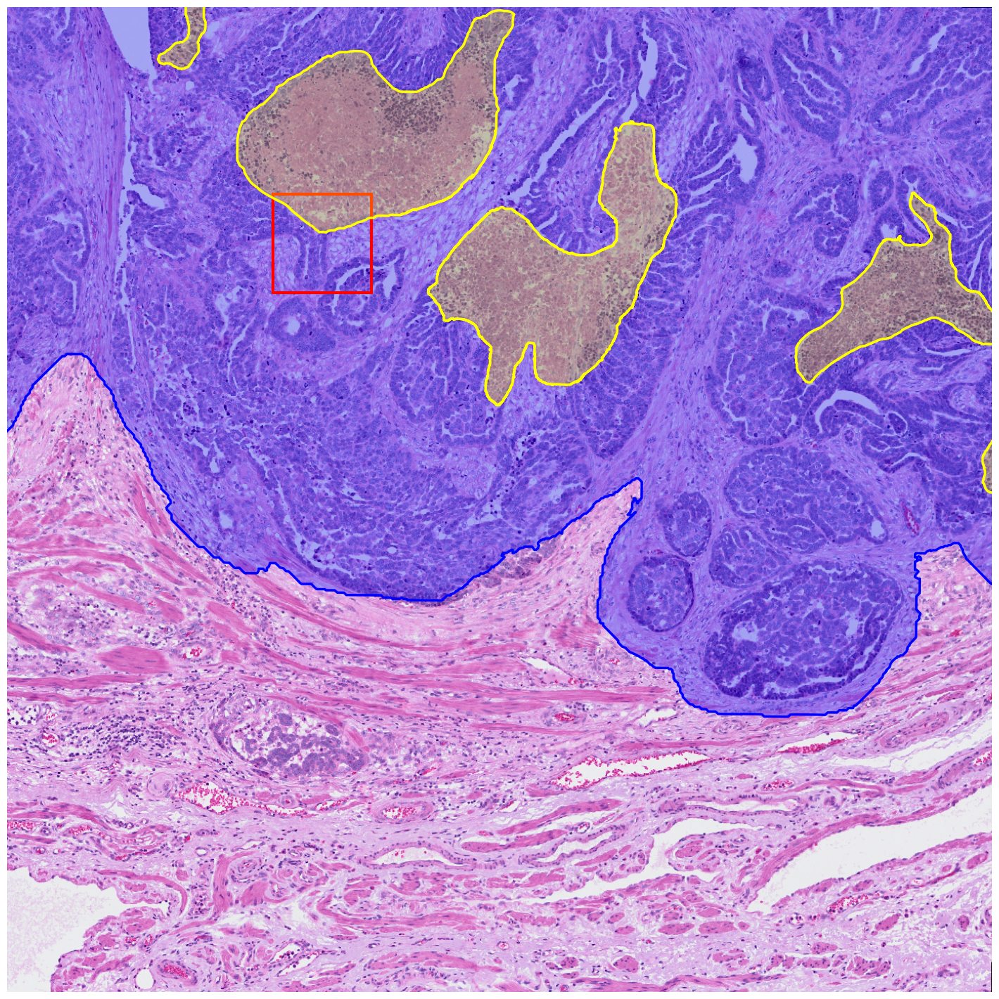

In [ ]:
# Creamos también una visión general del tejido en H&E, con el recuadro rojo que delimita la ROI, y
# las regiones correspondientes a tumor y necrosis anotadas en el objeto.

fig, ax = plt.subplots(figsize=(14, 14))
plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
ax.margins(0, 0)
ax.xaxis.set_major_locator(plt.NullLocator())
ax.yaxis.set_major_locator(plt.NullLocator())

# Renderizamos la imagen H&E y las shapes correspondientes a tumor y necrosis:
(
    sdata_filtered.pl.render_images(
        "he_image_global"
    )
    .pl.render_shapes(
        "tumor",
        color="blue",
        fill_alpha=0.3,
        outline_color="blue",
        outline_width=2.5
    )
    .pl.render_shapes(
        "necrosis",
        color="yellow",
        fill_alpha=0.3,
        outline_color="yellow",
        outline_width=2.5
    )
    .pl.show(ax=ax, coordinate_systems="global")
)

# Las anotaciones de las regiones de tumor y necrosis se extienden a todo el tejido, no solo al subset
# que estamos empleando. Hay que definir los límites de la imagen correspondientes al subset para evitar
# que se cree una imagen con las regiones representadas fuera de los límites de nuestro subset.
img_x_min, img_x_max = 10000, 20000
img_y_min, img_y_max = 18000, 28000

# Forzamos los límites de los ejes. Importante: hay que invertir el eje y, ya que los datos de imágenes espaciales
# tienen el origen en la esquina superior izquierda, mientras que matplotlib lo tiene en la inferior izquierda (sigue coordenadas cartesianas).
ax.set_xlim(img_x_min, img_x_max)
ax.set_ylim(img_y_max, img_y_min)

# Dibujamos el recuadro rojo de manera similar a como lo hicimos en la imagen de fluorescencia:
roi_x_min, roi_x_max = 12700, 13700
roi_y_min, roi_y_max = 19900, 20900

width_roi = roi_x_max - roi_x_min
height_roi = roi_y_max - roi_y_min

rectangle_roi = patches.Rectangle(
    (roi_x_min, roi_y_min), 
    width_roi, 
    height_roi,
    linewidth=3,         
    edgecolor='red',     
    facecolor='none',    
    linestyle='-'        
)

ax.add_patch(rectangle_roi)

ax.set_title("")
plt.axis("off")  

tiff_path = IMAGE_DIR / "vista_general_he.tiff"
plt.savefig(
    tiff_path, 
    format="tiff", 
    dpi=300, 
    bbox_inches="tight", 
    pad_inches=0,
    transparent=True
)

print(f"Imagen guardada en: {tiff_path}")

In [ ]:
# Por último, generamos una imagen de la ROI con cada máscara de segmentación para compararlas visualmente.

# Definimos las coordenadas de la ROI:
y_min, y_max = 19900, 20900
x_min, x_max = 12700, 13700

# Vamos a cargar tanto las máscaras generadas como la aportada por Xenium (que esta en sdata_original).
# Usamos la función bounding_box para recortar ambos objetos a las coordenadas de la ROI:
sdata_roi_filtered = sdata_filtered.query.bounding_box(
    axes=["x", "y"], min_coordinate=[x_min, y_min], max_coordinate=[x_max, y_max], target_coordinate_system="global"
)
sdata_roi_original = sdata_original.query.bounding_box(
    axes=["x", "y"], min_coordinate=[x_min, y_min], max_coordinate=[x_max, y_max], target_coordinate_system="global"
)

# Definimos una función para no repetir el mismo código de configuración de las imágenes en cada iteración:
def plot_conf_and_save(ax, fig, file_output):
    # Forzamos los límites de la imagen a las coordenadas exactas de la ROI:
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min) 
    ax.set_title("")
    plt.subplots_adjust(top=1, bottom=0, right=1, left=0, hspace=0, wspace=0)
    ax.margins(0, 0)
    ax.xaxis.set_major_locator(plt.NullLocator())
    ax.yaxis.set_major_locator(plt.NullLocator())
    plt.axis("off")
    plt.savefig(IMAGE_DIR / file_output, format="tiff", dpi=300, bbox_inches="tight", pad_inches=0, transparent=True)
    plt.close(fig)
    print(f"Imagen guardada en {IMAGE_DIR / file_output}")

# Generamos la imagen correspondiente a la segmentación de Xenium:
fig, ax = plt.subplots(figsize=(10, 10))
(
    sdata_roi_original.pl.render_images(
        "morphology_focus_global",
        channel=['DAPI', 'ATP1A1/CD45/E-Cadherin', 'AlphaSMA/Vimentin'], # Los canales todavía no se habían renombrado en el objeto original:
        palette=["blue", "green", "red"],
        alpha=1.0
    )
    .pl.render_labels(
        "cell_labels_global",
        fill_alpha=0.0,
        outline=True,
        outline_alpha=1.0,
        outline_color="cyan"
    )
    .pl.show(ax=ax, coordinate_systems="global")
)
plot_conf_and_save(ax, fig, "roi_xenium_default.tiff")

# Creamos un diccionario para asociar las máscaras del objeto sdata_filtered con los nombres de los archivos a guardar:
masks_shapes = {
    "cellpose_segmentation_mask_boundaries": "roi_cellpose.tiff",
    "baysor_no_prior_segmentation_boundaries": "roi_baysor_noprior.tiff",
    "baysor_nuclear_mask_prior_segmentation_boundaries": "roi_baysor_nuclear_prior.tiff",
    "baysor_cellpose_cito_prior_segmentation_boundaries": "roi_baysor_cyto_prior.tiff",
    "nucleus_segmentation_mask_expanded_boundaries": "roi_nucleus_expanded.tiff"
}

# Iteramos sobre el diccionario para guardar el resto de máscaras:
for name, output_file in masks_shapes.items():
    fig, ax = plt.subplots(figsize=(10, 10))
    (
        sdata_roi_filtered.pl.render_images(
            "morphology_focus_global",
            channel=['DAPI', 'ATP1A1_CD45_E-Cadherin', 'AlphaSMA_Vimentin'],
            palette=["blue", "green", "red"],
            alpha=1.0
        )
        .pl.render_shapes(
            name,
            fill_alpha=0.0,           
            outline_color="cyan",     
            outline_width=1.0         
        )
        .pl.show(ax=ax, coordinate_systems="global")
    )
    plot_conf_and_save(ax, fig, output_file)

Imagen guardada en ./results/images/roi_xenium_default.tiff
Imagen guardada en ./results/images/roi_cellpose.tiff
Imagen guardada en ./results/images/roi_baysor_noprior.tiff
Imagen guardada en ./results/images/roi_baysor_nuclear_prior.tiff
Imagen guardada en ./results/images/roi_baysor_cyto_prior.tiff
Imagen guardada en ./results/images/roi_nucleus_expanded.tiff


# 6. Asignación de transcritos a células y preprocesado de los objetos AnnData

Una vez que tenemos preparadas las máscaras de segmentación, podemos asignar los transcritos a las células correspondientes, generando una matriz de conteos que, junto a otros datos, se guarda en un objeto de tipo `AnnData`. Debemos llevar a cabo esta asignación con las máscaras de segmentación creadas mediante el proceso clásico de Xenium (segmentación nuclear y posterior expansión citoplasmática) y con la máscara de segmentación de `Cellpose`. La máscara original aportada por Xenium ya tiene el objeto `AnnData` con la matriz de conteos creada, mientras que la segmentación con `Baysor` genera una serie de resultados que necesitan ser importados y adaptados al estándar `TableModel` de los objetos `AnnData` antes de poder ser utilizados en análisis posteriores.

En primer lugar comenzaremos por realizar el proceso de asignación de transcritos a células para las segmentaciones `cellpose_segmentation_mask` y `nucleus_segmentation_mask_expanded`.

In [5]:
# Usamos la función allocate de Harpy para asignar los transcritos a las células en función de las etiquetas.
# Primero usamos la segmentación nuclear y expansión citoplasmática:
sdata_filtered = hp.tb.allocate(
    sdata=sdata_filtered,
    labels_name="nucleus_segmentation_mask_expanded",
    points_name="transcripts_global",
    output_table_name="table_nucleus_expanded",
    to_coordinate_system="global",
    overwrite=True
)

# Repetimos usando la segmentación de Cellpose:
sdata_filtered = hp.tb.allocate(
    sdata=sdata_filtered,
    labels_name="cellpose_segmentation_mask",
    points_name="transcripts_global",
    output_table_name="table_cellpose",
    to_coordinate_system="global",
    overwrite=True
)

2026-09-16 15:18:38.530 | INFO     | harpy.table._allocation:_aggregate:494 - Calculating cell counts.
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
2026-09-16 15:19:07.511 | INFO     | harpy.table._allocation:_aggregate:494 - Calculating cell counts.
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Como se indica en el tutorial, la función `allocate` de `Harpy` también anota la tabla con una serie de metadatos que permite enlazar cada fila de la tabla con la segmentación original del objeto `SpatialData`:
>
> Inspect the SpatialData metadata stored in `.uns`.
>
> `hp.tb.allocate(...)` does not only create an AnnData count matrix, it also annotates the table so that SpatialData and Harpy know how each table row maps back to the segmentation. This metadata lives in `adata.uns[TableModel.ATTRS_KEY]`. In particular:
> - `TableModel.INSTANCE_KEY` gives the name of the `.obs` column holding the instance ids (for example `cell_ID`).
> - `TableModel.REGION_KEY_KEY` gives the name of the `.obs` column holding the region or labels-layer assignment for each row.
> - `TableModel.REGION_KEY` gives the labels element(s) in `sdata` that this table annotates.
>
> Together, these fields tell Harpy which segmentation layer to use and which label id within that layer corresponds to each row. This is what allows downstream functions and plotting utilities to keep the AnnData table synchronized with the SpatialData object.

Para los análisis posteriores es importante conocer la estructura de los objetos `AnnData`, para poder comprobar que dichos metadatos se han asignado correctamente, y en el caso de las segmentaciones que vamos a importar desde `Baysor`, para asignar dichos metadatos de manera correcta de manera manual.

In [6]:
# Comprobamos primero que table_nucleus_expanded se ha creado correctamente en el objeto sdata_filtered y 
# que sus metadatos se han asignado correctamente:
table = sdata_filtered.tables["table_nucleus_expanded"]

# Inspeccionamos la tabla generada:
display(table)

logger.info(
    f"Número de células: {len(table.obs.index)}",
)
logger.info(
    f"Número de genes: {len(table.var.index)}",
)

# Lista completa de metadatos de esta tabla.
logger.info(table.uns[TableModel.ATTRS_KEY])

# Nombre de la columna de observaciones (.obs) que correlaciona cada observación con la capa de segmentación (labels).
logger.info(f"Columna que asigna cada observación a una región: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY_KEY]}")

# Nombre de la columna de observaciones (.obs) que almacena los IDs de cada célula generada por la segmentación.
logger.info(f"Columna que almacena los IDs de cada instancia (célula): {table.uns[TableModel.ATTRS_KEY][TableModel.INSTANCE_KEY]}")

# Nombre de la capa de segmentación del objeto SpatialData que está siendo anotado por esta tabla.
# Debería coincidir con los valores que aparecen para cada célula en la columna correspondiente a "REGION_KEY_KEY".
logger.info(f"Capa de segmentación que está siendo anotada: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY]}")

# Comprobamos también la estructura de todas las columnas de la tabla en ".obs":
display(table.obs.head())

AnnData object with n_obs × n_vars = 37065 × 5101
    obs: 'cell_ID', 'fov_labels'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

2026-09-16 15:19:39.124 | INFO     | __main__:<module>:8 - Número de células: 37065
2026-09-16 15:19:39.126 | INFO     | __main__:<module>:11 - Número de genes: 5101
2026-09-16 15:19:39.129 | INFO     | __main__:<module>:16 - {'region_key': 'fov_labels', 'instance_key': 'cell_ID', 'region': ['nucleus_segmentation_mask_expanded']}
2026-09-16 15:19:39.130 | INFO     | __main__:<module>:19 - Columna que asigna cada observación a una región: fov_labels
2026-09-16 15:19:39.133 | INFO     | __main__:<module>:22 - Columna que almacena los IDs de cada instancia (célula): cell_ID
2026-09-16 15:19:39.134 | INFO     | __main__:<module>:26 - Capa de segmentación que está siendo anotada: ['nucleus_segmentation_mask_expanded']


,cell_ID,fov_labels
cells,,
1048_nucleus_segmentation_mask_expanded_eb6bc4f5,1048,nucleus_segmentation_mask_expanded
1080_nucleus_segmentation_mask_expanded_eb6bc4f5,1080,nucleus_segmentation_mask_expanded
1144_nucleus_segmentation_mask_expanded_eb6bc4f5,1144,nucleus_segmentation_mask_expanded
1176_nucleus_segmentation_mask_expanded_eb6bc4f5,1176,nucleus_segmentation_mask_expanded
1192_nucleus_segmentation_mask_expanded_eb6bc4f5,1192,nucleus_segmentation_mask_expanded


Tanto el objeto `AnnData` como sus metadatos presentan la estructura correcta.

In [7]:
# La sección ".var" contiene información sobre los genes detectados en la segmentación:
table.var.head()

""
A2ML1
AAMP
AAR2
AARSD1
ABAT


In [8]:
# La sección ".obsm" contiene información sobre las coordenadas espaciales del centroide de cada célula 
# calculado a partir de la media de los transcritos de dicha célula:
display(table.obsm["spatial"][0:5])

array([[19247.90410959, 26164.9086758 ],
       [18512.89583333, 26178.55555556],
       [18558.96460177, 26201.89380531],
       [18844.14285714, 26174.85714286],
       [18693.62790698, 26196.86046512]])

In [9]:
# Por último, podemos acceder a la matriz de expresión de genes (X) que contiene el número de transcritos detectados por célula y por gen.
# Dicha matriz contiene en las filas las células y en las columnas cada uno de los genes analizados, y cada valor indica cuántos
# transcritos se han detectado para dicho gen en la célula correspondiente a esa fila.
print(table.X)

<Compressed Sparse Row sparse matrix of dtype 'uint32'
	with 9140531 stored elements and shape (37065, 5101)>
  Coords	Values
  (0, 31)	1
  (0, 36)	1
  (0, 69)	1
  (0, 75)	3
  (0, 89)	1
  (0, 121)	2
  (0, 147)	1
  (0, 219)	1
  (0, 223)	4
  (0, 258)	2
  (0, 278)	2
  (0, 280)	1
  (0, 309)	1
  (0, 310)	1
  (0, 328)	1
  (0, 329)	1
  (0, 330)	1
  (0, 340)	1
  (0, 356)	1
  (0, 398)	3
  (0, 470)	2
  (0, 481)	1
  (0, 593)	1
  (0, 602)	1
  (0, 629)	2
  :	:
  (37062, 2451)	1
  (37062, 3397)	1
  (37062, 3605)	1
  (37062, 3968)	1
  (37062, 4343)	1
  (37063, 75)	1
  (37063, 231)	1
  (37063, 743)	1
  (37063, 828)	1
  (37063, 934)	1
  (37063, 1937)	1
  (37063, 2425)	1
  (37063, 2491)	1
  (37063, 2714)	1
  (37063, 2854)	1
  (37063, 3128)	1
  (37064, 1337)	1
  (37064, 1727)	1
  (37064, 2331)	1
  (37064, 2654)	1
  (37064, 3438)	1
  (37064, 3596)	1
  (37064, 3764)	1
  (37064, 4084)	1
  (37064, 5004)	1


Las coordenadas que se observan en la primera columna al imprimir la matriz de conteos indican la célula (fila) donde se han detectado los transcritos, y el gen (columna) al que corresponden los transcritos, mientras que la columna value indica el número de veces que se ha detectado el transcrito.

In [10]:
# Repetimos lo mismo para la máscara de Cellpose:
table = sdata_filtered.tables["table_cellpose"]

display(table)

logger.info(
    f"Número de células: {len(table.obs.index)}",
)
logger.info(
    f"Número de genes: {len(table.var.index)}",
)

logger.info(table.uns[TableModel.ATTRS_KEY])
logger.info(f"Columna que asigna cada observación a una región: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY_KEY]}")
logger.info(f"Columna que almacena los IDs de cada instancia (célula): {table.uns[TableModel.ATTRS_KEY][TableModel.INSTANCE_KEY]}")
logger.info(f"Capa de segmentación que está siendo anotada: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY]}")

display(table.obs.head())
display(table.var.head())
display(table.obsm["spatial"][0:5])
print(table.X)


AnnData object with n_obs × n_vars = 36352 × 5101
    obs: 'cell_ID', 'fov_labels'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

2026-09-16 15:19:51.046 | INFO     | __main__:<module>:6 - Número de células: 36352
2026-09-16 15:19:51.047 | INFO     | __main__:<module>:9 - Número de genes: 5101
2026-09-16 15:19:51.048 | INFO     | __main__:<module>:13 - {'region': ['cellpose_segmentation_mask'], 'region_key': 'fov_labels', 'instance_key': 'cell_ID'}
2026-09-16 15:19:51.048 | INFO     | __main__:<module>:14 - Columna que asigna cada observación a una región: fov_labels
2026-09-16 15:19:51.049 | INFO     | __main__:<module>:15 - Columna que almacena los IDs de cada instancia (célula): cell_ID
2026-09-16 15:19:51.050 | INFO     | __main__:<module>:16 - Capa de segmentación que está siendo anotada: ['cellpose_segmentation_mask']


,cell_ID,fov_labels
cells,,
1128_cellpose_segmentation_mask_bdc75c15,1128,cellpose_segmentation_mask
1192_cellpose_segmentation_mask_bdc75c15,1192,cellpose_segmentation_mask
1224_cellpose_segmentation_mask_bdc75c15,1224,cellpose_segmentation_mask
1288_cellpose_segmentation_mask_bdc75c15,1288,cellpose_segmentation_mask
1304_cellpose_segmentation_mask_bdc75c15,1304,cellpose_segmentation_mask


""
A2ML1
AAMP
AAR2
AARSD1
ABAT


array([[19248.17435897, 26162.16410256],
       [18488.5       , 26199.75      ],
       [18558.83157895, 26189.86315789],
       [18708.5785124 , 26194.07438017],
       [19292.        , 26202.14285714]])

<Compressed Sparse Row sparse matrix of dtype 'uint32'
	with 8788913 stored elements and shape (36352, 5101)>
  Coords	Values
  (0, 31)	1
  (0, 36)	1
  (0, 69)	1
  (0, 75)	3
  (0, 89)	1
  (0, 121)	2
  (0, 147)	1
  (0, 219)	1
  (0, 223)	4
  (0, 258)	2
  (0, 278)	2
  (0, 280)	1
  (0, 309)	1
  (0, 310)	1
  (0, 328)	1
  (0, 329)	1
  (0, 330)	1
  (0, 340)	1
  (0, 356)	1
  (0, 470)	2
  (0, 481)	1
  (0, 593)	1
  (0, 602)	1
  (0, 629)	2
  (0, 630)	2
  :	:
  (36348, 2491)	1
  (36348, 2714)	1
  (36348, 2854)	1
  (36348, 3128)	1
  (36348, 3155)	1
  (36348, 3770)	1
  (36348, 4524)	1
  (36348, 4620)	1
  (36348, 4864)	1
  (36349, 460)	1
  (36349, 2244)	1
  (36350, 1323)	1
  (36351, 876)	1
  (36351, 1245)	1
  (36351, 1337)	1
  (36351, 1511)	1
  (36351, 2009)	1
  (36351, 2077)	1
  (36351, 2339)	1
  (36351, 2492)	1
  (36351, 2611)	1
  (36351, 3029)	1
  (36351, 3462)	1
  (36351, 4739)	1
  (36351, 4987)	1


En los bloques de código anteriores se puede comprobar como la estructura de las tablas de anotación generadas por la función `allocate` de `Harpy` tienen la estructura adecuada y los metadatos asignados correctamente.

No obstante, la matriz de conteos está almacenada como "Compressed Sparse Row sparse matrix of dtype 'uint32'". El tipo de dato con el que se almacenan los valores es de tipo "uint32" (números enteros sin signo), lo cual da problemas en análisis posteriores con Scanpy, razón por la cual hay que cambiar el tipo a "float32" (números decimales).

In [11]:
# Simplemente sobreescribimos la matriz de cada tabla cambiando el tipo de dato con astype("float32")
sdata_filtered.tables["table_nucleus_expanded"].X = sdata_filtered.tables["table_nucleus_expanded"].X.astype("float32")
sdata_filtered.tables["table_cellpose"].X = sdata_filtered.tables["table_cellpose"].X.astype("float32")

# Comprobamos que las tablas ahora tienen el formato correcto:
print(sdata_filtered.tables["table_nucleus_expanded"].X.dtype)
print(sdata_filtered.tables["table_cellpose"].X.dtype)

float32
float32


Para análisis posteriores, también necesitaremos el área de las células generadas en la segmentación. Podemos calcular el área de las células, en px², usando la función `get_instance_size` de `Harpy`, y posteriormente transformarla en µm² para estandarizar en todas las tablas:

In [ ]:
# Creamos un diccionario asociando tabla con máscara de segmentación en "Labels":
dict_tables_labels = {
    "table_nucleus_expanded": "nucleus_segmentation_mask_expanded",
    "table_cellpose": "cellpose_segmentation_mask"
}

# El factor de conversión de píxeles a µm lo determinamos en la sección 2.1:
microns_per_pixel = 0.2125

#  Lo elevamos al cuadrado por ser un cálculo de área:
conversion_factor = microns_per_pixel ** 2

# Iteramos para calcular el área para ambas tablas:
for table_name, labels_name in dict_tables_labels.items():

    # Extraemos el AnnData y las claves de los metadatos correspondiente a las celulas y la
    # máscara de segmentación empleada:
    adata = sdata_filtered.tables[table_name]
    instance_key = adata.uns[TableModel.ATTRS_KEY][TableModel.INSTANCE_KEY]
    region_key = adata.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY_KEY]

    # Cargamos la máscara de segmentación correspondiente:
    labels = hp.im.get_dataarray(sdata_filtered, element_name=labels_name)

    # Procedemos a calcular el área de las células y las guardamos en una tabla temporal:
    shape_size = hp.utils.get_instance_size(
        labels.data[None, ...],
        instance_key=instance_key,
        instance_size_key="cell_area_pixels2",
    )

    # Multiplicamos el recuento de píxeles por el área de un píxel en micras y lo guardamos
    # en una nueva columna:
    shape_size["cell_area_microns2"] = shape_size["cell_area_pixels2"] * conversion_factor

    # Fusionamos los datos con la tabla original, asegurando que coicidan por el ID de las células,
    # restaurando posteriormente el índice original:
    shape_size[region_key] = labels_name
    old_index = adata.obs.index
    index_name = adata.obs.index.name or "index"
    adata.obs = pd.merge(
        adata.obs.reset_index(),
        shape_size,
        on=[instance_key, region_key],
        how="left",
    )
    adata.obs.index = old_index
    adata.obs = adata.obs.drop(columns=[index_name])

    # Nos aseguramos de que el tipo de region_key es "category", requisito de la estructura de los
    # objetos SpatialData.
    adata.obs[region_key] = adata.obs[region_key].astype("category")

/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [13]:
# Comprobamos cómo ahora las tablas presentan también las columnas correspondientes:
print(sdata_filtered.tables["table_cellpose"])
print(sdata_filtered.tables["table_nucleus_expanded"])

# Comprobamos algunos valores:
print(sdata_filtered.tables["table_cellpose"].obs.head())

AnnData object with n_obs × n_vars = 36352 × 5101
    obs: 'cell_ID', 'fov_labels', 'cell_area_pixels2', 'cell_area_microns2'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'
AnnData object with n_obs × n_vars = 37065 × 5101
    obs: 'cell_ID', 'fov_labels', 'cell_area_pixels2', 'cell_area_microns2'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'
                                          cell_ID                  fov_labels  \
cells                                                                           
1128_cellpose_segmentation_mask_bdc75c15     1128  cellpose_segmentation_mask   
1192_cellpose_segmentation_mask_bdc75c15     1192  cellpose_segmentation_mask   
1224_cellpose_segmentation_mask_bdc75c15     1224  cellpose_segmentation_mask   
1288_cellpose_segmentation_mask_bdc75c15     1288  cellpose_segmentation_mask   
1304_cellpose_segmentation_mask_bdc75c15     1304  cellpose_segmentation_mask   

                                          cell_area_pixels2  \
cells              

Ahora procedemos a añadir al objeto `sdata_filtered` la máscara de segmentación original de Xenium y la tabla `AnnData` aportados por 10x Genomics con el dataset, que usaremos como referencia para comparar los demás métodos de segmentación.

In [14]:
# Primero importamos la máscara de segmentación nativa de Xenium:
sdata_filtered.labels["cell_labels_global"] = sdata_original.labels["cell_labels_global"]

# Extraemos la tabla original del objeto de partida:
sdata_filtered.tables["table_xenium_default"] = sdata_original.tables["table_global"]

In [15]:
# Comprobamos la estructura y los metadatos de la tabla original de Xenium:
table = sdata_filtered.tables["table_xenium_default"]

display(table)

logger.info(
    f"Número de células: {len(table.obs.index)}",
)
logger.info(
    f"Número de genes: {len(table.var.index)}",
)

logger.info(table.uns[TableModel.ATTRS_KEY])
logger.info(f"Columna que asigna cada observación a una región: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY_KEY]}")
logger.info(f"Columna que almacena los IDs de cada instancia (célula): {table.uns[TableModel.ATTRS_KEY][TableModel.INSTANCE_KEY]}")
logger.info(f"Capa de segmentación que está siendo anotada: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY]}")

display(table.obs.head())
display(table.var.head())
display(table.obsm["spatial"][0:5])
print(table.X)

AnnData object with n_obs × n_vars = 34621 × 5101
    obs: 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'fov_labels', 'z_level', 'cell_ID'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

2026-09-16 15:20:52.782 | INFO     | __main__:<module>:6 - Número de células: 34621
2026-09-16 15:20:52.782 | INFO     | __main__:<module>:9 - Número de genes: 5101
2026-09-16 15:20:52.783 | INFO     | __main__:<module>:13 - {'region_key': 'fov_labels', 'instance_key': 'cell_ID', 'region': ['cell_labels_global']}
2026-09-16 15:20:52.783 | INFO     | __main__:<module>:14 - Columna que asigna cada observación a una región: fov_labels
2026-09-16 15:20:52.784 | INFO     | __main__:<module>:15 - Columna que almacena los IDs de cada instancia (célula): cell_ID
2026-09-16 15:20:52.785 | INFO     | __main__:<module>:16 - Capa de segmentación que está siendo anotada: ['cell_labels_global']


,transcript_counts,control_probe_counts,genomic_control_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,nucleus_count,segmentation_method,fov_labels,z_level,cell_ID
cell_id,,,,,,,,,,,,,,
apjbdaea-1,1267,0,0,0,0,116,1383,162.427037,110.723129,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels_global,0.0,27401
apjbebpg-1,362,0,0,0,0,7,369,37.524845,NaN,0.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels_global,0.0,27402
apjbeojg-1,340,0,0,0,0,17,357,43.620939,34.544533,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels_global,0.0,27403
apjbgmal-1,827,0,0,0,0,72,899,110.497348,90.177035,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels_global,0.0,27404
apjbhmld-1,864,0,0,0,0,112,976,124.947348,80.378128,1.0,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,cell_labels_global,0.0,27405


,gene_ids,feature_types,genome
A2ML1,ENSG00000166535,Gene Expression,Unknown
AAMP,ENSG00000127837,Gene Expression,Unknown
AAR2,ENSG00000131043,Gene Expression,Unknown
AARSD1,ENSG00000266967,Gene Expression,Unknown
ABAT,ENSG00000183044,Gene Expression,Unknown


array([[10028.73046875, 18583.42026654],
       [ 9990.6238511 , 18550.43428309],
       [10035.76516544, 18544.91498162],
       [10003.05721507, 18513.50988051],
       [10010.23782169, 18468.30882353]])

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 7604289 stored elements and shape (34621, 5101)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 6)	1.0
  (0, 54)	1.0
  (0, 69)	1.0
  (0, 73)	1.0
  (0, 87)	1.0
  (0, 90)	2.0
  (0, 103)	1.0
  (0, 106)	2.0
  (0, 117)	1.0
  (0, 138)	2.0
  (0, 144)	1.0
  (0, 147)	1.0
  (0, 155)	1.0
  (0, 156)	1.0
  (0, 161)	1.0
  (0, 164)	1.0
  (0, 167)	1.0
  (0, 169)	2.0
  (0, 173)	2.0
  (0, 179)	3.0
  (0, 181)	1.0
  (0, 187)	1.0
  (0, 190)	1.0
  :	:
  (34620, 2556)	1.0
  (34620, 2748)	1.0
  (34620, 2776)	1.0
  (34620, 2780)	1.0
  (34620, 2849)	1.0
  (34620, 2899)	1.0
  (34620, 3143)	1.0
  (34620, 3346)	1.0
  (34620, 3601)	1.0
  (34620, 3615)	1.0
  (34620, 3673)	1.0
  (34620, 3687)	1.0
  (34620, 3911)	1.0
  (34620, 3937)	1.0
  (34620, 4073)	1.0
  (34620, 4137)	2.0
  (34620, 4207)	1.0
  (34620, 4274)	5.0
  (34620, 4325)	1.0
  (34620, 4543)	1.0
  (34620, 4676)	1.0
  (34620, 4816)	1.0
  (34620, 4884)	2.0
  (34620, 4993)	1.0
  (34620, 5015)	1.0


En el caso de la matriz de Xenium, podemos comprobar que los datos de la matriz de conteos ya tienen el tipo "float32".

El área celular se encuentra ya calculada en la columna `cell_area`, y por los valores podemos deducir que está almacenada en µm². Para mantener el mismo formato en todas las tablas, renombramos esa columna a `cell_area_microns2` y calculamos los valores correspondientes en px²:

In [16]:
# Extraemos la tabla de Xenium:
adata_xenium = sdata_filtered.tables["table_xenium_default"]

# Renombramos la columna original:
adata_xenium.obs = adata_xenium.obs.rename(columns={"cell_area": "cell_area_microns2"})

# Creamos la nueva columna en píxeles cuadrados dividiendo por el factor de conversión (redondeamos a 1 decimal
# para mantener el tipo float, aunque los valores son casi exactos en píxeles).
conversion_factor = 0.2125 ** 2
adata_xenium.obs["cell_area_pixels2"] = round(adata_xenium.obs["cell_area_microns2"] / conversion_factor, 1)

# Volvemos a definir el tipo de la region_key como "category":
region_key = adata_xenium.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY_KEY]
adata_xenium.obs[region_key] = adata_xenium.obs[region_key].astype("category")

# Verificamos que los cambios se han aplicado correctamente
print(adata_xenium.obs[["cell_area_microns2", "cell_area_pixels2"]].head())

            cell_area_microns2  cell_area_pixels2
cell_id                                          
apjbdaea-1          162.427037             3597.0
apjbebpg-1           37.524845              831.0
apjbeojg-1           43.620939              966.0
apjbgmal-1          110.497348             2447.0
apjbhmld-1          124.947348             2767.0


Por último, tenemos que importar las matrices de conteo correspondientes a los procesos de segmentación con `Baysor`. En base a lo indicado en la [documentación](https://kharchenkolab.github.io/Baysor/dev/segmentation/#Outputs), la información que necesitamos se encuentra principalmente en los archivos `segmentation_counts.loom` y `segmentation_cell_stats.csv`. El archivo `segmentation.csv` contiene información sobre la asignación de cada uno de los transcritos y no la necesitamos para preparar el objeto.

Por lo tanto, debemos cargar ambos archivos y, para los procesos de análisis posteriores, dar formato a los datos de segmentación para que sigan el mismo estándar que las demás tablas.

En primer lugar, podemos comprobar la estructura de los archivos para hacernos una idea del contenido.

In [ ]:
# Comprobamos la estructura del archivo segmentation_counts.loom de la segmentación de Baysor sin prior:
adata_baysor = ad.read_loom(BAYSOR_OUTPUTS_DIR / "baysor_no_prior/segmentation_counts.loom")
print(adata_baysor)
print("-----------------------------")
print(adata_baysor.obs.head())
print("-----------------------------")
print(adata_baysor.var.head())
print("-----------------------------")
print(adata_baysor.uns)
print("-----------------------------")
print(adata_baysor.obsm)
print("-----------------------------")
print(adata_baysor.X)

AnnData object with n_obs × n_vars = 77781 × 5101
    obs: 'Name'
    var: 'Name'
-----------------------------
          Name
CellID        
1.0     cell_1
2.0     cell_2
3.0     cell_3
4.0     cell_4
5.0     cell_5
-----------------------------
     Name
0   A2ML1
1    AAMP
2    AAR2
3  AARSD1
4    ABAT
-----------------------------
OrderedDict()
-----------------------------
AxisArrays with keys: 
-----------------------------
<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 9700213 stored elements and shape (77781, 5101)>
  Coords	Values
  (0, 77)	1.0
  (0, 215)	1.0
  (0, 253)	1.0
  (0, 258)	1.0
  (0, 560)	1.0
  (0, 574)	1.0
  (0, 576)	1.0
  (0, 618)	1.0
  (0, 753)	3.0
  (0, 911)	1.0
  (0, 928)	1.0
  (0, 948)	3.0
  (0, 954)	6.0
  (0, 955)	1.0
  (0, 959)	4.0
  (0, 1138)	1.0
  (0, 1149)	1.0
  (0, 1207)	1.0
  (0, 1337)	4.0
  (0, 1412)	1.0
  (0, 1681)	1.0
  (0, 1744)	1.0
  (0, 1807)	1.0
  (0, 1909)	1.0
  (0, 1926)	1.0
  :	:
  (77780, 4265)	1.0
  (77780, 4274)	1.0
  (77780,

/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Podemos comprobar como el archivo `segmentation_counts.loom` contiene un objeto `AnnData` que presenta la lista de células generadas y genes identificados (ambos indexados en una columna llamada "name"), además de la matriz de conteos propiamente dicha. Carece de los metadatos, así como de las coordenadas de los centroides de las células.

In [ ]:
# Ahora comprobamos el contenido del archivo segmentation_cell_stats.csv:
df_stats = pd.read_csv(BAYSOR_OUTPUTS_DIR / "baysor_no_prior/segmentation_cell_stats.csv")
df_stats

,cell,x,y,cluster,n_transcripts,density,elongation,area,avg_confidence,avg_assignment_confidence,max_cluster_frac,lifespan
0,cell_1,10.37720,14.36960,3,108,0.187804,1.36225,575.0680,0.904006,0.790370,0.898148,50
1,cell_2,8.50373,47.52070,2,252,0.295592,3.42515,852.5280,0.966410,0.878810,0.956349,50
2,cell_3,36.47520,27.31160,1,16,0.213912,2.21167,74.7973,0.959721,0.792500,1.000000,50
3,cell_4,60.64750,8.43137,2,72,0.157391,1.51470,457.4580,0.903874,0.837500,0.875000,50
4,cell_5,12.36010,78.69860,2,279,0.296340,1.19986,941.4870,0.984374,0.888029,0.992832,50
...,...,...,...,...,...,...,...,...,...,...,...,...
77776,cell_77777,9719.37000,9915.40000,3,79,0.170305,2.75262,463.8730,0.687803,0.994937,0.860759,50
77777,cell_77778,9914.33000,9930.99000,3,51,0.131818,3.00256,386.8970,0.665710,0.895294,0.568627,50
77778,cell_77779,9925.58000,9925.69000,4,14,0.225551,2.61658,62.0702,0.873867,0.731429,0.928571,50
77779,cell_77780,9932.74000,9921.60000,1,38,0.122578,1.50957,310.0080,0.626190,0.909474,0.710526,50


El archivo `segmentation_cell_stats.csv` contiene el ID de las células, además de las coordenadas espaciales de los centroides, y otros datos como el número de transcritos por célula, área de las células, etc.

Para la preparación de la tabla `AnnData`, necesitamos cargar la matriz de conteos en `.X`, añadir las coordenadas de los centroides a `.obsm`, y utilizar el `cell_id` como índice para poder añadir el resto de información (número de transcritos, área de las células, confianza en la asignación de los transcritos, etc.) a `.obs`. Además, tenemos que renombrar la columna `cell_area`, que indica el área celular en px², y calcular el área celular en µm² como en el resto de tablas. Finalmente, hay que parsear la tabla en el formato `TableModel`, añadiendo los metadatos correspondientes.

In [ ]:
# Creamos un bucle para cargar los resultados de las 3 máscaras de segmentación generadas con Baysor:
baysor_masks = ["baysor_no_prior", "baysor_cellpose_cito_prior", "baysor_nuclear_mask_prior"]

conversion_factor = 0.2125 ** 2

for item in baysor_masks:

    # Cargamos el archivo segmentation_counts.loom de Baysor en un objeto AnnData:
    loom_path = BAYSOR_OUTPUTS_DIR / item / "segmentation_counts.loom"
    adata_baysor = ad.read_loom(loom_path)

    # Utilizamos la columna "Name" de la sección .obs como índice del objeto:
    adata_baysor.obs.set_index("Name", inplace=True)
    adata_baysor.obs.index.name = None 

    # Repetimos el proceso para la sección .var:
    adata_baysor.var.set_index("Name", inplace=True)
    adata_baysor.var.index.name = None

    # Cargamos el archivo segmentation_cell_stats.csv
    seg_csv_path = BAYSOR_OUTPUTS_DIR / item / "segmentation_cell_stats.csv"
    df_stats = pd.read_csv(seg_csv_path)

    # Alineamos el índice del DataFrame para que coincida exactamente con el AnnData,
    # ya que ambas identifican las células con el mismo código (cell_número):
    df_stats.set_index("cell", inplace=True)
    df_stats.index.name = None

    # Extraemos y corregimos las coordenadas espaciales de los (centroides) de las células, aplicando para ello la
    # misma traslación que usamos para los polígonos:
    x_offset = 10000
    y_offset = 18000

    # Extraemos "x" e "y" de df_stats y le aplicamos el offset:
    spatial_coords = df_stats[["x", "y"]].values
    spatial_coords[:, 0] += x_offset
    spatial_coords[:, 1] += y_offset

    # Guardamos las coordenadas en el formato estándar del objeto AnnData, en la sección .obsm["spatial"]:
    adata_baysor.obsm["spatial"] = spatial_coords

    # Añadimos las columnas de datos de df_stats que nos interesan a la sección .obs del objeto AnnData:
    cols_to_add = ["cluster", "n_transcripts", "density", "elongation", "avg_confidence", "avg_assignment_confidence", "max_cluster_frac", "lifespan"]
    adata_baysor.obs[cols_to_add] = df_stats[cols_to_add]
    
    # Importamos el área celular en píxeles cuadrados con el nombre adecuado:
    adata_baysor.obs["cell_area_pixels2"] = df_stats["area"]

    # Creamos una columna con el área celular en micras cuadradas:
    adata_baysor.obs["cell_area_microns2"] = df_stats["area"] * conversion_factor

    # Configuramos los metadatos del objeto AnnData para que sean compatibles con el modelo de tabla de Harpy.
    # Primero creamos una columna explícita con el ID para el mapeo:
    adata_baysor.obs["cell_ID"] = adata_baysor.obs.index

    # Nombramos la columna que indica a qué segmentación pertenece cada célula de manera similar
    # a las otras tablas por mantener la consistencia, y le asignamos el nombre de la capa de
    # segmentación correspondiente a cada máscara de Baysor:
    adata_baysor.obs["fov_labels"] = f"{item}_segmentation_boundaries"

    # Modificamos el tipo a "category" como en las tablas anteriores:
    adata_baysor.obs["fov_labels"] = adata_baysor.obs["fov_labels"].astype("category")

    # Parseamos la tabla indicando la segmentación correspondiente como el último metadato faltante (region):
    parsed_table = TableModel.parse(
        adata_baysor,
        region=f"{item}_segmentation_boundaries",
        region_key="fov_labels",
        instance_key="cell_ID"
    )

    # Finalmente añadimos la tabla lista al objeto sdata_filtered:
    sdata_filtered.tables[f"table_{item}"] = parsed_table

/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/parselord/.local/share/uv/python/cpython-3.12.13-linux-x86_64-gnu/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str in

In [20]:
# Comprobamos la estructura y los metadatos de una de las tablas de Baysor, por ejemplo la de la segmentación sin prior:
table = sdata_filtered.tables["table_baysor_no_prior"]

display(table)

logger.info(
    f"Número de células: {len(table.obs.index)}",
)
logger.info(
    f"Número de genes: {len(table.var.index)}",
)

logger.info(table.uns[TableModel.ATTRS_KEY])
logger.info(f"Columna que asigna cada observación a una región: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY_KEY]}")
logger.info(f"Columna que almacena los IDs de cada instancia (célula): {table.uns[TableModel.ATTRS_KEY][TableModel.INSTANCE_KEY]}")
logger.info(f"Capa de segmentación que está siendo anotada: {table.uns[TableModel.ATTRS_KEY][TableModel.REGION_KEY]}")

display(table.obs.head())
display(table.var.head())
display(table.obsm["spatial"][0:5])
print(table.X)

AnnData object with n_obs × n_vars = 77781 × 5101
    obs: 'cluster', 'n_transcripts', 'density', 'elongation', 'avg_confidence', 'avg_assignment_confidence', 'max_cluster_frac', 'lifespan', 'cell_area_pixels2', 'cell_area_microns2', 'cell_ID', 'fov_labels'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

2026-09-16 15:23:23.372 | INFO     | __main__:<module>:6 - Número de células: 77781
2026-09-16 15:23:23.373 | INFO     | __main__:<module>:9 - Número de genes: 5101
2026-09-16 15:23:23.374 | INFO     | __main__:<module>:13 - {'region': 'baysor_no_prior_segmentation_boundaries', 'region_key': 'fov_labels', 'instance_key': 'cell_ID'}
2026-09-16 15:23:23.375 | INFO     | __main__:<module>:14 - Columna que asigna cada observación a una región: fov_labels
2026-09-16 15:23:23.375 | INFO     | __main__:<module>:15 - Columna que almacena los IDs de cada instancia (célula): cell_ID
2026-09-16 15:23:23.376 | INFO     | __main__:<module>:16 - Capa de segmentación que está siendo anotada: baysor_no_prior_segmentation_boundaries


,cluster,n_transcripts,density,elongation,avg_confidence,avg_assignment_confidence,max_cluster_frac,lifespan,cell_area_pixels2,cell_area_microns2,cell_ID,fov_labels
cell_1,3,108,0.187804,1.36225,0.904006,0.790370,0.898148,50,575.0680,25.967914,cell_1,baysor_no_prior_segmentation_boundaries
cell_2,2,252,0.295592,3.42515,0.966410,0.878810,0.956349,50,852.5280,38.496967,cell_2,baysor_no_prior_segmentation_boundaries
cell_3,1,16,0.213912,2.21167,0.959721,0.792500,1.000000,50,74.7973,3.377566,cell_3,baysor_no_prior_segmentation_boundaries
cell_4,2,72,0.157391,1.51470,0.903874,0.837500,0.875000,50,457.4580,20.657088,cell_4,baysor_no_prior_segmentation_boundaries
cell_5,2,279,0.296340,1.19986,0.984374,0.888029,0.992832,50,941.4870,42.514022,cell_5,baysor_no_prior_segmentation_boundaries


""
A2ML1
AAMP
AAR2
AARSD1
ABAT


array([[10010.3772 , 18014.3696 ],
       [10008.50373, 18047.5207 ],
       [10036.4752 , 18027.3116 ],
       [10060.6475 , 18008.43137],
       [10012.3601 , 18078.6986 ]])

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 9700213 stored elements and shape (77781, 5101)>
  Coords	Values
  (0, 77)	1.0
  (0, 215)	1.0
  (0, 253)	1.0
  (0, 258)	1.0
  (0, 560)	1.0
  (0, 574)	1.0
  (0, 576)	1.0
  (0, 618)	1.0
  (0, 753)	3.0
  (0, 911)	1.0
  (0, 928)	1.0
  (0, 948)	3.0
  (0, 954)	6.0
  (0, 955)	1.0
  (0, 959)	4.0
  (0, 1138)	1.0
  (0, 1149)	1.0
  (0, 1207)	1.0
  (0, 1337)	4.0
  (0, 1412)	1.0
  (0, 1681)	1.0
  (0, 1744)	1.0
  (0, 1807)	1.0
  (0, 1909)	1.0
  (0, 1926)	1.0
  :	:
  (77780, 4265)	1.0
  (77780, 4274)	1.0
  (77780, 4277)	1.0
  (77780, 4300)	1.0
  (77780, 4370)	1.0
  (77780, 4428)	1.0
  (77780, 4494)	1.0
  (77780, 4554)	1.0
  (77780, 4556)	1.0
  (77780, 4574)	1.0
  (77780, 4597)	1.0
  (77780, 4611)	1.0
  (77780, 4742)	1.0
  (77780, 4752)	2.0
  (77780, 4765)	1.0
  (77780, 4806)	1.0
  (77780, 4818)	1.0
  (77780, 4838)	1.0
  (77780, 4840)	1.0
  (77780, 4842)	1.0
  (77780, 4844)	1.0
  (77780, 4884)	1.0
  (77780, 4923)	1.0
  (77780, 4940)	1.0
  (

Tras comprobar que todas las tablas están presentes y presentan una estructura adecuada (incluida la tabla de conteos con datos en tipo float32), procedemos a guardar el objeto completo y a realizar los análisis de calidad empleando `Scanpy`.

In [ ]:
# Guardamos el objeto en un nuevo almacén .zarr que contendrá todos los objetos AnnData necesarios para los análisis posteriores:
sdata_filtered.write(SDATA_COMPLETE_PATH, overwrite=True)

no parent found for <ome_zarr.reader.Label object at 0x7cd7d43ea2d0>: None
no parent found for <ome_zarr.reader.Label object at 0x7cd7b053b8f0>: None
no parent found for <ome_zarr.reader.Label object at 0x7cd71b92f6e0>: None
no parent found for <ome_zarr.reader.Label object at 0x7cd7b0558440>: None


SpatialData object, with associated Zarr store: /home/parselord/software/tfm_data/data/sdata_complete.zarr
├── Images
│     ├── 'he_image_global': DataTree[cyx] (3, 7820, 7820), (3, 3910, 3910), (3, 1955, 1954), (3, 978, 977), (3, 489, 489)
│     └── 'morphology_focus_global': DataTree[cyx] (4, 10000, 10000), (4, 5000, 5000), (4, 2500, 2500), (4, 1250, 1250), (4, 625, 625)
├── Labels
│     ├── 'cell_labels_global': DataTree[yx] (10000, 10000), (5000, 5000), (2499, 2500), (1249, 1250), (624, 625)
│     ├── 'cellpose_segmentation_mask': DataArray[yx] (10000, 10000)
│     ├── 'nucleus_segmentation_mask': DataArray[yx] (10000, 10000)
│     └── 'nucleus_segmentation_mask_expanded': DataArray[yx] (10000, 10000)
├── Points
│     └── 'transcripts_global': DataFrame with shape: (13028066, 3) (2D points)
├── Shapes
│     ├── 'baysor_cellpose_cito_prior_segmentation_boundaries': GeoDataFrame shape: (39260, 3) (2D shapes)
│     ├── 'baysor_no_prior_segmentation_boundaries': GeoDataFrame shape: (77

# 7. Métricas de calidad de las distintas segmentaciones (previo al filtrado de células y genes de bajo conteo)

Podemos analizar diversas estadísticas para comparar la calidad de las segmentaciones, entre ellas:
- Número de células detectadas con cada máscara de segmentación.
- Área de las células generadas.
- Eficiencia de asignación global (número de transcritos asignados a células respecto al número total de transcritos).
- Proporción de transcritos asignados a células en función del gen.
- Total de transcritos detectados por célula.
- Total de genes únicos por célula.
- Porcentaje de transcritos correspondientes a los 2 o 5 genes más expresados por célula.
- Densidad transcriptómica (número de transcritos de una célula partido por el área celular).
- Número de dobletes celulares detectados y porcentaje de dobletes respecto al total de células detectadas.

Estos datos se pueden calcular previo a realizar un filtrado de artefactos, células y genes de bajo conteo usando `Scanpy`, y posteriormente se pueden recalcular, para ver cómo afecta el método de segmentación a dichos valores.

In [ ]:
# Cargamos el objeto completo con todas las tablas en una nueva variable:
sdata_complete = sd.read_zarr(SDATA_COMPLETE_PATH)
print(sdata_complete)

no parent found for <ome_zarr.reader.Label object at 0x72f30c30aab0>: None
no parent found for <ome_zarr.reader.Label object at 0x72f30c32f110>: None
no parent found for <ome_zarr.reader.Label object at 0x72f30c338ec0>: None
no parent found for <ome_zarr.reader.Label object at 0x72f30c32f140>: None


SpatialData object, with associated Zarr store: /home/parselord/software/tfm_data/data/sdata_complete.zarr
├── Images
│     ├── 'he_image_global': DataTree[cyx] (3, 7820, 7820), (3, 3910, 3910), (3, 1955, 1954), (3, 978, 977), (3, 489, 489)
│     └── 'morphology_focus_global': DataTree[cyx] (4, 10000, 10000), (4, 5000, 5000), (4, 2500, 2500), (4, 1250, 1250), (4, 625, 625)
├── Labels
│     ├── 'cell_labels_global': DataTree[yx] (10000, 10000), (5000, 5000), (2499, 2500), (1249, 1250), (624, 625)
│     ├── 'cellpose_segmentation_mask': DataArray[yx] (10000, 10000)
│     ├── 'nucleus_segmentation_mask': DataArray[yx] (10000, 10000)
│     └── 'nucleus_segmentation_mask_expanded': DataArray[yx] (10000, 10000)
├── Points
│     └── 'transcripts_global': DataFrame with shape: (13028066, 3) (2D points)
├── Shapes
│     ├── 'baysor_cellpose_cito_prior_segmentation_boundaries': GeoDataFrame shape: (39260, 3) (2D shapes)
│     ├── 'baysor_no_prior_segmentation_boundaries': GeoDataFrame shape: (77

## 7.1. Número de células detectadas

El número de células se encuentra ya almacenado en los archivos `AnnData`, procedemos a extraerlo y almacenarlo en un `DataFrame` global:

In [6]:
# Creamos un diccionario que usaremos para iterar sobre cada tabla y asignarlo a una clave
# (el nombre del método de segmentación) que usaremos como nombre de las columnas del DataFrame:
adata_dict = {
    "Xenium": sdata_complete.tables["table_xenium_default"],
    "Expansión nuclear": sdata_complete.tables["table_nucleus_expanded"],
    "Cellpose": sdata_complete.tables["table_cellpose"],
    "Baysor (sin prior)": sdata_complete.tables["table_baysor_no_prior"],
    "Baysor (prior nuclear)": sdata_complete.tables["table_baysor_nuclear_mask_prior"],
    "Baysor (prior celular)": sdata_complete.tables["table_baysor_cellpose_cito_prior"]
}

# Inicializamos un DataFrame vacío con las claves del diccionario como índice,
# el cual usaremos para almacenar todas las métricas de calidad:
df_qc_metrics_prefilter = pd.DataFrame(index=adata_dict.keys())

# Iteramos sobre el diccionario para acceder al número de células detectadas en cada segmentación (n_obs)
cell_numbers_pre = []
for name, table in adata_dict.items():
    cell_numbers_pre.append(table.n_obs)

# Añadimos los resultados al DataFrame en una nueva columna:
df_qc_metrics_prefilter["Nº total de células"] = cell_numbers_pre

# Comprobamos la tabla global que hemos creado:
print(df_qc_metrics_prefilter)

                        Nº total de células
Xenium                                34621
Expansión nuclear                     37065
Cellpose                              36352
Baysor (sin prior)                    77781
Baysor (prior nuclear)                57006
Baysor (prior celular)                39260


## 7.2. Área de las células generadas en la segmentación


Primero podemos comprobar la distribución de los valores mediante un diagrama de violín:

In [ ]:
# Dado que vamos a repetir la creación de gráficas con cada métrica de calidad,
# preparamos una función para simplificarlo:
def anndata_violin_plot(anndata_dict, column_to_plot, output_folder):
    r"""
    Realiza una gráfica de violines sobre los valores de una columna específica
    de la sección `.obs` de las tablas `AnnData` indicadas en el diccionario aportado. Imprime
    la gráfica y la guarda en la ruta indicada.

    Parameters
    ----------
    anndata_dict : dict con el formato `nombre : tabla_AnnData`
        El diccionario que contiene los nombres de los métodos a comparar y las tablas `AnnData` correspondientes.
    column_to_plot : str
        Nombre de la columna del `AnnData` que contiene la información que queremos plotear.  
    output_folder: str
        Ruta a la carpeta donde guardar la gráfica.
    """
    # Dado que cada método tiene un número distinto de células, y un Data Frame requiere que
    # todas las columnas tengan el mismo número de valores, crearemos un DataFrame
    # en formato largo, con una columna que almacena todos los valores, y otra que almacena
    # el método al que corresponde cada valor.
    
    # Primero creamos una lista temporal donde iremos almacenando los valores de cada método:
    values_list = []

    # Iteramos sobre el diccionario:
    for name, table in anndata_dict.items():
        # Extraemos los valores ignorando posibles NAs:
        values = table.obs[column_to_plot].dropna().values
        # Creamos un Data Frame temporal:
        df_temp = pd.DataFrame({"method": name, column_to_plot: values})
        # Añadimos el Data Frame como un elemento de la lista temporal:
        values_list.append(df_temp)

    # Concatenamos todos los Data Frames que están en la lista en un Data Frame largo:
    df_long = pd.concat(values_list, ignore_index=True)

    # Ploteamos el diagrama de violín:
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2) # Tema para todas las gráficas.
    plt.figure(figsize=(12, 6))
    # Para plotear el diagrama, le aportamos el Data Frame largo, y le indicamos con el argumento
    # "x" la columna que contiene las distintas categorías, y con "y", la columna que contiene los valores:
    sns.violinplot(data=df_long, x="method", y=column_to_plot, inner='quartile', palette="husl")
    plt.title(column_to_plot, weight="bold", fontsize=16)
    plt.ylabel(column_to_plot)
    plt.xlabel('Método de segmentación')
    plt.xticks(rotation=45)
    plt.tight_layout()
    # Guardamos y ploteamos el gráfico:
    OUT_FOLDER = Path(output_folder)
    TIFF_PATH = OUT_FOLDER / f"violin_{column_to_plot}.tiff"
    plt.savefig(TIFF_PATH, dpi=300, bbox_inches="tight")
    plt.show()

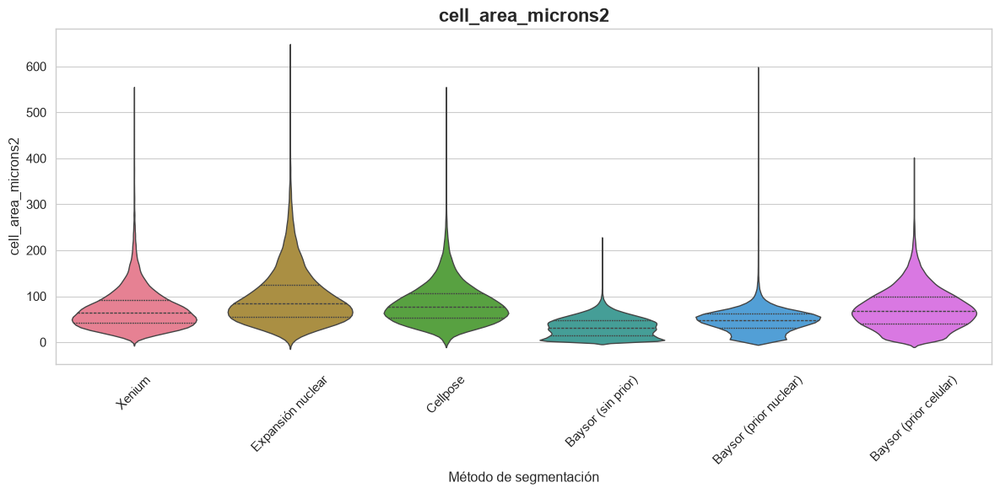

In [8]:
# Creamos la gráfica de violines correspondiente a las áreas celulares:
anndata_violin_plot(adata_dict, "cell_area_microns2", GRAPHS_PRE_DIR)

A simple vista se ve que en todos los casos el área de las células no sigue una distribución normal. Aun así, podemos confirmarlo usando un test de normalidad.

In [9]:
# Dado que vamos a repetir el test con cada parámetro a comparar, vamos a crear una función
# que realice el test sobre el diccionario y la columna indicada, para simplificar el código.

def anndata_normaltest(anndata_dict, column_to_test, output_folder):
    r"""
    Realiza un test de normalidad de D'Agostino-Pearson sobre los valores de una columna específica
    de la sección `.obs` de las tablas `AnnData` indicadas en el diccionario aportado. Genera una tabla
    con los resultados, la imprime y la guarda en un archivo .csv.

    Parameters
    ----------
    anndata_dict : dict con el formato `nombre : tabla_AnnData`
        El diccionario que contiene los nombres de los métodos a comparar y las tablas `AnnData` correspondientes.
    column_to_test : str
        Nombre de la columna del `AnnData` que contiene la información que queremos comparar.
    output_folder: str
        Ruta a la carpeta donde guardar la tabla resultante.
    
    Returns
    ----------
    df_normaltest : DataFrame
        El DataFrame que contiene los resultados del análisis.
    """
    
    # Usamos listas para guardar los distintos valores del test:
    methods_list = [] # Para almacenar los nombres de los métodos iterados en orden
    normaltest_statistics = [] # Para almacenar el valor del estadístico
    normaltest_pvalue = [] # Para almacenar el p-valor de cada test
    normaltest_is_normal = [] # Para indicar si el resultado sigue una distribución normal o no

    # Iteramos sobre cada tabla de segmentación:
    for name, table in anndata_dict.items():
        values = table.obs[column_to_test].dropna().values
        
        # Test de normalidad de D'Agostino-Pearson
        statistic, p_value = stats.normaltest(values)
        
        alpha = 0.05
        if p_value > alpha:
            is_normal = "SI"
        else:
            is_normal = "NO"

        methods_list.append(name)
        normaltest_statistics.append(statistic)
        normaltest_pvalue.append(p_value)
        normaltest_is_normal.append(is_normal)

    # Creamos un Data Frame para almacenar los resultados del test de normalidad:
    df_normaltest = pd.DataFrame({
        # Determinamos los nombres de cada columna y el contenido
        "Score del test": normaltest_statistics,
        "p-valor": normaltest_pvalue,
        "Sigue una distribución normal": normaltest_is_normal
    }, index=methods_list) # Usamos cada método de segmentación como índice:
    df_normaltest.index.name = "Método de segmentación"

    # Guardamos resultados como .csv e imprimimos la tabla:
    OUT_FOLDER = Path(output_folder)
    FILE_PATH = OUT_FOLDER / f"{column_to_test}_normaltest.csv"
    df_normaltest.to_csv(FILE_PATH)
    print(f'Resultados del test de normalidad para "{column_to_test}"')
    print(df_normaltest)
    print(f'Resultados guardados en "{FILE_PATH}"')
    # Devolvemos el Data Frame para guardarlo en una variable si se desea:
    return df_normaltest

In [10]:
# Creamos un diccionario para almacenar los resultados de los tests de normalidad
# de cada métrica, por si necesitamos acceder a ellos posteriormente:
normaltest_results_pre_dict = {}

# Realizamos el test de normalidad sobre el área de las células:
normaltest_results_pre_dict["cell_area_microns2"] = anndata_normaltest(adata_dict, "cell_area_microns2", TABLES_PRE_DIR)

Resultados del test de normalidad para "cell_area_microns2"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium                    13344.078225      0.0                            NO
Expansión nuclear         10002.747070      0.0                            NO
Cellpose                  10598.186523      0.0                            NO
Baysor (sin prior)         2675.412089      0.0                            NO
Baysor (prior nuclear)    21803.247183      0.0                            NO
Baysor (prior celular)     5281.930020      0.0                            NO
Resultados guardados en "results/statistics/prefilter/tables/cell_area_microns2_normaltest.csv"


Confirmado esto, procedemos a guardar los datos de la distribución de áreas (expresado como mediana [Q1, Q3]), y calcular si hay diferencias estadísticamente significativas entre las áreas celulares obtenidas con cada método de segmentación, en comparación con la segmentación aportada por Xenium, que utilizaremos a modo de control o *ground truth*. Para ello utilizaremos un test no paramétrico U de Mann-Whitney, seguido de un test de Bonferroni para ajustar el p-valor por las comparaciones múltiples. 

Adicionalmente, es interesante comprobar la magnitud del efecto, para hacernos una idea de cómo de grandes son las diferencias en las áreas calculadas por cada método de segmentación con respecto al método original de Xenium. Podemos hacernos una idea aproximada calculando la diferencia entre la mediana del control y los distintos métodos de segmentación, pero otro método más exacto consiste en calcular la Delta de Cliff ([Meissel y Yao, 2024](https://doi.org/10.7275/pare.1977)), una alternativa no paramétrica a la Delta de Cohen para medir el tamaño del efecto.

In [11]:
# Definimos una función para calcular mediana y cuartiles Q1 y Q3,
# que devuelva los resultados en un formato de texto adecuado para el Data Frame
# global que estamos realizando:

def anndata_median_results(anndata_dict, column_to_extract):
    r"""
    Calcula la mediana y los cuartiles Q1 y Q3 de los valores de una columna específica
    de la sección `.obs` de las tablas `AnnData` indicadas en el diccionario aportado. Genera una
    lista con los resultados para cada método de segmentación siguiendo el orden del diccionario,
    cada resultado indicado como una cadena de texto en formato `mediana [Q1, Q3]`.

    Parameters
    ----------
    anndata_dict : dict con el formato `nombre : tabla_AnnData`
        El diccionario que contiene los nombres de los métodos a comparar y las tablas `AnnData` correspondientes.
    column_to_extract : str
        Nombre de la columna del `AnnData` que contienen los valores sobre los que queremos calcular.
    
    Returns
    ----------
    results_list : list
        La lista con los resultados para cada método de segmentación siguiendo el orden del diccionario,
        cada resultado indicado como una cadena de texto en formato `mediana [Q1, Q3].
    """
    # Calculamos mediana y [Q1, Q3] y guardamos en nuestro Data Frame global:
    results_list = []

    for name, table in anndata_dict.items():
        
        values = table.obs[column_to_extract].dropna().values
        median = np.median(values)
        q1 = np.percentile(values, 25)
        q3 = np.percentile(values, 75)
        text_for_table = f"{median:.2f} [{q1:.2f} - {q3:.2f}]"
        results_list.append(text_for_table)

    return results_list


In [12]:
# Calculamos mediana y cuartiles de los datos del área celular.
area_results_pre = anndata_median_results(adata_dict, "cell_area_microns2")

# Añadimos los resultados al Data Frame global de métricas:
df_qc_metrics_prefilter["Área celular (µm²)"] = area_results_pre

# Comprobamos la tabla global:
print(df_qc_metrics_prefilter)


                        Nº total de células      Área celular (µm²)
Xenium                                34621   63.67 [41.68 - 91.35]
Expansión nuclear                     37065  83.90 [55.95 - 125.49]
Cellpose                              36352  76.54 [52.83 - 105.98]
Baysor (sin prior)                    77781   31.70 [15.08 - 47.97]
Baysor (prior nuclear)                57006   47.91 [30.63 - 62.24]
Baysor (prior celular)                39260   68.08 [41.36 - 98.36]


In [13]:
# Dado que el análisis estadístico también se va a repetir de manera constante accediendo a diversas columnas de
# los objetos AnnData, creamos una función para simplificar su uso.

# Primero definimos una función auxiliar para interpretar la Delta de Cliff (Meissel y Yao 2024, tabla 2):
def evaluate_dcliff(d):
    d_abs = abs(d)
    if d_abs < 0.15: return "Insignificante"
    elif d_abs < 0.33: return "Pequeño"
    elif d_abs < 0.47: return "Medio"
    else: return "Grande"

# Ahora definimos la función principal, para realizar un análisis
def anndata_statistics(anndata_dict, column_to_test, output_folder, control_key="Xenium"):
    r"""
    Realiza un análisis estadístico no paramétrico U de Mann-Whitney, seguido por un
    test de Bonferroni para ajustar el p-valor por las comparaciones múltiples. Posteriormente
    calcula la magnitud del efecto por diferencia de medianas y calculando la Delta de Cliff, 
    la interpreta, y genera una tabla con todos los resultados. Adicionalmente imprime la tabla con los
    resultados y la guarda en un archivo .csv.

    Parameters
    ----------
    anndata_dict : dict con el formato `nombre : tabla_AnnData`
        El diccionario que contiene los nombres de los métodos a comparar y las tablas `AnnData` correspondientes.
    column_to_test : str
        La columna del `AnnData` que contiene la información que queremos comparar.
    output_folder: str
        Ruta a la carpeta donde guardar la tabla resultante.
    control_key : str
        La clave del diccionario correspondiente al control que vamos a usar para comparar.
        Por defecto es "Xenium".
    
    Returns
    ----------
    df_statistics : DataFrame
        El DataFrame que contiene los resultados del análisis.
    """

    values_control = anndata_dict[control_key].obs[column_to_test].dropna().values
    median_control = np.median(values_control)
    n_control = len(values_control) # Necesario para la Delta de Cliff

    # Creamos listas para almacenar los resultados:
    methods = []
    pvalues_list = []
    median_diff_list = []
    dcliff_list = []
    dcliff_eval_list = []

    # Iteramos sobre los métodos:
    for name, table in anndata_dict.items():
        if name == control_key:
            continue # Saltamos el control para no compararlo consigo mismo.
            
        values_method = table.obs[column_to_test].dropna().values
        n_method = len(values_method)
        
        # Hacemos el test no paramétrico de Mann-Whitney U:
        stat, p_val = stats.mannwhitneyu(values_method, values_control, alternative='two-sided')
        
        # Tamaño del efecto 1: diferencia absoluta de medianas
        median_diff = np.median(values_method) - median_control
        
        # Tamaño del efecto 2: Delta de Cliff calculada a partir de U de Mann-Whitney,
        # ver como ejemplo este paquete de R https://rdrr.io/cran/rcompanion/man/cliffDelta.html
        cliff_d = 2 * ((stat / (n_method * n_control)) - 0.5)

        methods.append(name)
        pvalues_list.append(p_val)
        median_diff_list.append(median_diff)
        dcliff_list.append(cliff_d)
        dcliff_eval_list.append(evaluate_dcliff(cliff_d))

    # Realizamos la corrección por comparaciones múltiples (Holm-Bonferroni):
    reject, corrected_pvalue, _, _ = smm.multipletests(pvalues_list, alpha=0.05, method='holm')

    # Generamos la tabla resumen
    df_statistics = pd.DataFrame({
        'Método vs Xenium': methods,
        'P-valor corregido': corrected_pvalue,
        'Diferencias significativas': reject,
        f'Dif. medianas ({column_to_test})': median_diff_list,
        'Delta de Cliff': dcliff_list,
        'Magnitud del efecto': dcliff_eval_list
    })

    # Guardamos resultados como .csv:
    OUT_FOLDER = Path(output_folder)
    FILE_PATH = OUT_FOLDER / f"{column_to_test}_statistics.csv"
    df_statistics.to_csv(FILE_PATH, index=False)
    print(f'Análisis estadístico de "{column_to_test}"')
    print(df_statistics)
    print(f'Resultados guardados en "{FILE_PATH}"')
    return df_statistics

In [14]:
# Creamos un diccionario para almacenar los resultados de los análisis estadísticos
# de cada métrica de calidad:
statistics_results_pre_dict = {}

# Realizamos el análisis estadístico:
statistics_results_pre_dict["cell_area_microns2"] = anndata_statistics(adata_dict, "cell_area_microns2", TABLES_PRE_DIR)

Análisis estadístico de "cell_area_microns2"
         Método vs Xenium  P-valor corregido  Diferencias significativas  \
0       Expansión nuclear       0.000000e+00                        True   
1                Cellpose       0.000000e+00                        True   
2      Baysor (sin prior)       0.000000e+00                        True   
3  Baysor (prior nuclear)       0.000000e+00                        True   
4  Baysor (prior celular)       1.460706e-12                        True   

   Dif. medianas (cell_area_microns2)  Delta de Cliff Magnitud del efecto  
0                           20.230000        0.275890             Pequeño  
1                           12.869534        0.184694             Pequeño  
2                          -31.966337       -0.613270              Grande  
3                          -15.755921       -0.351928               Medio  
4                            4.409957        0.030131      Insignificante  
Resultados guardados en "results/statistic

## 7.3. Eficiencia de asignación global y porcentaje de transcritos asignados para cada gen
La eficiencia de asignación global de transcritos es el porcentaje de transcritos que han sido asignados a células respecto al total de transcritos que se han detectado en la región de tejido analizada. Por otra parte, también podemos calcular el porcentaje de transcritos de cada gen que han sido asignados a una célula, respecto al total de transcritos de ese gen que han sido detectados en la región analizada. Esta última métrica es útil para comprobar si alguno de los algoritmos de segmentación es peor asignando transcritos de ciertos genes, o para estimar si hay cambios generales según el método de segmentación. 

In [16]:
# Definimos el total de transcritos físicos absolutos en el tejido.
# Como cada fila en la tabla de transcripts_global es un transcrito individual leído por Xenium,
# el total es simplemente el número de filas de dicha tabla:
total_transcripts_raw = len(sdata_complete.points["transcripts_global"])

# Determinamos el total de transcritos asignados por el método de segmentación.
# Es la suma directa de todos los valores de la matriz .X (engloba todas las células y todos los genes).
# Iteramos sobre el diccionario para acceder al número de células detectadas en cada segmentación (n_obs):
efficiency_list_pre = []
for name, table in adata_dict.items():
    assigned_transcripts= table.X.sum()
    efficiency = f"{(float(assigned_transcripts) / total_transcripts_raw) * 100:.1f}"
    efficiency_list_pre.append(efficiency)

# Añadimos la fila al DataFrame global:
df_qc_metrics_prefilter["Eficiencia de asignación global (%)"] = efficiency_list_pre

# Comprobamos la tabla global que hemos creado:
print(df_qc_metrics_prefilter)

                        Nº total de células      Área celular (µm²)  \
Xenium                                34621   63.67 [41.68 - 91.35]   
Expansión nuclear                     37065  83.90 [55.95 - 125.49]   
Cellpose                              36352  76.54 [52.83 - 105.98]   
Baysor (sin prior)                    77781   31.70 [15.08 - 47.97]   
Baysor (prior nuclear)                57006   47.91 [30.63 - 62.24]   
Baysor (prior celular)                39260   68.08 [41.36 - 98.36]   

                       Eficiencia de asignación global (%)  
Xenium                                                78.3  
Expansión nuclear                                     97.6  
Cellpose                                              94.5  
Baysor (sin prior)                                    96.6  
Baysor (prior nuclear)                                97.5  
Baysor (prior celular)                                98.4  


Para calcular la proporción de transcritos asignados para cada gen, `Harpy` presenta una función específica, `analyse_genes_left_out`, que genera entre otras cosas una tabla indicando los 10 genes con la mayor cantidad de transcritos sin asignar a células, pudiendo así comparar posibles diferencias entre los distintos métodos de segmentación.

Esta función, no obstante, requiere que la máscara de segmentación empleada se encuentre en formato de etiquetas (labels), de manera que no podemos usarla con las máscaras de segmentación de `Baysor`, que fueron importadas como formas (shapes) vectoriales. En ese caso, podemos realizar el cálculo directamente accediendo a la matriz de conteos de cada segmentación realizada.

In [17]:
# Creamos un Data Frame vacío para almacenar en él todas las proporciones
# de transcritos de todos los métodos:
df_proportions_kept_pre = pd.DataFrame()

# Cargamos la lista de transcritos desde el formato Dask a un DataFrame:
df_points = sdata_complete.points["transcripts_global"].compute()

# Hacemos un recuento del número de veces que aparece el nombre de cada gen en toda la lista
# de transcritos detectados en la región de interés. Esto constituye las lecturas crudas (raw_counts):
raw_counts = df_points["gene"].value_counts().rename("raw_counts")

# Aquellos genes que presentan un número bajo de conteos en todo el tejido generan mucho ruido
# estadístico, ya que cualquier mínimo cambio en las asignaciones a células puede hacer variar
# mucho el valor de proportion_kept. Para evitar esto, filtramos aquellos genes con menos de 100
# copias totales en el tejido:
genes_before = len(raw_counts)
raw_counts = raw_counts[raw_counts > 100]
genes_after = len(raw_counts)
logger.info(f"Nº de genes descartados por tener un bajo conteo: {genes_before - genes_after}")

# Iteramos sobre adata_dict:
for name, table in adata_dict.items():
    # Aplastamos verticalmente la matriz de conteos, es decir, sumamos los transcritos detectados
    # de cada gen (columna) en todas las células (filas) mediante "axis = 0". El resultado se transforma
    # en un vector de valores únicos que tienen asociados los nombres de los genes correspondientes,
    # generando así una lista similar a la de las lecturas crudas, pero que contiene solo aquellos transcritos
    # que han sido asignados a alguna célula.
    assigned_counts = pd.Series(
        np.ravel(table.X.sum(axis=0)),
        index=table.var_names,
        name="assigned_counts"
    )
    # Creamos un DataFrame concatenando ambas listas de conteos (ordenados según el índice que es el nombre del gen
    # en ambos casos, y haciendo un inner join para que no aparezcan aquellos genes con bajos conteos que fueron
    # eliminados anteriormente). Para los genes donde la segmentación no ha asignado transcritos, el valor es "NA". Para
    # evitar problemas con los cálculos posteriores, cambiamos esos NA por ceros.
    df_proportions_method = pd.concat([raw_counts, assigned_counts], axis=1, join="inner").fillna(0)

    # Calculamos el porcentaje de transcritos que han sido asignados a células durante la segmentación:
    df_proportions_method["pct_proportion_kept"] = (df_proportions_method["assigned_counts"] / df_proportions_method["raw_counts"]) * 100

    # Extraemos los valores de pct_proportion_kept de todos los genes de cada método para hacer estadísticas:
    df_proportions_kept_pre[name] = df_proportions_method["pct_proportion_kept"]

    # Ordenamos descendentemente los genes por pct_proportion_kept, para ver aquellos que han sido peor asignados por
    # los distintos métodos de transcripción:
    df_proportions_method = df_proportions_method.sort_values("pct_proportion_kept")

    # Guardamos los resultados en un archivo .csv para cada segmentación, por si posteriormente queremos comprobar
    # la proporción de transcritos asignados para algún gen en concreto. 
    method_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "") # Adecuamos para nombrar archivos
    FILE_PATH = PROP_KEPT_PRE_DIR / f"{method_name}.csv"
    df_proportions_method.to_csv(FILE_PATH)

    # Imprimimos los 10 genes peor asignados para cada método
    print(f"Lista de los 10 genes con peor asignación de transcritos en {name}")
    print(df_proportions_method["pct_proportion_kept"].head(10))


2026-10-18 12:24:40.705 | INFO     | __main__:<module>:19 - Nº de genes descartados por tener un bajo conteo: 288


Lista de los 10 genes con peor asignación de transcritos en Xenium
MYH11     32.886138
SYNPO2    38.700696
VAMP5     39.703460
SYNM      43.148278
CD33      44.897959
NEXN      46.287520
DPT       46.924429
IGF2      47.297297
PRR14L    49.897049
ZAN       50.000000
Name: pct_proportion_kept, dtype: float64
Lista de los 10 genes con peor asignación de transcritos en Expansión nuclear
MYH11     66.758829
DPT       68.629174
SYNPO2    70.301624
IGF2      72.972973
SYNM      73.295854
PI16      73.991935
PLN       77.915020
CNN1      79.076420
MAOB      80.035336
MFAP5     80.562500
Name: pct_proportion_kept, dtype: float64
Lista de los 10 genes con peor asignación de transcritos en Cellpose
MYH11     57.729044
IGF2      58.108108
SYNPO2    60.696056
DPT       62.478032
PLN       63.438735
SYNM      65.003514
HOPX      67.665198
CNN1      69.077782
NEXN      69.352291
PALLD     70.133499
Name: pct_proportion_kept, dtype: float64
Lista de los 10 genes con peor asignación de transcritos en 

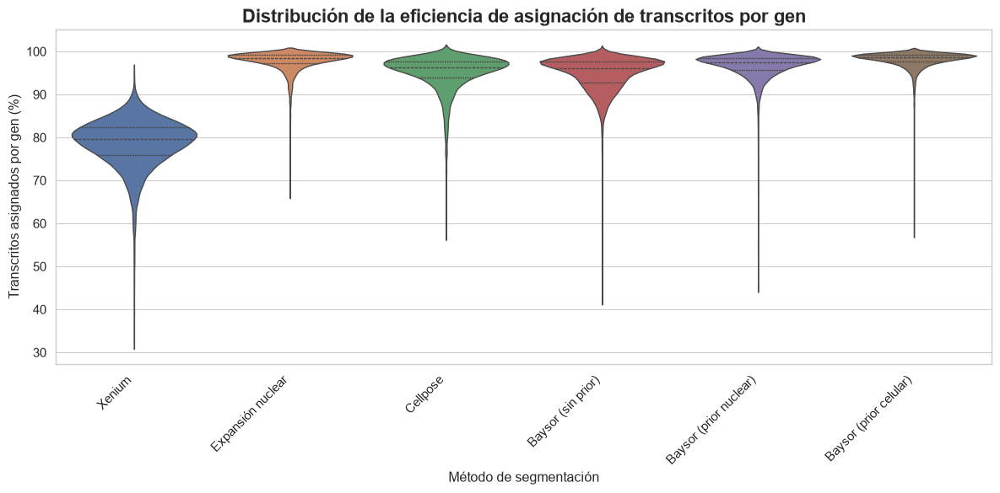

In [18]:
# Visualizamos los valores de proportions_kept_pre mediante un diagrama de violín
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_proportions_kept_pre, inner='quartile')
plt.title('Distribución de la eficiencia de asignación de transcritos por gen', weight="bold", fontsize=16)
plt.ylabel('Transcritos asignados por gen (%)')
plt.xlabel('Método de segmentación')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
TIFF_PATH = GRAPHS_PRE_DIR / "violin_proportion_kept.tiff"
plt.savefig(TIFF_PATH, dpi=300, bbox_inches="tight")
plt.show()

In [19]:
# Test de normalidad, sin usar la función porque tenemos los datos en un DataFrame:

methods_list = []
normaltest_statistics = [] # Para almacenar el valor del estadístico
normaltest_pvalue = [] # Para almacenar el p-valor de cada test
normaltest_is_normal = [] # Para indicar si el resultado sigue una distribución normal o no

# Iteramos sobre la tabla df_proportions_kept_pre:
for colname, values in df_proportions_kept_pre.items():
       
    # Test de normalidad de D'Agostino-Pearson.
    statistic, p_value = stats.normaltest(values)
    
    alpha = 0.05
    if p_value > alpha:
        is_normal = "SI"
    else:
        is_normal = "NO"
    methods_list.append(colname)
    normaltest_statistics.append(statistic)
    normaltest_pvalue.append(p_value)
    normaltest_is_normal.append(is_normal)

# Creamos un Data Frame para almacenar los resultados del test de normalidad:
df_normaltest = pd.DataFrame({
    # Determinamos los nombres de cada columna y el contenido
    "Score del test": normaltest_statistics,
    "p-valor": normaltest_pvalue,
    "Sigue una distribución normal": normaltest_is_normal
}, index=methods_list) # Usamos cada método de segmentación como índice:
df_normaltest.index.name = "Método de segmentación"

# Guardamos el resultado del test en el diccionario de tests creado anteriormente:
normaltest_results_pre_dict["pct_proportion_kept"] = df_normaltest

# Guardamos resultados como .csv e imprimimos la tabla:
FILE_PATH = TABLES_PRE_DIR / "pct_proportion_kept_normaltest.csv"
df_normaltest.to_csv(FILE_PATH)
print('Resultados del test de normalidad para "pct_proportion_kept"')
print(df_normaltest)
print(f'Resultados guardados en "{FILE_PATH}"')

Resultados del test de normalidad para "pct_proportion_kept"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium                     1433.928126      0.0                            NO
Expansión nuclear          3983.276895      0.0                            NO
Cellpose                   2725.909592      0.0                            NO
Baysor (sin prior)         3112.359709      0.0                            NO
Baysor (prior nuclear)     4936.016647      0.0                            NO
Baysor (prior celular)     5985.041424      0.0                            NO
Resultados guardados en "results/statistics/prefilter/tables/pct_proportion_kept_normaltest.csv"


Como la proporción de transcritos asignados por gen no sigue una distribución normal, la expresamos también como mediana [Q1, Q3], y la añadimos al Data Frame de resultados global:

In [20]:
# Calculamos mediana y [Q1, Q3] y guardamos en nuestro Data Frame global:
prop_kept_list_pre = []

for colname, values in df_proportions_kept_pre.items():
       
    median = np.median(values)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)
    text_for_table = f"{median:.2f} [{q1:.2f} - {q3:.2f}]"
    prop_kept_list_pre.append(text_for_table)

# Añadimos los resultados al Data Frame global de métricas:
df_qc_metrics_prefilter["Transcritos asignados por gen (%)"] = prop_kept_list_pre

# Comprobamos la tabla global:
print(df_qc_metrics_prefilter)


                        Nº total de células      Área celular (µm²)  \
Xenium                                34621   63.67 [41.68 - 91.35]   
Expansión nuclear                     37065  83.90 [55.95 - 125.49]   
Cellpose                              36352  76.54 [52.83 - 105.98]   
Baysor (sin prior)                    77781   31.70 [15.08 - 47.97]   
Baysor (prior nuclear)                57006   47.91 [30.63 - 62.24]   
Baysor (prior celular)                39260   68.08 [41.36 - 98.36]   

                       Eficiencia de asignación global (%)  \
Xenium                                                78.3   
Expansión nuclear                                     97.6   
Cellpose                                              94.5   
Baysor (sin prior)                                    96.6   
Baysor (prior nuclear)                                97.5   
Baysor (prior celular)                                98.4   

                       Transcritos asignados por gen (%)  
Xenium  

In [21]:
# Procedemos con el análisis estadístico.

# Extraemos los valores de proportion_kept del control:
control_key = "Xenium" 
prop_kept_xenium = df_proportions_kept_pre["Xenium"]
median_xenium = np.median(prop_kept_xenium)
n_xenium = len(prop_kept_xenium) # Necesario para la Delta de Cliff

# Reiniciamos listas para almacenar los resultados:
methods = []
pvalues_list = []
median_diff_list = []
dcliff_list = []
dcliff_eval_list = []

# Iteramos sobre los métodos:
for colname, values in df_proportions_kept_pre.items():
    if colname == control_key:
        continue # Saltamos el control para no compararlo consigo mismo.
        
    method_prop_kept = values
    n_method = len(method_prop_kept)
    
    # Hacemos el test no paramétrico de Mann-Whitney U:
    stat, p_val = stats.mannwhitneyu(method_prop_kept, prop_kept_xenium, alternative='two-sided')
    
    # Tamaño del efecto 1: diferencia absoluta de medianas
    median_diff = np.median(method_prop_kept) - median_xenium
    
    # Tamaño del efecto 2: Delta de Cliff calculada a partir de U de Mann-Whitney,
    # ver como ejemplo este paquete de R https://rdrr.io/cran/rcompanion/man/cliffDelta.html
    cliff_d = 2 * ((stat / (n_method * n_xenium)) - 0.5)

    methods.append(colname)
    pvalues_list.append(p_val)
    median_diff_list.append(median_diff)
    dcliff_list.append(cliff_d)
    dcliff_eval_list.append(evaluate_dcliff(cliff_d))

# Realizamos la corrección por comparaciones múltiples (Holm-Bonferroni):
reject, corrected_pvalue, _, _ = smm.multipletests(pvalues_list, alpha=0.05, method='holm')

# Generamos la tabla resumen
df_statistics = pd.DataFrame({
    'Método vs Xenium': methods,
    'P-valor corregido': corrected_pvalue,
    'Diferencias significativas': reject,
    'Dif. medianas (% transcritos asignados)': median_diff_list,
    'Delta de Cliff': dcliff_list,
    'Magnitud del efecto': dcliff_eval_list
})

# Añadimos los resultados al diccionario de tests estadísticos:
statistics_results_pre_dict["pct_prop_kept"] = df_statistics

# Guardamos resultados como .csv y comprobamos la tabla:
FILE_PATH = TABLES_PRE_DIR / "pct_prop_kept_statistics.csv"
df_statistics.to_csv(FILE_PATH, index=False)
df_statistics

,Método vs Xenium,P-valor corregido,Diferencias significativas,Dif. medianas (% transcritos asignados),Delta de Cliff,Magnitud del efecto
0,Expansión nuclear,0.0,True,18.872983,0.995643,Grande
1,Cellpose,0.0,True,16.631516,0.963441,Grande
2,Baysor (sin prior),0.0,True,16.420637,0.981987,Grande
3,Baysor (prior nuclear),0.0,True,17.859043,0.991701,Grande
4,Baysor (prior celular),0.0,True,18.997974,0.996112,Grande


### 7.3.1. Análisis de los genes peor conservados
Si comprobamos las listas de transcritos peor asignados creadas en el paso anterior, podemos comprobar como independientemente del método de segmentación, el gen con peor eficiencia de asignación de transcritos es MYH11. Este gen codifica para la cadena pesada de la miosina 11, y es un marcador de células de músculo liso. Estas células presentan una morfología fusiforme muy alargada, con citoplasmas muy amplios en comparación con el núcleo, con lo que es de esperar que la segmentación sea poco eficiente en estos casos. Podemos visualizar una región de tejido de músculo liso para comprobar cómo de bien lo ha hecho cada método con este tipo de células.

In [22]:
# Filtramos los transcritos para mostrar solo aquellos que corresponden a MYH11:
transcripts = sdata_complete.points['transcripts_global']
transcripts_myh11 = transcripts[transcripts['gene'] == 'MYH11']

# 3. Guardar los puntos filtrados como una nueva capa en el objeto
sdata_complete.points['transcripts_MYH11'] = transcripts_myh11

In [23]:
# Definimos las coordenadas de la ROI de músculo liso tras definirlas con Napari:
x_min, x_max = 14800, 15800
y_min, y_max = 24500, 25500

# Cargamos las máscaras y recortamos con bounding_box a las coordenadas de la ROI:
sdata_roi = sdata_complete.query.bounding_box(
    axes=["x", "y"], min_coordinate=[x_min, y_min], max_coordinate=[x_max, y_max], target_coordinate_system="global", filter_table=False
)

# Generamos la imagen correspondiente a la segmentación de Xenium por separado (usa labels):
fig, ax = plt.subplots(figsize=(10, 10))
(
    sdata_roi.pl.render_images(
        "morphology_focus_global",
        channel=['DAPI', 'ATP1A1_CD45_E-Cadherin', 'AlphaSMA_Vimentin'],
        palette=["blue", "green", "red"],
        alpha=1.0,
        norm=PercentileNormalize(1, 99)
    )
    .pl.render_labels(
        "cell_labels_global",
        fill_alpha=0.0,
        outline=True,
        outline_alpha=1.0,
        outline_color="cyan"
    )
    .pl.render_points(
        'transcripts_MYH11',
        color='yellow',
        size=3
    )
    .pl.show(ax=ax, coordinate_systems="global")
)
plot_conf_and_save(ax, fig, "muscle_xenium_default.tiff") # Función creada en la sección 5.

# Creamos un bucle para guardar las demás máscaras:
masks_shapes = {
    "cellpose_segmentation_mask_boundaries": "muscle_cellpose.tiff",
    "baysor_no_prior_segmentation_boundaries": "muscle_baysor_noprior.tiff",
    "baysor_nuclear_mask_prior_segmentation_boundaries": "muscle_baysor_nuclear_prior.tiff",
    "baysor_cellpose_cito_prior_segmentation_boundaries": "muscle_baysor_cyto_prior.tiff",
    "nucleus_segmentation_mask_expanded_boundaries": "muscle_nucleus_expanded.tiff"
}

for name, output_file in masks_shapes.items():
    fig, ax = plt.subplots(figsize=(10, 10))
    (
        sdata_roi.pl.render_images(
            "morphology_focus_global",
            channel=['DAPI', 'ATP1A1_CD45_E-Cadherin', 'AlphaSMA_Vimentin'],
            palette=["blue", "green", "red"],
            alpha=1.0,
            norm=PercentileNormalize(1, 99)
        )
        .pl.render_shapes(
            name,
            fill_alpha=0.0,           
            outline_color="cyan",     
            outline_width=1.0         
        )
        .pl.render_points(
        'transcripts_MYH11',
        color='yellow',
        size=3
        )
        .pl.show(ax=ax, coordinate_systems="global")
    )
    plot_conf_and_save(ax, fig, output_file)

Imagen guardada en results/images/muscle_xenium_default.tiff
Imagen guardada en results/images/muscle_cellpose.tiff
Imagen guardada en results/images/muscle_baysor_noprior.tiff
Imagen guardada en results/images/muscle_baysor_nuclear_prior.tiff
Imagen guardada en results/images/muscle_baysor_cyto_prior.tiff
Imagen guardada en results/images/muscle_nucleus_expanded.tiff


## 7.4. Métricas de calidad generadas mediante Scanpy


`Harpy` aporta la función `hp.tb.preprocess_transcriptomics()` para calcular todas las métricas de preprocesado y realizar la normalización necesaria para análisis posteriores. Sin embargo, al igual que con otras funciones, requiere del uso de máscaras de segmentación en formato `Labels` y no podemos usarla con las segmentaciones de Baysor. Por lo tanto, debemos desarrollar el mismo proceso usando únicamente `Scanpy`.

En primer lugar, podemos calcular las métricas de calidad básicas de `Scanpy` sobre los datos de segmentación crudos. Estas métricas se basan en las del paquete de R `scater` ([McCarthy et al. 2017](https://doi.org/10.1093/bioinformatics/btw777)). Entre estas métricas encontramos las siguientes a nivel de células (que se almacenan en `.obs`):
- `total_counts`. Indica el número total de transcritos que se ha detectado en la célula (sumando los de todos los genes detectados en esa célula).
- `n_genes_by_counts`. El número de genes únicos que se están expresando en esa célula, es decir, la complejidad transcriptómica.
- `pct_counts_in_top_2_genes` / `pct_counts_in_top_5_genes`. Indican el porcentaje de transcritos que corresponden a los dos o cinco primeros genes más expresados en cada célula. Valores elevados son indicativos de que la célula está muerta o es un artefacto.
- Transformaciones logarítmicas de las dos métricas anteriores, para facilitar su representación en histogramas.

También encontramos métricas acerca de los genes detectados (`.var`):
- `total_counts`. Indica el número total de veces que se ha detectado el gen en todo el tejido (sumando todas las células).
- `n_cells_by_counts`. Indica el número de células distintas en las que se ha detectado el gen.
- `mean_counts`. La expresión media del gen por célula, calculado como `total_counts` partido por el número total de células detectadas.
- `pct_dropout_by_counts`. Indica el porcentaje de células en las que este gen no se ha detectado.
- Transformaciones logarítmicas de `total_counts` y `mean_counts`.

De todas estas métricas, sería útil comparar:
- Total de transcritos detectados por célula (`total_counts` en `.obs`).
- Total de genes únicos por célula (`n_genes_by_counts`).
- `pct_counts_in_top_2_genes` y `pct_counts_in_top_5_genes`.

Adicionalmente, calcularemos la densidad transcriptómica, dividiendo el número de transcritos de cada célula (`total_counts` partido por su área celular (`cell_area_microns2`).


In [24]:
# Creamos un bucle para iterar por cada tabla:
tables = list(sdata_complete.tables.keys())

for item in tables:
    adata = sdata_complete.tables[item]
    # Calculamos las métricas de calidad con scanpy.pp.calculate_qc_metrics:
    sc.pp.calculate_qc_metrics(adata, percent_top=(2, 5), inplace=True)

In [25]:
# Calculamos la densidad transcriptómica y la añadimos a las correspondientes tablas:
tables = list(sdata_complete.tables.keys())

for item in tables:
    adata = sdata_complete.tables[item]
    adata.obs["transcripts_density"] = adata.obs["total_counts"] / adata.obs["cell_area_microns2"] 

In [26]:
# Creamos una lista con las métricas de calidad que queremos analizar:
qc_metrics_list = [
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_in_top_2_genes",
    "pct_counts_in_top_5_genes",
    "transcripts_density"
]

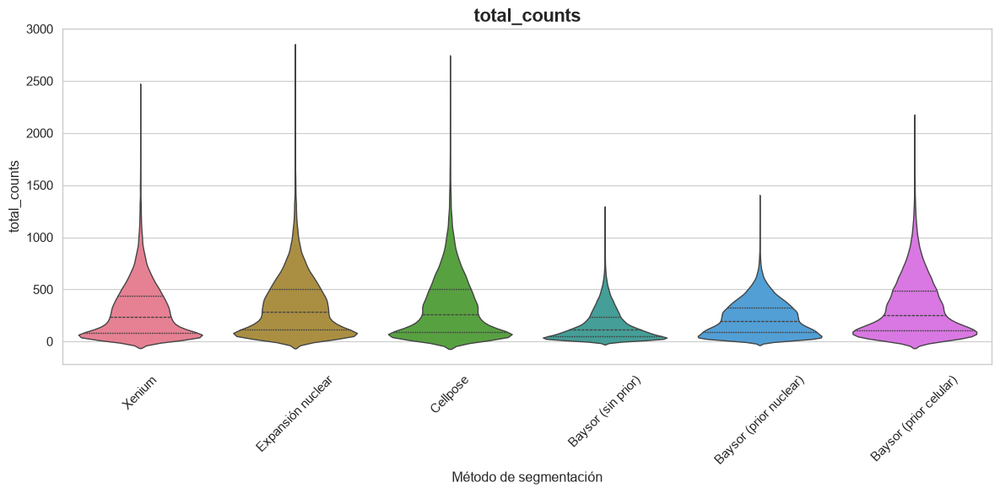

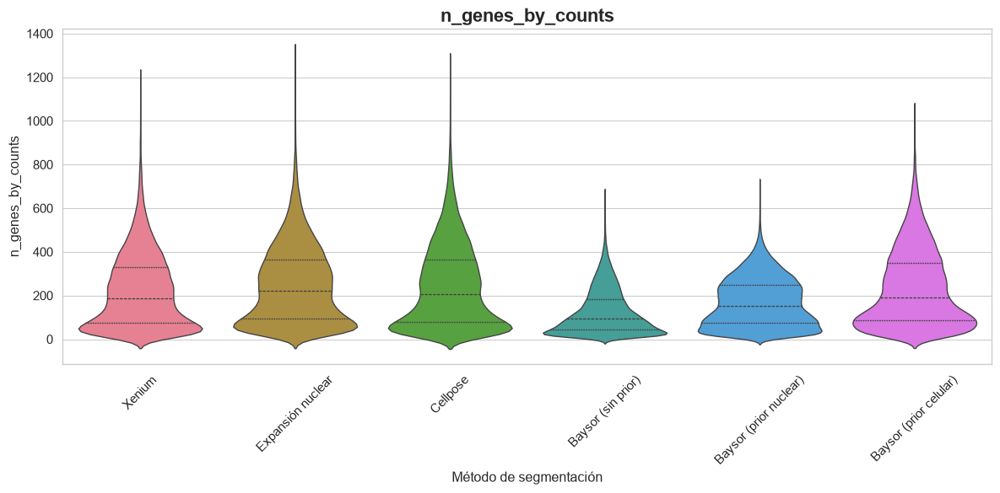

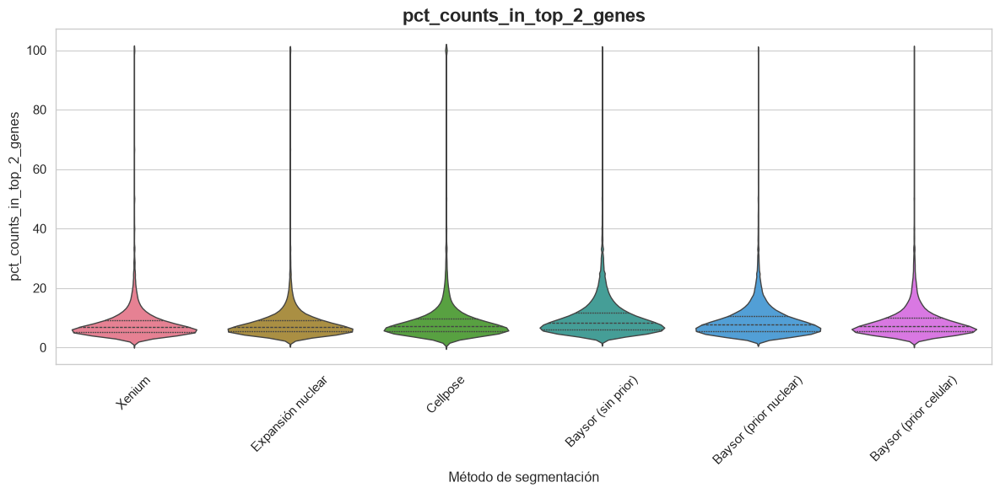

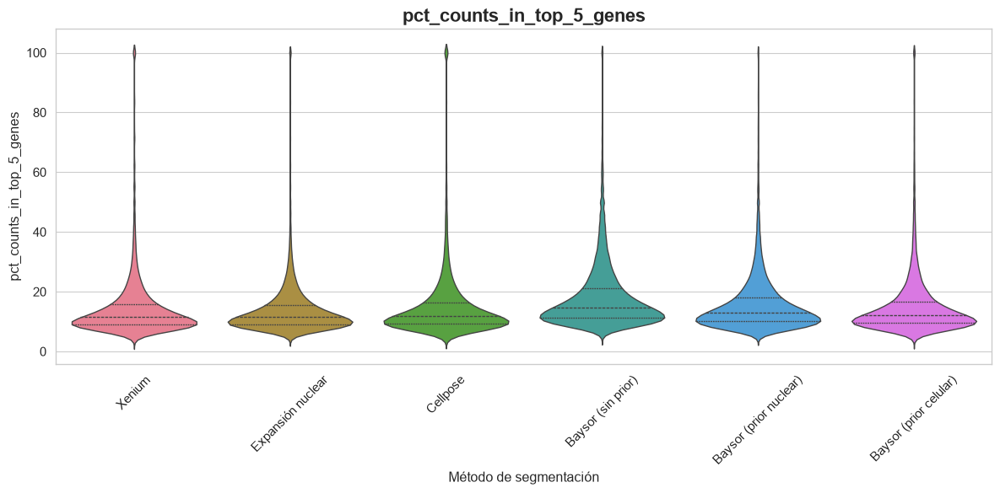

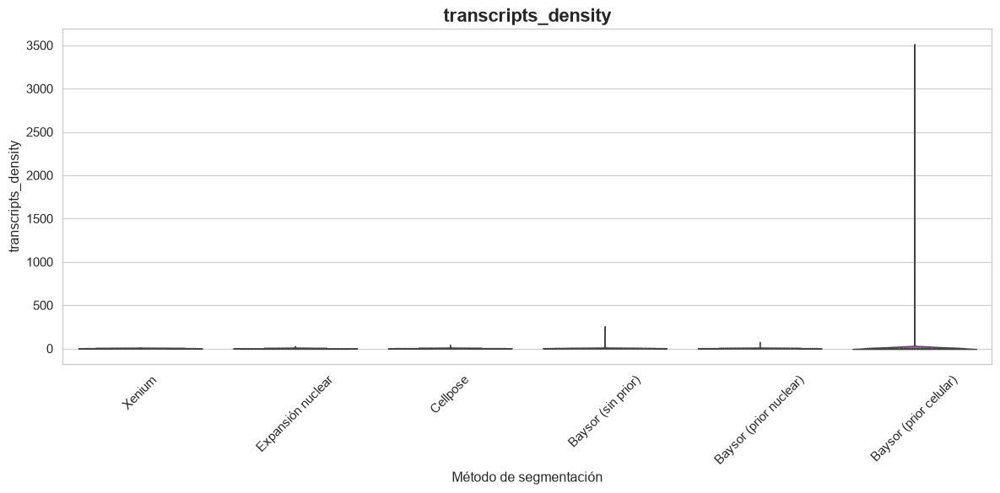

In [27]:
# Diagrama de violín para cada una de las métricas a analizar:
for item in qc_metrics_list:
    anndata_violin_plot(adata_dict, item, GRAPHS_PRE_DIR)

In [28]:
# Test de normalidad para cada métrica:

for item in qc_metrics_list:
   normaltest_results_pre_dict[item] = anndata_normaltest(adata_dict, item, TABLES_PRE_DIR)

Resultados del test de normalidad para "total_counts"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium                     8654.794922      0.0                            NO
Expansión nuclear          7985.410156      0.0                            NO
Cellpose                   8055.446777      0.0                            NO
Baysor (sin prior)        17883.710938      0.0                            NO
Baysor (prior nuclear)     5821.608398      0.0                            NO
Baysor (prior celular)     7450.031250      0.0                            NO
Resultados guardados en "results/statistics/prefilter/tables/total_counts_normaltest.csv"
Resultados del test de normalidad para "n_genes_by_counts"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium           

In [29]:
# Calculamos medianas y [Q1, Q3] de cada métrica y guardamos en nuestro Data Frame global.

# Primero creamos un diccionario de mapeo donde asignamos el texto descriptivo de cada resultado
# a su métrica correspondiente de la lista qc_metrics_list:
qc_metrics_descriptions = {
    "total_counts": "Número total de transcritos por célula",
    "n_genes_by_counts": "Número de genes únicos por célula",
    "pct_counts_in_top_2_genes": "Transcritos de los dos genes más expresados (%)",
    "pct_counts_in_top_5_genes": "Transcritos de los cinco genes más expresados (%)",
    "transcripts_density": "Densidad transcriptómica (transcritos/µm²)"
}

# Iteramos sobre la lista de métricas:
for item in qc_metrics_list:
    # Calculamos medianas y [Q1, Q3]:
    results = anndata_median_results(adata_dict, item)

    # Buscamos en el diccionario de mapeo la descripción correspondiente:
    text = qc_metrics_descriptions.get(item)

    # Añadimos la fila con el texto correspondiente al Data Frame global:
    df_qc_metrics_prefilter[text] = results

# Comprobamos:
df_qc_metrics_prefilter





,Nº total de células,Área celular (µm²),Eficiencia de asignación global (%),Transcritos asignados por gen (%),Número total de transcritos por célula,Número de genes únicos por célula,Transcritos de los dos genes más expresados (%),Transcritos de los cinco genes más expresados (%),Densidad transcriptómica (transcritos/µm²)
Xenium,34621,63.67 [41.68 - 91.35],78.3,79.59 [75.98 - 82.36],234.00 [86.00 - 437.00],189.00 [75.00 - 329.00],6.77 [5.18 - 9.26],11.45 [9.02 - 15.79],3.62 [1.71 - 5.87]
Expansión nuclear,37065,83.90 [55.95 - 125.49],97.6,98.46 [97.28 - 99.18],287.00 [113.00 - 502.00],221.00 [95.00 - 363.00],6.94 [5.34 - 9.31],11.54 [9.17 - 15.44],3.61 [1.27 - 6.45]
Cellpose,36352,76.54 [52.83 - 105.98],94.5,96.22 [93.92 - 97.69],264.00 [94.00 - 507.00],205.00 [80.00 - 366.00],7.11 [5.40 - 9.69],11.76 [9.23 - 16.36],3.53 [1.36 - 6.53]
Baysor (sin prior),77781,31.70 [15.08 - 47.97],96.6,96.01 [92.86 - 97.62],113.00 [51.00 - 236.00],95.00 [45.00 - 184.00],8.33 [6.15 - 11.76],14.77 [11.32 - 21.21],4.57 [3.03 - 6.43]
Baysor (prior nuclear),57006,47.91 [30.63 - 62.24],97.5,97.45 [95.68 - 98.46],193.00 [89.00 - 328.00],154.00 [74.00 - 250.00],7.61 [5.54 - 10.57],13.04 [10.04 - 18.18],4.43 [2.75 - 6.41]
Baysor (prior celular),39260,68.08 [41.36 - 98.36],98.4,98.59 [97.58 - 99.18],250.00 [106.00 - 488.00],192.00 [88.00 - 351.00],7.25 [5.48 - 10.00],12.11 [9.49 - 16.78],3.86 [2.24 - 6.42]


In [30]:
# Análisis estadístico:
for item in qc_metrics_list:
    statistics_results_pre_dict[item] = anndata_statistics(adata_dict, item, TABLES_PRE_DIR)

Análisis estadístico de "total_counts"
         Método vs Xenium  P-valor corregido  Diferencias significativas  \
0       Expansión nuclear                0.0                        True   
1                Cellpose                0.0                        True   
2      Baysor (sin prior)                0.0                        True   
3  Baysor (prior nuclear)                0.0                        True   
4  Baysor (prior celular)                0.0                        True   

   Dif. medianas (total_counts)  Delta de Cliff Magnitud del efecto  
0                          53.0        0.109468      Insignificante  
1                          30.0        0.070117      Insignificante  
2                        -121.0       -0.317225             Pequeño  
3                         -41.0       -0.117935      Insignificante  
4                          16.0        0.066294      Insignificante  
Resultados guardados en "results/statistics/prefilter/tables/total_counts_statistics

/tmp/ipykernel_7065/3536757553.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(method_order, rotation=30, ha="right", fontsize=10.5)
/tmp/ipykernel_7065/3536757553.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(method_order, rotation=30, ha="right", fontsize=10.5)
/tmp/ipykernel_7065/3536757553.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(method_order, rotation=30, ha="right", fontsize=10.5)


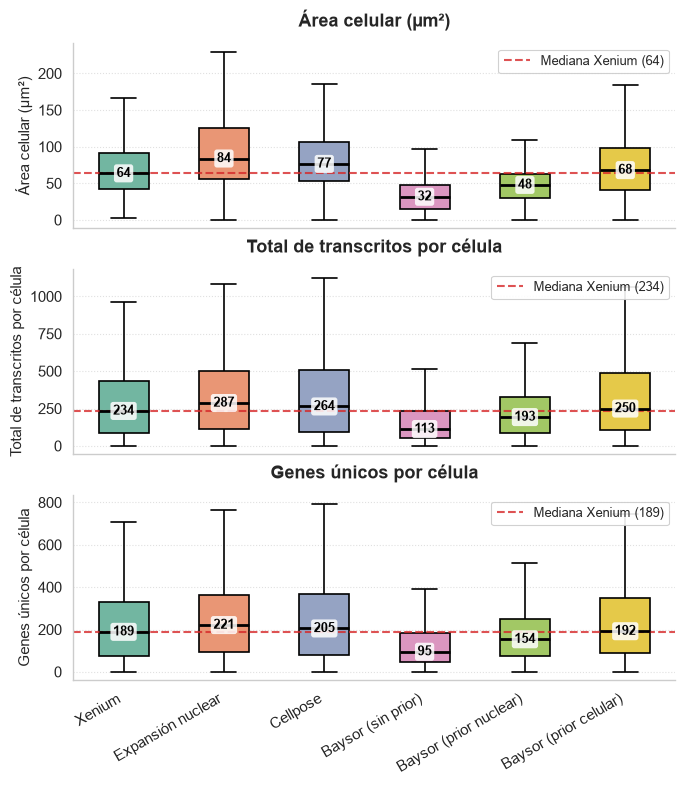

In [39]:
# Vamos a generar una figura que contenga 3 gráficas de boxplots mostrando los cambios en la distribución de 3 de los valores más importantes que demuestran
# la variablidad de las células generadas: área celular, número total de transcritos por célula, y número de genes únicos por célula.

# Creamos un diccionario que asigne las columnas correspondientes de adata.obs
# a un nombre más legible para las gráficas:
metrics_config = {
    "cell_area_microns2": "Área celular (µm²)",
    "total_counts": "Total de transcritos por célula",
    "n_genes_by_counts": "Genes únicos por célula"
}

# Definimos una lista con los nombres de las columnas:
cols_to_extract = list(metrics_config.keys()) # ["area", "total_counts", "n_genes_by_counts"]
# Creamos una lista donde guardaremos las columnas con los valores:
dfs_list = []

# Iteramos sobre el diccionario de las tablas:
for method_name, adata in adata_dict.items():
    # Extraemos las columnas correspondientes del objeto:
    sub_obs = adata.obs[cols_to_extract].copy()
    # Marcamos los valores con una columna que indique el método:
    sub_obs["Método"] = method_name
    # Lo añadimos a la lista:
    dfs_list.append(sub_obs)

# Pasamos las 3 columnas de cada método a un único DataFrame largo,
# que contiene todos los valores de todos los métodos para las 3 métricas
# en 3 columnas distintas. Las etiquetas que indican a qué metodo pertenece
# cada valor aparecen en una cuarta columna, "Método".
df_all_cells = pd.concat(dfs_list, ignore_index=True)

# Mantenemos el orden exacto de los métodos y definimos la paleta:
method_order = list(adata_dict.keys())
method_palette = sns.color_palette("Set2", len(method_order))

# 3. Generamos una figura de 3 paneles (3 filas x 1 columna)
fig, axes = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

# Iteramos sobre el diccionario de métricas para generar los 3 paneles:
for idx, (col, label) in enumerate(metrics_config.items()):
        
    ax = axes[idx]
    
    # Dibujamos el Boxplot. Por defecto, en seaborn los límites de la caja muestran el rango de 
    # valores que van de Q1 a Q3, la línea central indica la mediana, y los bigotes se extienden
    # desde los límites de la caja hasta 1,5 veces el rango intercuartílico.
    sns.boxplot(
        data=df_all_cells, # El DataFrame largo
        x="Método", # La columna que contiene la etiqueta para separar los valores por método
        y=col, # La columna que contiene los valores para la gráfica correspondiente
        order=method_order, # El orden en el que deben aparecer los métodos
        palette=method_palette, # La paleta de colores a usar
        showfliers=False, # Ocultamos los outliers para que la escala no se aplaste
        # Otras propiedades estéticas del boxplot:
        width=0.5,
        ax=ax,
        boxprops=dict(edgecolor="black", linewidth=1.2),
        medianprops=dict(color="black", linewidth=2.0),
        whiskerprops=dict(color="black", linewidth=1.2),
        capprops=dict(color="black", linewidth=1.2)
    )
    
    # Creamos una línea horizontal roja marcando la mediana del control (Xenium)
    # Calculamos el valor de la mediana de Xenium:
    xenium_median = df_all_cells.loc[df_all_cells["Método"] == "Xenium", col].median()
    # Dibujamos la línea:
    ax.axhline(
        xenium_median, color="#d62728", linestyle="--", linewidth=1.5, alpha=0.8, 
        label=f"Mediana Xenium ({xenium_median:.0f})"
    )

    # Vamos a añadir también el valor exacto de cada mediana para facilitar la comprensión de
    # los resultados. Primero calculamos la mediana de cada método en el orden del gráfico:
    medians = []
    for m in method_order:
        med = df_all_cells.loc[df_all_cells["Método"] == m, col].median()
        medians.append(med)
        
    # Escribimos el valor exacto sobre la línea de la mediana de cada caja:
    for i, med in enumerate(medians):
        # Dibujamos el texto:    
        ax.text(
            i, 
            med, # Coordenada Y exacta de la mediana
            f"{med:.0f}", # El valor a escribir, redondeado a enteros
            ha="center", 
            va="center", # Centrado verticalmente sobre la línea
            fontsize=9.5, 
            weight="bold", 
            color="black",
            # Añadimos un pequeño fondo blanco con bordes redondeados para que se lea bien:
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.85)
        )
    
    ax.set_title(label, fontsize=13, weight="bold", pad=12) # Añadimos como título la etiqueta de la métrica
    ax.set_ylabel(label, fontsize=11) # Añadimos también dicha etiqueta al nombre del eje Y
    ax.set_xlabel("")
    ax.set_xticklabels(method_order, rotation=30, ha="right", fontsize=10.5)
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9, fontsize=9.5)

plt.tight_layout()
plt.subplots_adjust(hspace=0.22)

# Guardamos los resultados en un archivo .tiff:
plt.savefig(GRAPHS_PRE_DIR / "comparativa_boxplots_metricas_principales.tiff", dpi=300, bbox_inches="tight")
plt.show()
plt.close("all")

## 7.5. Detección de dobletes con Scrublet
`Scanpy` puede detectar dobletes de células usando `Scrublet` ([Wolock et al 2019](https://doi.org/10.1016/j.cels.2018.11.005)). Aunque este método se usa principalmente para buscar dobletes de células en experimentos de *single-cell RNA-seq*, se puede usar también en experimentos de transcriptómica espacial, ya que se basa en el análisis de los transcriptomas detectados para cada célula, simplemente aportando la tabla de conteos en formato `AnnData`. Por ejemplo, en [Kanemaru et al. (2023)](https://doi.org/10.1038/s41586-023-06311-1) lo usan tanto en experimentos de sc/snRNA-seq como en los datos de transcriptómica espacial, determinando como dobletes celulares todas aquellas células con un *doublet score* superior a 0.3.

En [Sarwar y Gillis (2026)](https://doi.org/10.64898/2026.09.15.751798) comparan varios métodos de detección de dobletes en datos de transcriptómica espacial, entre ellos Scrublet, y determinan que las células que suelen presentar un *doublet score* alto suelen corresponder a zonas de alta densidad de transcritos (como los núcleos tumorales del tejido de ovario que estamos analizando). También indican que estos métodos suelen estar diseñados para detectar células que duplican su transcriptoma, mientras que en transcriptómica espacial lo que suele ocurrir es una mezcla parcial (con ganancias o pérdidas) de los transcriptomas de las células; y que en los experimentos de transcriptómica espacial, el panel de genes detectado suele ser de miles de genes, a diferencia del análisis transcriptómico completo que se da en experimentos de sc-RNAseq, por lo que hay menos información disponible para detectar diferencias. En consecuencia, hay que ajustar varios parámetros de `Scrublet` para mejorar la detección de dobletes:

- `expected_doublet_rate`. Indica la tasa de dobletes experados en la muestra, por defecto es `0.05`, pero dado que en la región del tejido que estamos analizando una gran parte está ocupada por tejido tumoral, donde las células aparecen muy compactas, y por lo tanto es más común que se produzcan dobletes, aumentaremos esta tasa a `0.10`.
- `threshold`. El umbral que separa los transcriptomas normales de los de dobletes. Suele situarse en el valle entre las dos modas que aparecen en los histogramas de distribución. Dado que en los datos de transcriptómica espacial no se observa tan claramente la distribución bimodal, este valor se ha ajustado manualmente tras varias pruebas a `0.35`.
- `n_prin_comps`. `Scrublet` genera un análisis de componentes principales para reducir dimensionalidad y detectar mejor diferencias en los transcriptomas de las células. Por defecto es `30`, pero como el panel de genes empleado tiene una dimensionalidad menor que un transcriptoma completo y es dirigido para tejido de cáncer, bajaremos este valor a `15` para evitar la introducción de ruido de genes poco informativos.

/tmp/ipykernel_9388/2582174727.py:6: UserWarning: Some cells have zero counts
  sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)


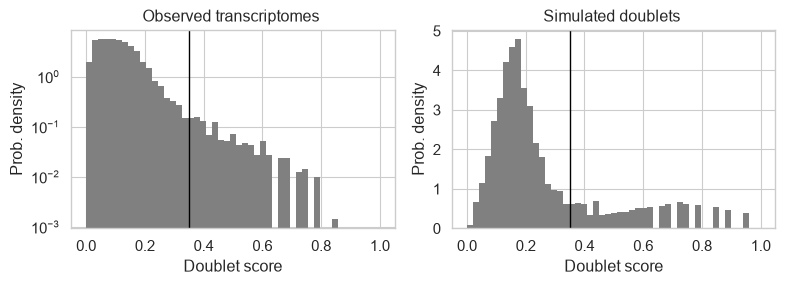

/tmp/ipykernel_9388/2582174727.py:6: UserWarning: Some cells have zero counts
  sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)


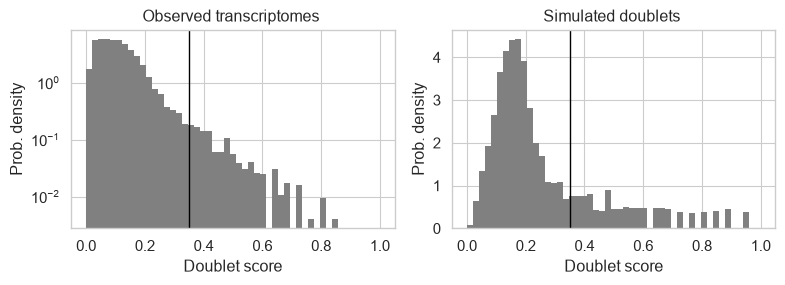

/tmp/ipykernel_9388/2582174727.py:6: UserWarning: Some cells have zero counts
  sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)


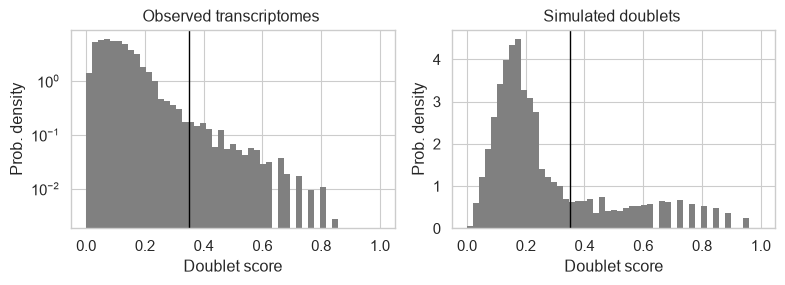

/tmp/ipykernel_9388/2582174727.py:6: UserWarning: Some cells have zero counts
  sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)


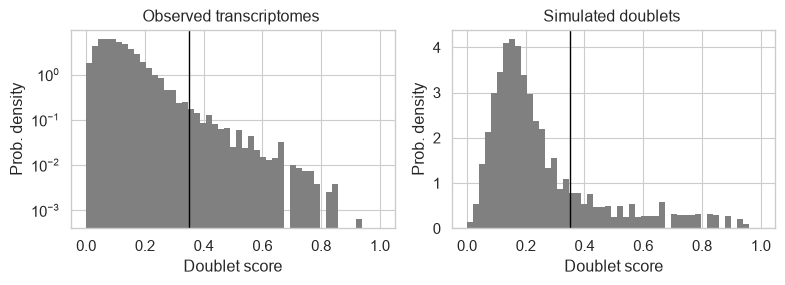

/tmp/ipykernel_9388/2582174727.py:6: UserWarning: Some cells have zero counts
  sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)


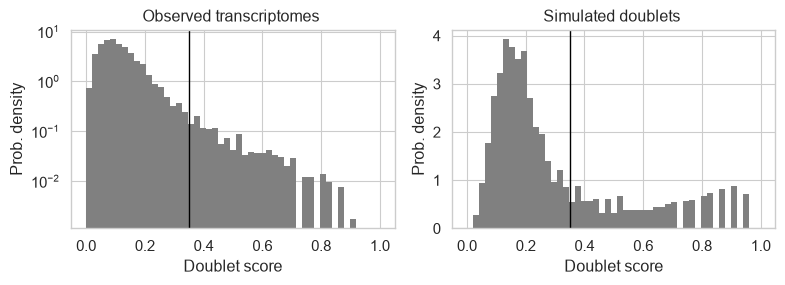

/tmp/ipykernel_9388/2582174727.py:6: UserWarning: Some cells have zero counts
  sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)


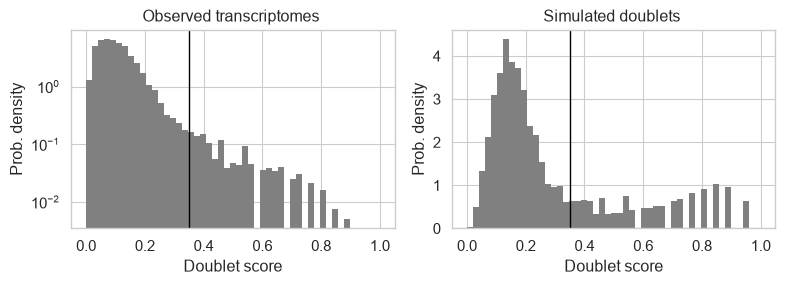

In [ ]:
# Creamos una lista vacía para guardar los resultados:
n_doublets_list = []

# Iteramos sobre el diccionario de tablas:
for name, table in adata_dict.items():
    sc.pp.scrublet(table, expected_doublet_rate=0.1, threshold=0.35, n_prin_comps=15)
    sc.pl.scrublet_score_distribution(table, show=True)

    # Sumamos todas las células que hayan dado True en la predicción:
    n_doublets = table.obs["predicted_doublet"].sum()

    # Guardamos el resultado en la lista:
    n_doublets_list.append(n_doublets)
    
# Añadimos los resultados al Data Frame global de métricas:
df_qc_metrics_prefilter['Número de dobletes celulares detectados'] = n_doublets_list

In [ ]:
# Calculamos el porcentaje de dobletes respecto al total de células detectadas con cada método
# de segmentación:
n_doublets_list = df_qc_metrics_prefilter["Número de dobletes celulares detectados"].astype(float)
cell_numbers_list = df_qc_metrics_prefilter["Nº total de células"].astype(float)

pct_doublets = (n_doublets_list / cell_numbers_list) * 100
# Añadimos los valores a la tabla global:
df_qc_metrics_prefilter['Dobletes celulares detectados respecto al total de células (%)'] = pct_doublets.round(2)

# Guardamos resultados como .csv e imprimimos la tabla global:
FILE_PATH = TABLES_PRE_DIR / "qc_metrics_prefilter.csv"
df_qc_metrics_prefilter.to_csv(FILE_PATH)
df_qc_metrics_prefilter

,Nº total de células,Área celular (µm²),Eficiencia de asignación global (%),Transcritos asignados por gen (%),Número total de transcritos por célula,Número de genes únicos por célula,Transcritos de los dos genes más expresados (%),Transcritos de los cinco genes más expresados (%),Densidad transcriptómica (transcritos/µm²),Número de dobletes celulares detectados,Dobletes celulares detectados respecto al total de células (%)
Xenium,34621,63.67 [41.68 - 91.35],78.3,79.59 [75.98 - 82.36],234.00 [86.00 - 437.00],189.00 [75.00 - 329.00],6.77 [5.18 - 9.26],11.45 [9.02 - 15.79],3.62 [1.71 - 5.87],797,2.30
Expansión nuclear,37065,83.90 [55.95 - 125.49],97.6,98.46 [97.28 - 99.18],287.00 [113.00 - 502.00],221.00 [95.00 - 363.00],6.94 [5.34 - 9.31],11.54 [9.17 - 15.44],3.61 [1.27 - 6.45],883,2.38
Cellpose,36352,76.54 [52.83 - 105.98],94.5,96.22 [93.92 - 97.69],264.00 [94.00 - 507.00],205.00 [80.00 - 366.00],7.11 [5.40 - 9.69],11.76 [9.23 - 16.36],3.53 [1.36 - 6.53],894,2.46
Baysor (sin prior),77781,31.70 [15.08 - 47.97],96.6,96.01 [92.86 - 97.62],113.00 [51.00 - 236.00],95.00 [45.00 - 184.00],8.33 [6.15 - 11.76],14.77 [11.32 - 21.21],4.57 [3.03 - 6.43],1646,2.12
Baysor (prior nuclear),57006,47.91 [30.63 - 62.24],97.5,97.45 [95.68 - 98.46],193.00 [89.00 - 328.00],154.00 [74.00 - 250.00],7.61 [5.54 - 10.57],13.04 [10.04 - 18.18],4.43 [2.75 - 6.41],1528,2.68
Baysor (prior celular),39260,68.08 [41.36 - 98.36],98.4,98.59 [97.58 - 99.18],250.00 [106.00 - 488.00],192.00 [88.00 - 351.00],7.25 [5.48 - 10.00],12.11 [9.49 - 16.78],3.86 [2.24 - 6.42],940,2.39


In [85]:
sdata_complete.tables["table_cellpose"].obs

,cell_ID,fov_labels,cell_area_pixels2,cell_area_microns2,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_2_genes,pct_counts_in_top_5_genes,transcripts_density
cells,,,,,,,,,,,
1128_cellpose_segmentation_mask_bdc75c15,1128,cellpose_segmentation_mask,4920.0,222.168762,142,4.962845,195.0,5.278115,6.666667,12.820513,0.877711
1192_cellpose_segmentation_mask_bdc75c15,1192,cellpose_segmentation_mask,1416.0,63.941254,37,3.637586,44.0,3.806663,15.909091,27.272727,0.688132
1224_cellpose_segmentation_mask_bdc75c15,1224,cellpose_segmentation_mask,4290.0,193.720322,82,4.418841,95.0,4.564348,6.315789,12.631579,0.490398
1288_cellpose_segmentation_mask_bdc75c15,1288,cellpose_segmentation_mask,3231.0,145.899857,92,4.532599,121.0,4.804021,11.570248,20.661157,0.829336
1304_cellpose_segmentation_mask_bdc75c15,1304,cellpose_segmentation_mask,1547.0,69.856720,12,2.564949,14.0,2.708050,28.571429,50.000000,0.200410
...,...,...,...,...,...,...,...,...,...,...,...
149516_cellpose_segmentation_mask_bdc75c15,149516,cellpose_segmentation_mask,521.0,23.526407,76,4.343805,92.0,4.532599,13.043478,19.565217,3.910499
149909_cellpose_segmentation_mask_bdc75c15,149909,cellpose_segmentation_mask,58.0,2.619063,16,2.833213,16.0,2.833213,12.500000,31.250000,6.109056
149940_cellpose_segmentation_mask_bdc75c15,149940,cellpose_segmentation_mask,1.0,0.045156,2,1.098612,2.0,1.098612,100.000000,100.000000,44.290657


In [ ]:
# Guardamos una copia del objeto, previo al filtrado, en un nuevo almacén .zarr:
sdata_complete.write(SDATA_COMPLETE_PRE_PATH, overwrite=True)

# 8. Filtrado de dobletes, células y genes de bajo conteo y métricas de calidad post-filtrado
En primer lugar usamos `Scanpy` para filtrar todas aquellas células que presenten un bajo número de transcritos y aquellos genes que aparezcan en un número bajo de células. También podemos eliminar todas aquellas células que han sido marcadas como dobletes por `Scrublet`.

In [ ]:
# Cargamos en una nueva variable:
sdata_complete_prefilter = sd.read_zarr(SDATA_COMPLETE_PRE_PATH)

no parent found for <ome_zarr.reader.Label object at 0x754d6da0e9c0>: None
no parent found for <ome_zarr.reader.Label object at 0x754d6d84bec0>: None
no parent found for <ome_zarr.reader.Label object at 0x754e403e7a10>: None
no parent found for <ome_zarr.reader.Label object at 0x754d6da220c0>: None


In [92]:
# Iniciamos el filtrado.

# Lista de las tablas a procesar:
tables_list = list(sdata_complete_prefilter.tables.keys())

for table_name in tables_list:
    adata = sdata_complete_prefilter.tables[table_name]

    # Filtramos células y genes con scanpy:
    sc.pp.filter_cells(adata, min_counts=10)
    sc.pp.filter_genes(adata, min_cells=5)

    # Creamos una máscara con todas las células que han sido marcadas como dobletes:
    is_doublets_mask = (adata.obs["predicted_doublet"].astype(str) == "True").values # Al guardar en .zarr dejan de ser booleans y se transforman en strings
    
    # Filtramos la tabla usando la máscara (invertida, ~) para coger todas aquellas células que no han sido marcadas como dobletes:
    filtered_table = adata[~is_doublets_mask].copy()

    # Guardamos la tabla en la memoria, sobrescribiendo la tabla original:
    sdata_complete_prefilter.tables[table_name] = filtered_table

Ahora volvemos a calcular todas las métricas tras haber filtrado (excepto los dobletes celulares por motivos obvios).

## 8.1. Número de células detectadas (post-filtrado)

In [93]:
# Actualizamos el diccionario que creamos para iterar sobre las tablas para que use las
# tablas del nuevo objeto:
adata_dict = {
    "Xenium": sdata_complete_prefilter.tables["table_xenium_default"],
    "Expansión nuclear": sdata_complete_prefilter.tables["table_nucleus_expanded"],
    "Cellpose": sdata_complete_prefilter.tables["table_cellpose"],
    "Baysor (sin prior)": sdata_complete_prefilter.tables["table_baysor_no_prior"],
    "Baysor (prior nuclear)": sdata_complete_prefilter.tables["table_baysor_nuclear_mask_prior"],
    "Baysor (prior celular)": sdata_complete_prefilter.tables["table_baysor_cellpose_cito_prior"]
}

# Inicializamos un DataFrame vacío para las métricas post-filtrado:
df_qc_metrics_postfilter = pd.DataFrame(index=adata_dict.keys())

# Iteramos sobre el diccionario para acceder al número de células detectadas en cada segmentación (n_obs)
cell_numbers_post = []
for name, table in adata_dict.items():
    cell_numbers_post.append(table.n_obs)

# Añadimos los resultados al DataFrame en una nueva columna:
df_qc_metrics_postfilter["Nº total de células"] = cell_numbers_post

# Comprobamos la tabla global que hemos creado:
df_qc_metrics_postfilter

,Nº total de células
Xenium,33346
Expansión nuclear,35967
Cellpose,34977
Baysor (sin prior),75602
Baysor (prior nuclear),55220
Baysor (prior celular),38014


## 8.2. Área de las células (post-filtro)


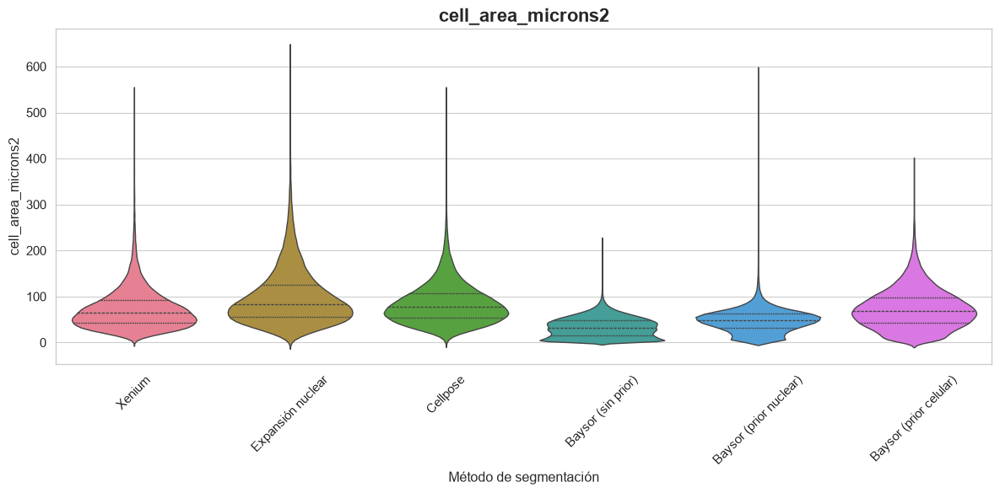

In [95]:
# Creamos la gráfica de violines correspondiente a las áreas celulares:
anndata_violin_plot(adata_dict, "cell_area_microns2", GRAPHS_POST_DIR)

In [96]:
# Creamos un diccionario para almacenar los resultados de los tests de normalidad
# de cada métrica, por si necesitamos acceder a ellos posteriormente:
normaltest_results_post_dict = {}

# Realizamos el test de normalidad sobre el área de las células:
normaltest_results_post_dict["cell_area_microns2"] = anndata_normaltest(adata_dict, "cell_area_microns2", TABLES_POST_DIR)

Resultados del test de normalidad para "cell_area_microns2"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium                    12786.568183      0.0                            NO
Expansión nuclear          9889.569336      0.0                            NO
Cellpose                  10570.843750      0.0                            NO
Baysor (sin prior)         2556.554117      0.0                            NO
Baysor (prior nuclear)    21598.031158      0.0                            NO
Baysor (prior celular)     5347.354228      0.0                            NO
Resultados guardados en "results/statistics/postfilter/tables/cell_area_microns2_normaltest.csv"


In [97]:
# Calculamos mediana y cuartiles de los datos del área celular.
area_results_post = anndata_median_results(adata_dict, "cell_area_microns2")

# Añadimos los resultados al Data Frame global de métricas:
df_qc_metrics_postfilter["Área celular (µm²)"] = area_results_post

# Comprobamos la tabla global:
df_qc_metrics_postfilter


,Nº total de células,Área celular (µm²)
Xenium,33346,64.26 [42.67 - 91.76]
Expansión nuclear,35967,83.95 [56.22 - 125.60]
Cellpose,34977,76.95 [53.56 - 106.34]
Baysor (sin prior),75602,32.06 [15.41 - 48.29]
Baysor (prior nuclear),55220,48.33 [31.34 - 62.55]
Baysor (prior celular),38014,68.78 [42.36 - 98.83]


In [98]:
# Creamos un diccionario para almacenar los resultados de los análisis estadísticos
# de cada métrica de calidad:
statistics_results_post_dict = {}

# Realizamos el análisis estadístico:
statistics_results_post_dict["cell_area_microns2"] = anndata_statistics(adata_dict, "cell_area_microns2", TABLES_POST_DIR)

Análisis estadístico de "cell_area_microns2"
         Método vs Xenium  P-valor corregido  Diferencias significativas  \
0       Expansión nuclear       0.000000e+00                        True   
1                Cellpose       0.000000e+00                        True   
2      Baysor (sin prior)       0.000000e+00                        True   
3  Baysor (prior nuclear)       0.000000e+00                        True   
4  Baysor (prior celular)       8.881774e-14                        True   

   Dif. medianas (cell_area_microns2)  Delta de Cliff Magnitud del efecto  
0                           19.688127        0.272047             Pequeño  
1                           12.688905        0.185253             Pequeño  
2                          -32.195212       -0.623608              Grande  
3                          -15.924580       -0.358839               Medio  
4                            4.518784        0.032301      Insignificante  
Resultados guardados en "results/statistic

## 8.3. Eficiencia de asignación global y porcentaje de transcritos asignados para cada gen (post-filtrado)

In [101]:
# 1. Total de transcritos físicos absolutos en el tejido:
total_transcripts_raw = len(sdata_complete_prefilter.points["transcripts_global"])

# 2. Total de transcritos asignados por el método:
efficiency_list_post = []
for name, table in adata_dict.items():
    assigned_transcripts= table.X.sum()
    efficiency = f"{(float(assigned_transcripts) / total_transcripts_raw) * 100:.1f}"
    efficiency_list_post.append(efficiency)

# Añadimos la fila al DataFrame global:
df_qc_metrics_postfilter["Eficiencia de asignación global (%)"] = efficiency_list_post

# Comprobamos la tabla global que hemos creado:
df_qc_metrics_postfilter

,Nº total de células,Área celular (µm²),Eficiencia de asignación global (%)
Xenium,33346,64.26 [42.67 - 91.76],76.6
Expansión nuclear,35967,83.95 [56.22 - 125.60],95.5
Cellpose,34977,76.95 [53.56 - 106.34],92.4
Baysor (sin prior),75602,32.06 [15.41 - 48.29],95.2
Baysor (prior nuclear),55220,48.33 [31.34 - 62.55],96.0
Baysor (prior celular),38014,68.78 [42.36 - 98.83],96.7


In [102]:
# Creamos un Data Frame vacío para almacenar en él todas las proporciones
# de transcritos de todos los métodos:
df_proportions_kept_post = pd.DataFrame()

# Cargamos la lista de transcritos desde el formato Dask a un DataFrame:
df_points = sdata_complete_prefilter.points["transcripts_global"].compute()

# Hacemos un recuento del número de veces que aparece el nombre de cada gen en toda la lista
# de transcritos detectados en la región de interés. Esto constituye las lecturas crudas (raw_counts):
raw_counts = df_points["gene"].value_counts().rename("raw_counts")

# Aquellos genes que presentan un número bajo de conteos en todo el tejido generan mucho ruido
# estadístico, ya que cualquier mínimo cambio en las asignaciones a células puede hacer variar
# mucho el valor de proportion_kept. Para evitar esto, filtramos aquellos genes con menos de 100
# copias totales en el tejido:
genes_before = len(raw_counts)
raw_counts = raw_counts[raw_counts > 100]
genes_after = len(raw_counts)
logger.info(f"Nº de genes descartados por tener un bajo conteo: {genes_before - genes_after}")

# Iteramos sobre adata_dict:
for name, table in adata_dict.items():
    # Aplastamos verticalmente la matriz de conteos, es decir, sumamos los transcritos detectados
    # de cada gen (columna) en todas las células (filas) mediante "axis = 0". El resultado se transforma
    # en un vector de valores únicos que tienen asociados los nombres de los genes correspondientes,
    # generando así una lista similar a la de las lecturas crudas, pero que contiene solo aquellos transcritos
    # que han sido asignados a alguna célula.
    assigned_counts = pd.Series(
        np.ravel(table.X.sum(axis=0)),
        index=table.var_names,
        name="assigned_counts"
    )
    # Creamos un DataFrame concatenando ambas listas de conteos (ordenados según el índice que es el nombre del gen
    # en ambos casos, y haciendo un inner join para que no aparezcan aquellos genes con bajos conteos que fueron
    # eliminados anteriormente). Para los genes donde la segmentación no ha asignado transcritos, el valor es "NA". Para
    # evitar problemas con los cálculos posteriores, cambiamos esos NA por ceros.
    df_proportions_method = pd.concat([raw_counts, assigned_counts], axis=1, join="inner").fillna(0)

    # Calculamos el porcentaje de transcritos que han sido asignados a células durante la segmentación:
    df_proportions_method["pct_proportion_kept"] = (df_proportions_method["assigned_counts"] / df_proportions_method["raw_counts"]) * 100

    # Extraemos los valores de pct_proportion_kept de todos los genes de cada método para hacer estadísticas:
    df_proportions_kept_post[name] = df_proportions_method["pct_proportion_kept"]

    # Ordenamos descendentemente los genes por pct_proportion_kept, para ver aquellos que han sido peor asignados por
    # los distintos métodos de transcripción:
    df_proportions_method = df_proportions_method.sort_values("pct_proportion_kept")

    # Guardamos los resultados en un archivo .csv para cada segmentación, por si posteriormente queremos comprobar
    # la proporción de transcritos asignados para algún gen en concreto. 
    method_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "") # Adecuamos para nombrar archivos
    FILE_PATH = PROP_KEPT_POST_DIR / f"{method_name}.csv"
    df_proportions_method.to_csv(FILE_PATH)

# Comprobamos la tabla resultante con las proporciones de trancritos asignados para cada gen en todos los métodos:
print(df_proportions_kept_post)

2026-09-25 15:54:31.116 | INFO     | __main__:<module>:19 - Nº de genes descartados por tener un bajo conteo: 288


           Xenium  Expansión nuclear   Cellpose  Baysor (sin prior)  \
EEF1G   76.128611          96.189471  93.490098           96.592184   
H19     64.225965          97.686817  96.109004           98.135921   
CD47    83.294694          98.556735  97.426939           98.540408   
MYL9    58.071839          85.146548  75.277073           83.547536   
H3F3B   81.154828          96.692193  94.187131           96.458058   
...           ...                ...        ...                 ...   
MAGEA3  78.217822          99.009901  97.029703           92.079208   
NLGN3   69.306931          96.039604  94.059406           95.049505   
CUBN    88.118812          98.019802  95.049505           95.049505   
DAOA    70.297030          96.039604  91.089109           86.138614   
GPR22   79.207921          99.009901  97.029703           84.158416   

        Baysor (prior nuclear)  Baysor (prior celular)  
EEF1G                97.021587               97.261309  
H19                  98.180534   

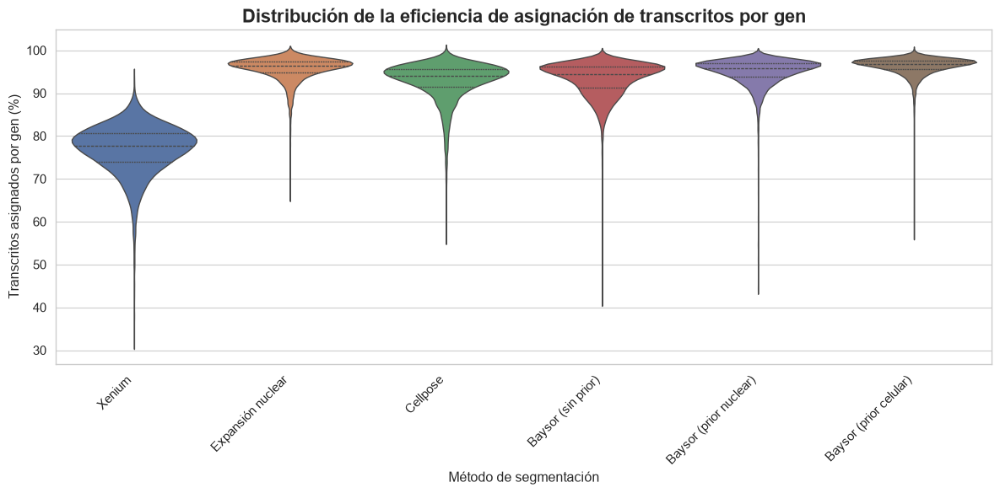

In [103]:
# Visualizamos los valores de proportions_kept_post mediante un diagrama de violín
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_proportions_kept_post, inner='quartile')
plt.title('Distribución de la eficiencia de asignación de transcritos por gen', weight="bold", fontsize=16)
plt.ylabel('Transcritos asignados por gen (%)')
plt.xlabel('Método de segmentación')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
TIFF_PATH = GRAPHS_POST_DIR / "violin_proportion_kept.tiff"
plt.savefig(TIFF_PATH, dpi=300, bbox_inches="tight")
plt.show()

In [104]:
# Test de normalidad:

methods_list = []
normaltest_statistics = [] # Para almacenar el valor del estadístico
normaltest_pvalue = [] # Para almacenar el p-valor de cada test
normaltest_is_normal = [] # Para indicar si el resultado sigue una distribución normal o no

# Iteramos sobre la tabla df_proportions_kept_post:
for colname, values in df_proportions_kept_post.items():
       
    # Test de normalidad de D'Agostino-Pearson.
    statistic, p_value = stats.normaltest(values)
    
    alpha = 0.05
    if p_value > alpha:
        is_normal = "SI"
    else:
        is_normal = "NO"
    methods_list.append(colname)
    normaltest_statistics.append(statistic)
    normaltest_pvalue.append(p_value)
    normaltest_is_normal.append(is_normal)

# Creamos un Data Frame para almacenar los resultados del test de normalidad:
df_normaltest = pd.DataFrame({
    # Determinamos los nombres de cada columna y el contenido
    "Score del test": normaltest_statistics,
    "p-valor": normaltest_pvalue,
    "Sigue una distribución normal": normaltest_is_normal
}, index=methods_list) # Usamos cada método de segmentación como índice:
df_normaltest.index.name = "Método de segmentación"

# Guardamos el resultado del test en el diccionario de tests creado anteriormente:
normaltest_results_post_dict["pct_proportion_kept"] = df_normaltest

# Guardamos resultados como .csv e imprimimos la tabla:
FILE_PATH = TABLES_POST_DIR / "pct_proportion_kept_normaltest.csv"
df_normaltest.to_csv(FILE_PATH)
print('Resultados del test de normalidad para "pct_proportion_kept"')
print(df_normaltest)
print(f'Resultados guardados en "{FILE_PATH}"')

Resultados del test de normalidad para "pct_proportion_kept"
                        Score del test        p-valor  \
Método de segmentación                                  
Xenium                     1257.188182  1.011707e-273   
Expansión nuclear          2882.528741   0.000000e+00   
Cellpose                   2297.435427   0.000000e+00   
Baysor (sin prior)         2851.842106   0.000000e+00   
Baysor (prior nuclear)     4177.700816   0.000000e+00   
Baysor (prior celular)     5081.649984   0.000000e+00   

                       Sigue una distribución normal  
Método de segmentación                                
Xenium                                            NO  
Expansión nuclear                                 NO  
Cellpose                                          NO  
Baysor (sin prior)                                NO  
Baysor (prior nuclear)                            NO  
Baysor (prior celular)                            NO  
Resultados guardados en "results/statistic

In [105]:
# Calculamos mediana y [Q1, Q3] y guardamos en nuestro Data Frame global:
prop_kept_list_post = []

for colname, values in df_proportions_kept_post.items():
       
    median = np.median(values)
    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)
    text_for_table = f"{median:.2f} [{q1:.2f} - {q3:.2f}]"
    prop_kept_list_post.append(text_for_table)

# Añadimos los resultados al Data Frame global de métricas:
df_qc_metrics_postfilter["Transcritos asignados por gen (%)"] = prop_kept_list_post

# Comprobamos la tabla global:
df_qc_metrics_postfilter


,Nº total de células,Área celular (µm²),Eficiencia de asignación global (%),Transcritos asignados por gen (%)
Xenium,33346,64.26 [42.67 - 91.76],76.6,77.78 [74.04 - 80.75]
Expansión nuclear,35967,83.95 [56.22 - 125.60],95.5,96.41 [94.87 - 97.47]
Cellpose,34977,76.95 [53.56 - 106.34],92.4,94.00 [91.40 - 95.70]
Baysor (sin prior),75602,32.06 [15.41 - 48.29],95.2,94.45 [91.22 - 96.18]
Baysor (prior nuclear),55220,48.33 [31.34 - 62.55],96.0,95.80 [93.81 - 97.03]
Baysor (prior celular),38014,68.78 [42.36 - 98.83],96.7,96.88 [95.65 - 97.67]


In [106]:
# Procedemos con el análisis estadístico.

# Extraemos los valores de proportion_kept del control:
control_key = "Xenium" 
prop_kept_xenium = df_proportions_kept_post["Xenium"]
median_xenium = np.median(prop_kept_xenium)
n_xenium = len(prop_kept_xenium) # Necesario para la Delta de Cliff

# Reiniciamos listas para almacenar los resultados:
methods = []
pvalues_list = []
median_diff_list = []
dcliff_list = []
dcliff_eval_list = []

# Iteramos sobre los métodos:
for colname, values in df_proportions_kept_post.items():
    if colname == control_key:
        continue # Saltamos el control para no compararlo consigo mismo.
        
    method_prop_kept = values
    n_method = len(method_prop_kept)
    
    # Hacemos el test no paramétrico de Mann-Whitney U:
    stat, p_val = stats.mannwhitneyu(method_prop_kept, prop_kept_xenium, alternative='two-sided')
    
    # Tamaño del efecto 1: diferencia absoluta de medianas
    median_diff = np.median(method_prop_kept) - median_xenium
    
    # Tamaño del efecto 2: Delta de Cliff calculada a partir de U de Mann-Whitney,
    # ver como ejemplo este paquete de R https://rdrr.io/cran/rcompanion/man/cliffDelta.html
    cliff_d = 2 * ((stat / (n_method * n_xenium)) - 0.5)

    methods.append(colname)
    pvalues_list.append(p_val)
    median_diff_list.append(median_diff)
    dcliff_list.append(cliff_d)
    dcliff_eval_list.append(evaluate_dcliff(cliff_d))

# Realizamos la corrección por comparaciones múltiples (Holm-Bonferroni):
reject, corrected_pvalue, _, _ = smm.multipletests(pvalues_list, alpha=0.05, method='holm')

# Generamos la tabla resumen
df_statistics = pd.DataFrame({
    'Método vs Xenium': methods,
    'P-valor corregido': corrected_pvalue,
    'Diferencias significativas': reject,
    'Dif. medianas (% transcritos asignados)': median_diff_list,
    'Delta de Cliff': dcliff_list,
    'Magnitud del efecto': dcliff_eval_list
})

# Añadimos los resultados al diccionario de tests estadísticos:
statistics_results_post_dict["pct_prop_kept"] = df_statistics

# Guardamos resultados como .csv y comprobamos la tabla:
FILE_PATH = TABLES_POST_DIR / "pct_prop_kept_statistics.csv"
df_statistics.to_csv(FILE_PATH, index=False)
df_statistics

,Método vs Xenium,P-valor corregido,Diferencias significativas,Dif. medianas (% transcritos asignados),Delta de Cliff,Magnitud del efecto
0,Expansión nuclear,0.0,True,18.630684,0.994380,Grande
1,Cellpose,0.0,True,16.225337,0.953028,Grande
2,Baysor (sin prior),0.0,True,16.676448,0.980956,Grande
3,Baysor (prior nuclear),0.0,True,18.019420,0.991069,Grande
4,Baysor (prior celular),0.0,True,19.097222,0.996092,Grande


## 8.4. Métricas de calidad generadas mediante Scanpy (post-filtrado)
Recalculamos las métricas de calidad tras haber hecho el filtrado:

In [108]:
# Creamos un bucle para iterar por cada tabla:
tables = list(sdata_complete_prefilter.tables.keys())

for item in tables:
    adata = sdata_complete_prefilter.tables[item]
    # Calculamos las métricas de calidad con scanpy.pp.calculate_qc_metrics:
    sc.pp.calculate_qc_metrics(adata, percent_top=(2, 5), inplace=True)

In [ ]:
# Recalculamos la densidad transcriptómica y la añadimos a las correspondientes tablas:
tables = list(sdata_complete_prefilter.tables.keys())

for item in tables:
    adata = sdata_complete_prefilter.tables[item]
    adata.obs["transcripts_density"] = adata.obs["total_counts"] / adata.obs["cell_area_microns2"] 

In [112]:
# Creamos una lista con las métricas de calidad que queremos analizar:
qc_metrics_list = [
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_in_top_2_genes",
    "pct_counts_in_top_5_genes",
    "transcripts_density"
]

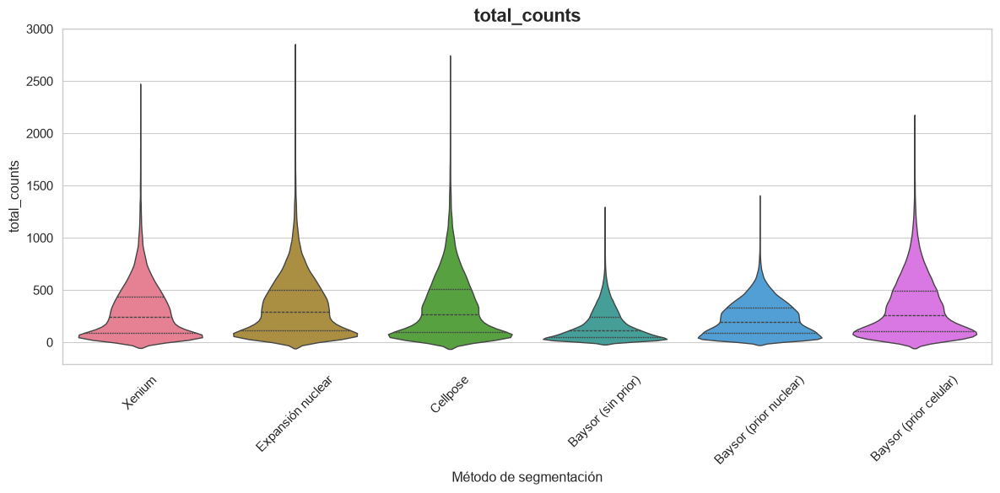

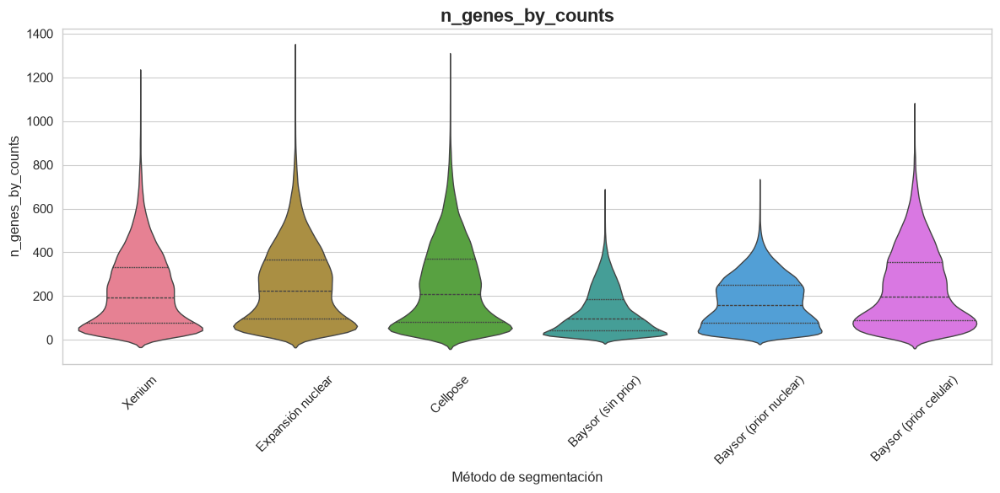

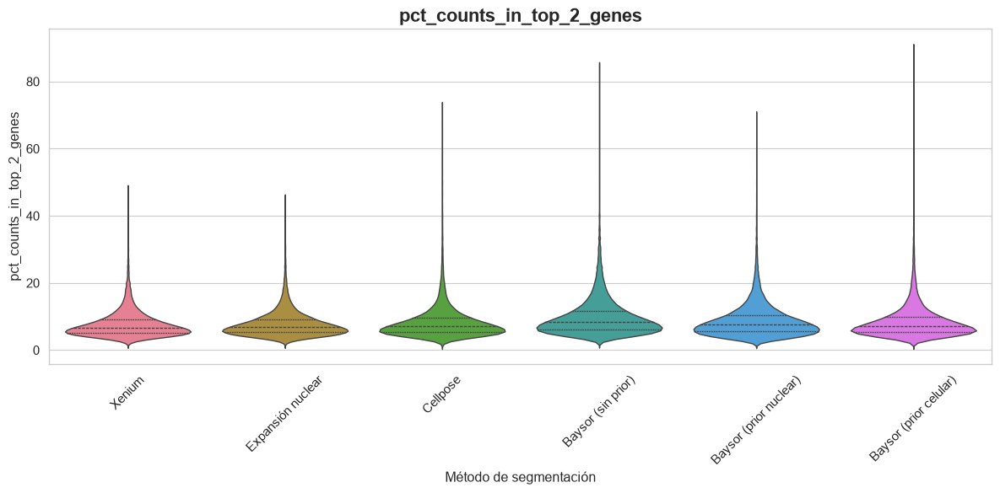

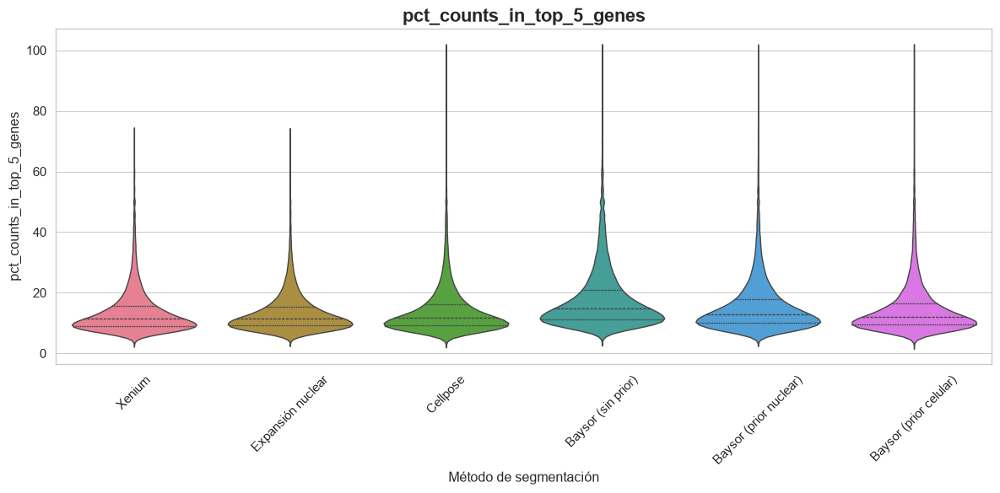

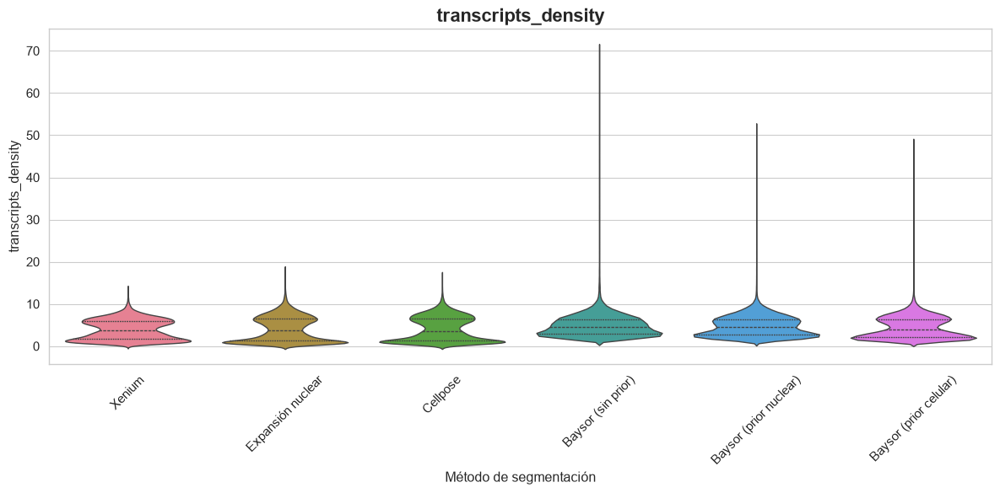

In [113]:
# Diagrama de violín para cada una de las métricas a analizar:
for item in qc_metrics_list:
    anndata_violin_plot(adata_dict, item, GRAPHS_POST_DIR)

In [114]:
# Test de normalidad para cada métrica:

for item in qc_metrics_list:
   normaltest_results_post_dict[item] = anndata_normaltest(adata_dict, item, TABLES_POST_DIR)

Resultados del test de normalidad para "total_counts"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium                     8174.705078      0.0                            NO
Expansión nuclear          7775.397461      0.0                            NO
Cellpose                   7737.234375      0.0                            NO
Baysor (sin prior)        17021.462891      0.0                            NO
Baysor (prior nuclear)     5421.688965      0.0                            NO
Baysor (prior celular)     7128.053711      0.0                            NO
Resultados guardados en "results/statistics/postfilter/tables/total_counts_normaltest.csv"
Resultados del test de normalidad para "n_genes_by_counts"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium          

In [ ]:
# Calculamos medianas y [Q1, Q3] de cada métrica y guardamos en nuestro Data Frame global.

# Primero creamos un diccionario de mapeo donde asignamos el texto descriptivo de cada resultado
# a su métrica correspondiente de la lista qc_metrics_list:
qc_metrics_descriptions = {
    "total_counts": "Número total de transcritos por célula",
    "n_genes_by_counts": "Número de genes únicos por célula",
    "pct_counts_in_top_2_genes": "Transcritos de los dos genes más expresados (%)",
    "pct_counts_in_top_5_genes": "Transcritos de los cinco genes más expresados (%)",
    "transcripts_density": "Densidad transcriptómica (transcritos/µm²)"
}

# Iteramos sobre la lista de métricas:
for item in qc_metrics_list:
    # Calculamos medianas y [Q1, Q3]:
    results = anndata_median_results(adata_dict, item)

    # Buscamos en el diccionario de mapeo la descripción correspondiente:
    text = qc_metrics_descriptions.get(item)

    # Añadimos la fila con el texto correspondiente al Data Frame global:
    df_qc_metrics_postfilter[text] = results

# Guardamos resultados como .csv e imprimimos la tabla global:
FILE_PATH = TABLES_POST_DIR / "qc_metrics_postfilter.csv"
df_qc_metrics_postfilter.to_csv(FILE_PATH)
df_qc_metrics_postfilter

,Nº total de células,Área celular (µm²),Eficiencia de asignación global (%),Transcritos asignados por gen (%),Número total de transcritos por célula,Número de genes únicos por célula,Transcritos de los dos genes más expresados (%),Transcritos de los cinco genes más expresados (%),Densidad transcriptómica (transcritos/µm²)
Xenium,33346,64.26 [42.67 - 91.76],76.6,77.78 [74.04 - 80.75],240.00 [90.00 - 441.00],193.00 [79.00 - 332.00],6.73 [5.17 - 9.09],11.38 [9.00 - 15.56],3.74 [1.76 - 5.93]
Expansión nuclear,35967,83.95 [56.22 - 125.60],95.5,96.41 [94.87 - 97.47],290.00 [116.00 - 505.00],223.00 [97.00 - 365.00],6.94 [5.34 - 9.27],11.52 [9.17 - 15.32],3.68 [1.28 - 6.49]
Cellpose,34977,76.95 [53.56 - 106.34],92.4,94.00 [91.40 - 95.70],271.00 [98.00 - 513.00],209.00 [83.00 - 370.00],7.08 [5.40 - 9.57],11.70 [9.23 - 16.13],3.61 [1.40 - 6.58]
Baysor (sin prior),75602,32.06 [15.41 - 48.29],95.2,94.45 [91.22 - 96.18],115.00 [52.00 - 240.00],97.00 [45.00 - 186.00],8.33 [6.15 - 11.70],14.71 [11.31 - 20.97],4.58 [3.03 - 6.44]
Baysor (prior nuclear),55220,48.33 [31.34 - 62.55],96.0,95.80 [93.81 - 97.03],199.00 [92.00 - 332.00],157.00 [76.00 - 252.00],7.58 [5.53 - 10.53],12.97 [10.00 - 17.99],4.48 [2.77 - 6.44]
Baysor (prior celular),38014,68.78 [42.36 - 98.83],96.7,96.88 [95.65 - 97.67],257.00 [110.00 - 494.00],196.00 [90.25 - 355.00],7.23 [5.47 - 9.87],12.05 [9.47 - 16.59],3.88 [2.24 - 6.44]


In [116]:
# Análisis estadístico:
for item in qc_metrics_list:
    statistics_results_post_dict[item] = anndata_statistics(adata_dict, item, TABLES_POST_DIR)

Análisis estadístico de "total_counts"
         Método vs Xenium  P-valor corregido  Diferencias significativas  \
0       Expansión nuclear                0.0                        True   
1                Cellpose                0.0                        True   
2      Baysor (sin prior)                0.0                        True   
3  Baysor (prior nuclear)                0.0                        True   
4  Baysor (prior celular)                0.0                        True   

   Dif. medianas (total_counts)  Delta de Cliff Magnitud del efecto  
0                          50.0        0.103838      Insignificante  
1                          31.0        0.071284      Insignificante  
2                        -125.0       -0.328946             Pequeño  
3                         -41.0       -0.123312      Insignificante  
4                          17.0        0.065763      Insignificante  
Resultados guardados en "results/statistics/postfilter/tables/total_counts_statistic

In [119]:
# Exportamos los datos tras el filtrado a un nuevo almacén .zarr:
sdata_complete_prefilter.write(SDATA_COMPLETE_POST_PATH, overwrite=True)

# 9. Normalización de los datos, PCAs y clustering
Tras el filtrado de los datos se lleva a cabo un proceso de normalización para igualar posibles diferencias técnicas en el proceso de secuenciación de transcritos y para permitir la comparación relativa entre células al escalar todas a un mismo factor común, en este caso el número total de cuentas a lo largo de todos los genes. Posteriormente se aplica un logaritmo natural para comprimir valores altos de expresión de manera que todos los genes se puedan comparar dentro de una escala equiparable (sumando previamente 1 a los conteos para evitar errores matemáticos en todos aquellos genes que no se han detectado en cada célula). Por último, podemos seleccionar aquellos genes que presentan una alta variabilidad de manera que los análisis de componentes principales (PCAs) y los gráficos de *clustering* se basen únicamente en aquellos genes que de verdad marcan diferencias entre los distintos tipos celulares presentes en el tejido analizado.

Este apartado también se basa en la información respectiva presente en el [tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html#feature-selection) de `Scanpy`.


In [4]:
sdata_complete_postfilter = sd.read_zarr(SDATA_COMPLETE_POST_PATH)

no parent found for <ome_zarr.reader.Label object at 0x79db46976090>: None
no parent found for <ome_zarr.reader.Label object at 0x79db46b17e60>: None
no parent found for <ome_zarr.reader.Label object at 0x79db44737710>: None
no parent found for <ome_zarr.reader.Label object at 0x79db446ec9b0>: None


In [ ]:
# Iteramos sobre todas las tablas para normalizar los conteos presentes en ellas:
tables = list(sdata_complete_postfilter.tables.keys())

for table_name in tables:
    adata = sdata_complete_postfilter.tables[table_name]
    # Guardamos una copia cruda de la matriz de conteos, previa a la normalización, para usos posteriores:
    adata.layers["raw_counts"] = adata.X.copy()
    # Normalizamos los conteos totales de cada célula para que todas tengan el mismo númeor de transcritos totales:
    sc.pp.normalize_total(adata)
    # Realizamos el logaritmo natural (+1) de todos los datos:
    sc.pp.log1p(adata)

In [ ]:
# Guardamos el objeto final, con los datos normalizados, en un nuevo almacén .zarr:
sdata_complete_postfilter.write(SDATA_NORMALIZED_PATH)

In [3]:
# Volvemos a cargar el objeto final, con los datos normalizados, en una nueva variable:
sdata_normalized = sd.read_zarr(SDATA_NORMALIZED_PATH)

no parent found for <ome_zarr.reader.Label object at 0x746e69122960>: None
no parent found for <ome_zarr.reader.Label object at 0x746e62e42c90>: None
no parent found for <ome_zarr.reader.Label object at 0x746e62fb7770>: None
no parent found for <ome_zarr.reader.Label object at 0x746e62fb63c0>: None


Genes altamente variables en table_baysor_cellpose_cito_prior


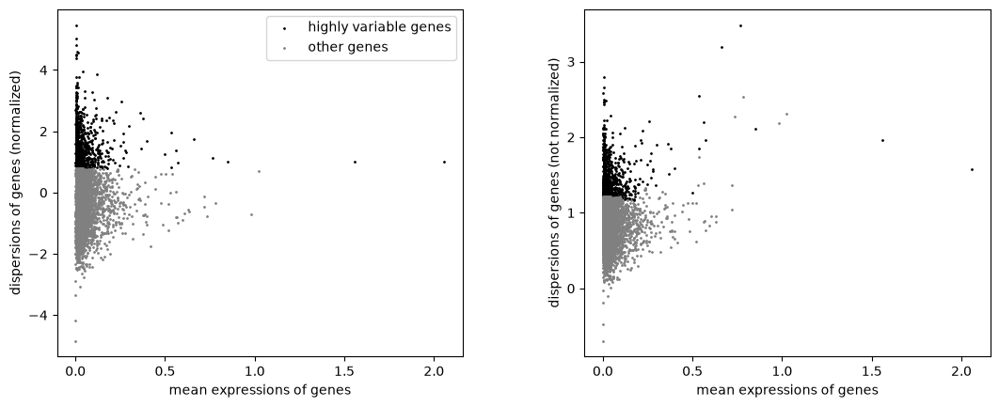

Genes altamente variables en table_baysor_no_prior


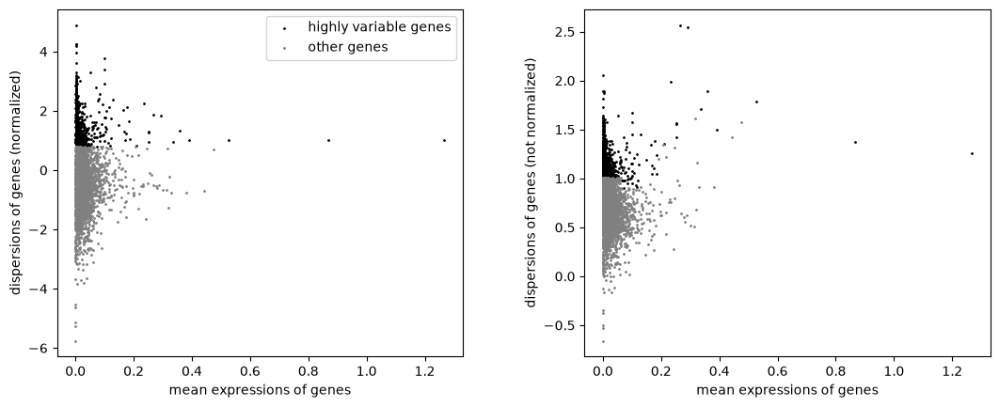

Genes altamente variables en table_baysor_nuclear_mask_prior


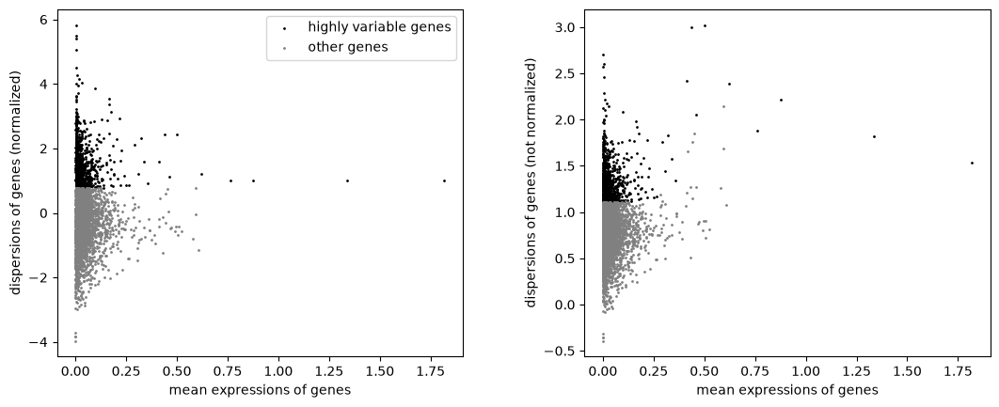

Genes altamente variables en table_cellpose


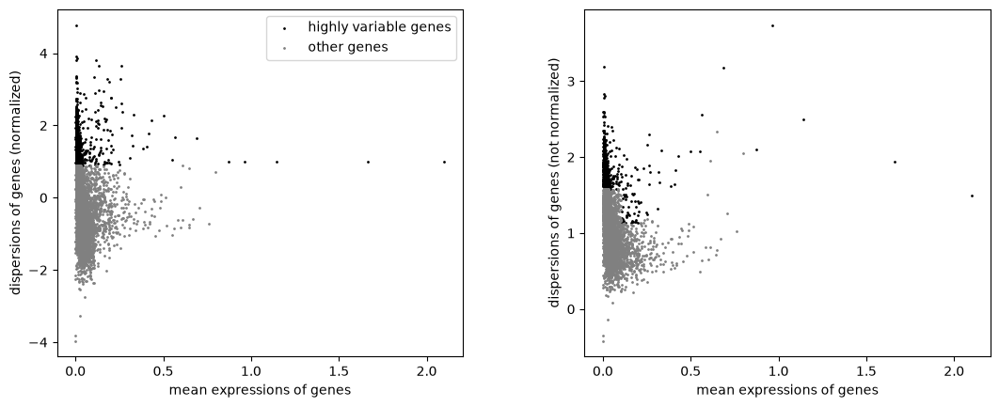

Genes altamente variables en table_nucleus_expanded


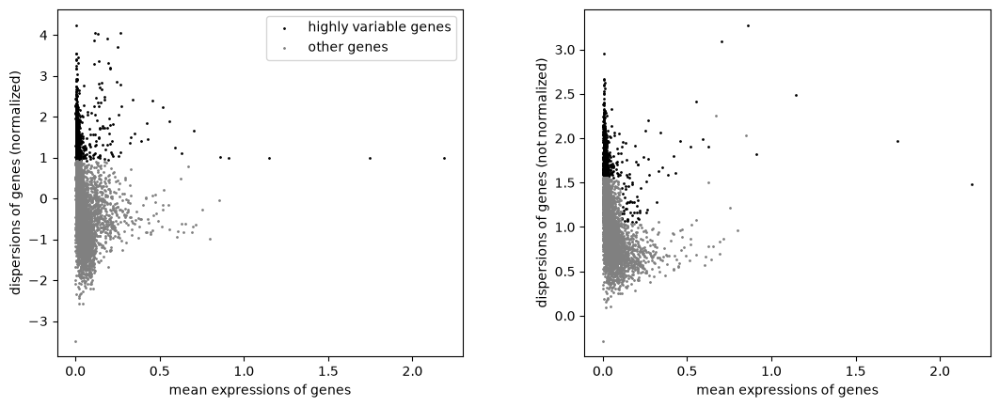

Genes altamente variables en table_xenium_default


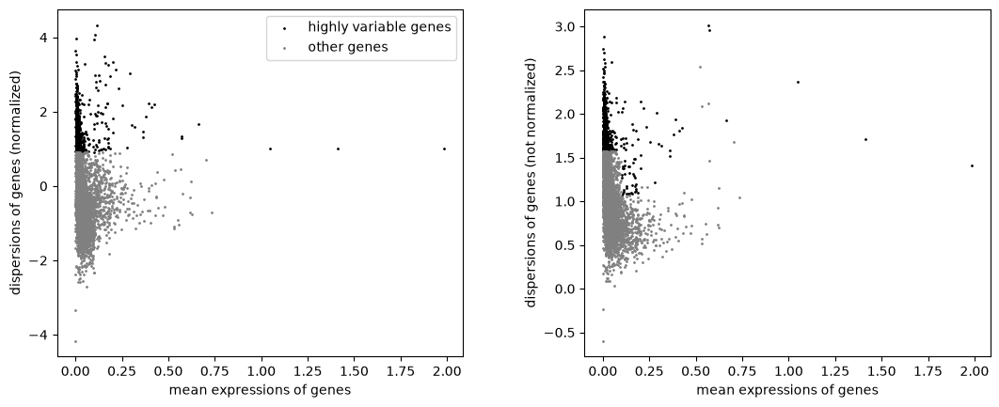

In [4]:
# A continuación seleccionamos aquellos genes que presentan una mayor variabilidad entre células,
# ya que son los que más información aportan para la posterior clasificación de las células en distintos tipos celulares.
# Para ello usamos la función sc.pp.highly_variable_genes() de Scanpy, que calcula la media y la dispersión de cada gen y
# selecciona aquellos que presentan una dispersión mayor a la esperada según su media.
tables = list(sdata_normalized.tables.keys())

for table_name in tables:
    adata = sdata_normalized.tables[table_name]
    sc.pp.highly_variable_genes(adata, n_top_genes=1000)
    print(f"Genes altamente variables en {table_name}")
    sc.pl.highly_variable_genes(adata)

En base a estos genes altamente variables, realizamos la reducción de dimensionalidad y el clustering de las células para cada tabla. Scanpy detecta debidamente la etiqueta que se ha añadido a cada gen indicando si es altamente variable o no.

Comenzamos por el análisis de PCA. En primer lugar, podemos calcular 50 componentes principales (PCs) y plotear el ratio de varianzas para ver el número adecuado de PCs que mejor explican la varianza de los datos.

Ploteando varianza de PCs para table_baysor_cellpose_cito_prior...


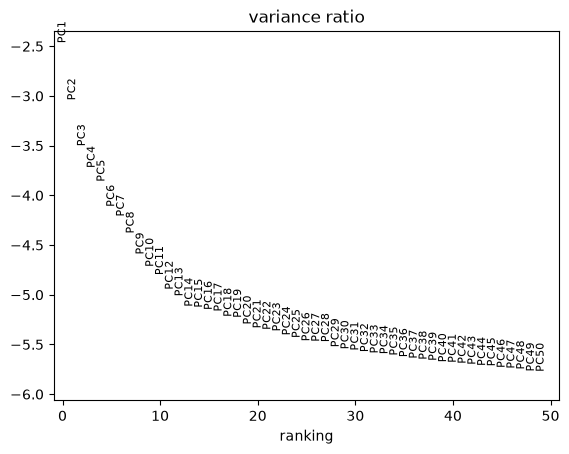

Ploteando varianza de PCs para table_baysor_no_prior...


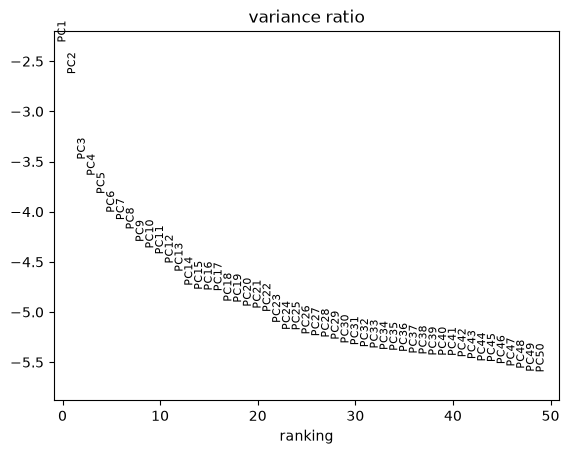

Ploteando varianza de PCs para table_baysor_nuclear_mask_prior...


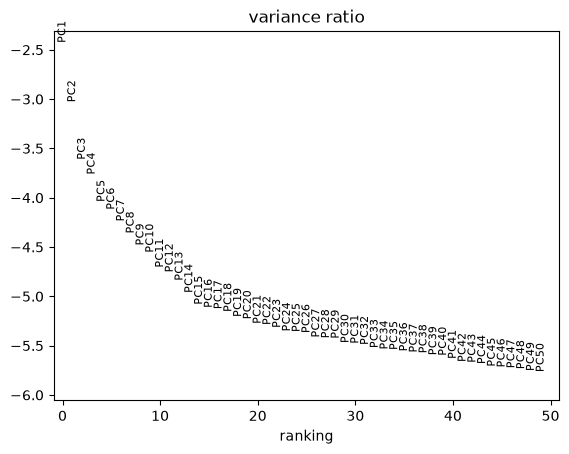

Ploteando varianza de PCs para table_cellpose...


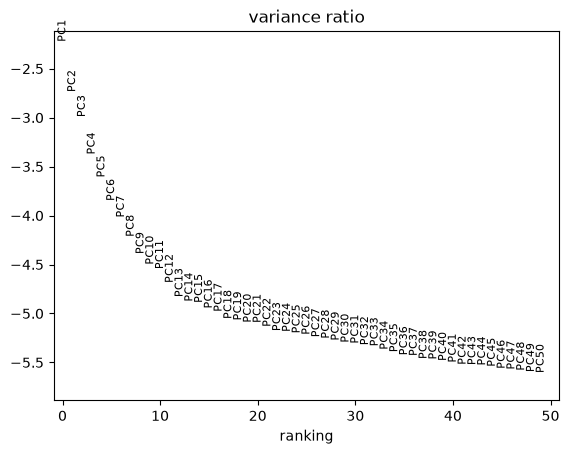

Ploteando varianza de PCs para table_nucleus_expanded...


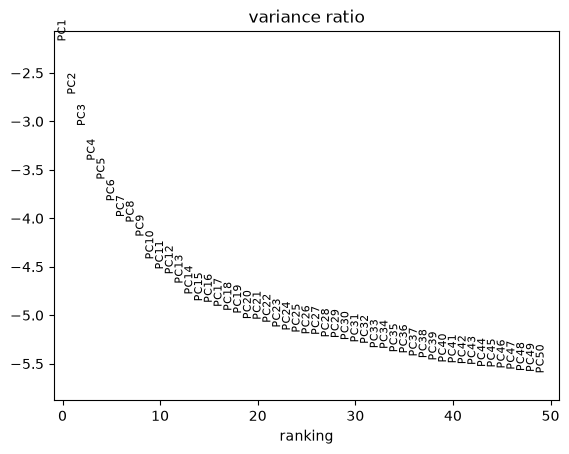

Ploteando varianza de PCs para table_xenium_default...


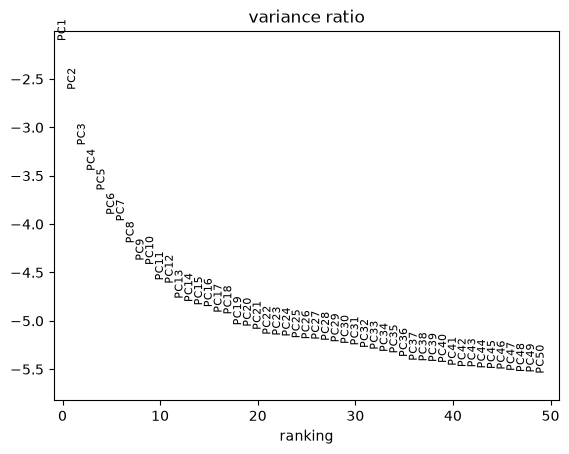

In [5]:

tables = list(sdata_normalized.tables.keys())

for table_name in tables:
    adata = sdata_normalized.tables[table_name]
    print(f"Ploteando varianza de PCs para {table_name}...")
    sc.tl.pca(adata)
    sc.pl.pca_variance_ratio(adata, log=True, n_pcs=50)

En la mayoría de los casos, a partir de los 20 primeros componentes la varianza disminuye lentamente. Por lo tanto, procedemos a realizar un PCA usando solo 20 PCs. Posteriormente se realiza un cálculo de grafos de vecindad (K-Nearest Neighbors), donde se determinan matemáticamente qué células se parecen más entre sí en base a los 20 PCs; un gráfico de los resultados en dos dimensiones (gráfico UMAP); y finalmente, la agrupación de las células más parecidas en clústeres (gráfico de Leiden).

Calculando PCA, KNN y clústeres para Xenium...


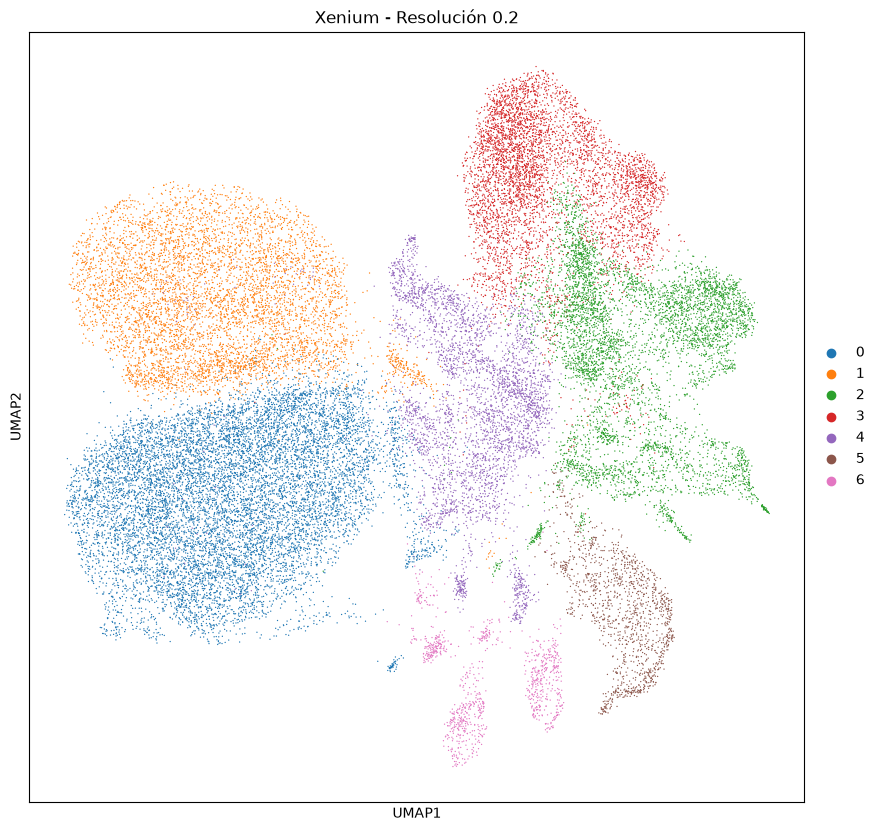

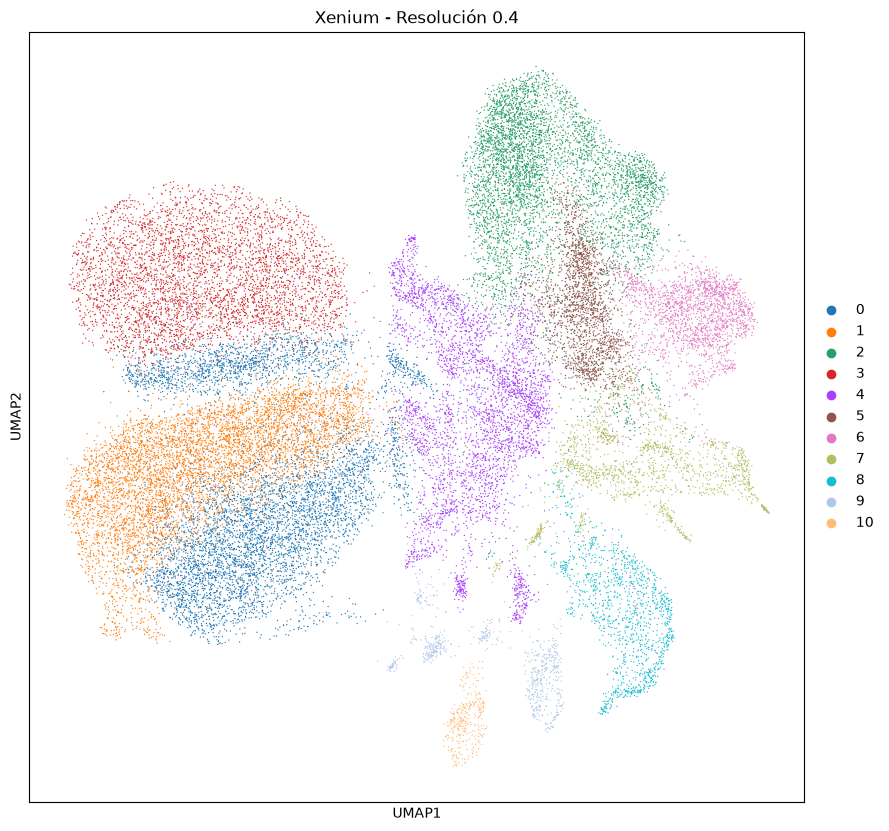

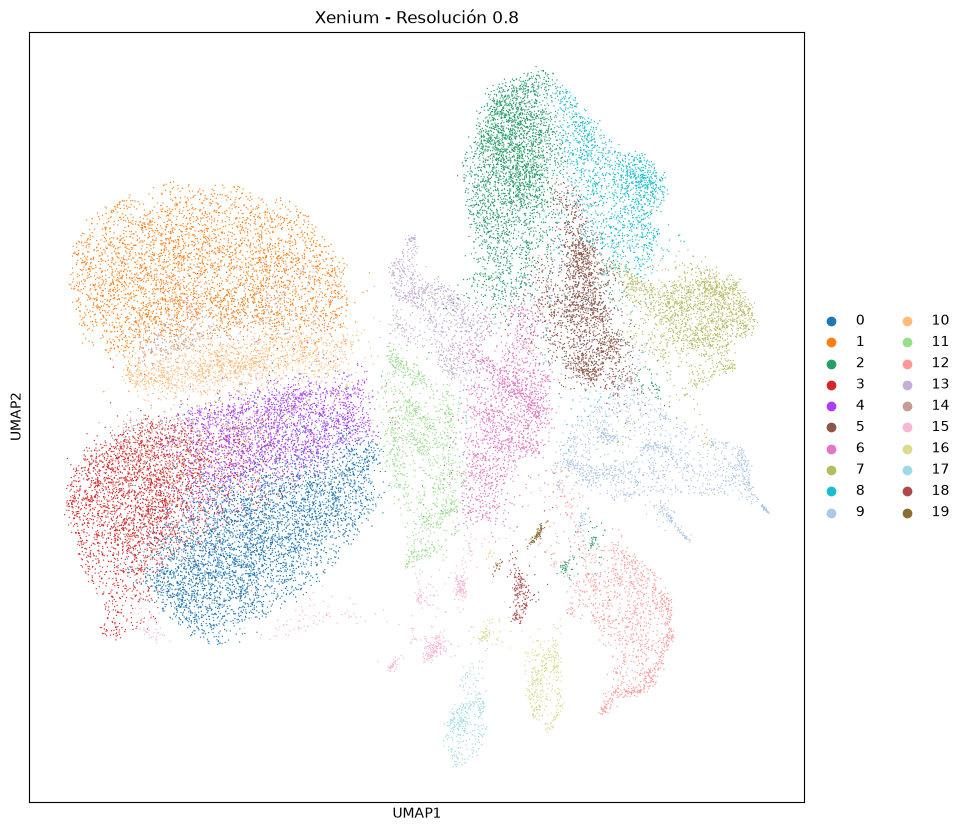

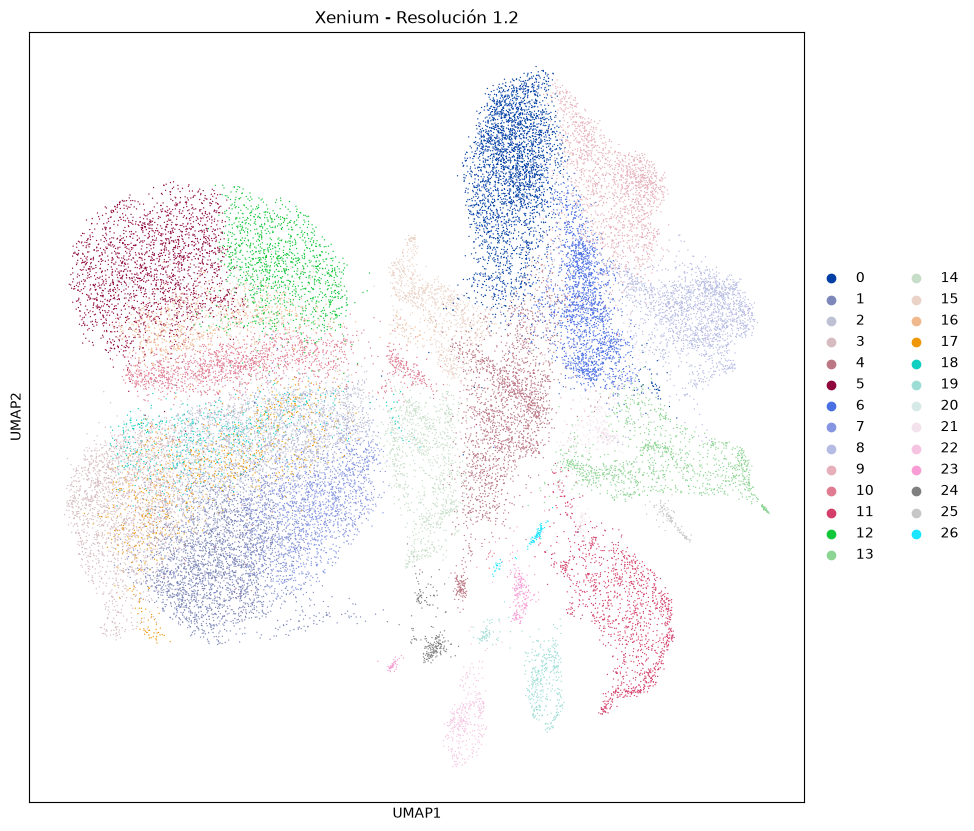

Calculando PCA, KNN y clústeres para Expansión nuclear...


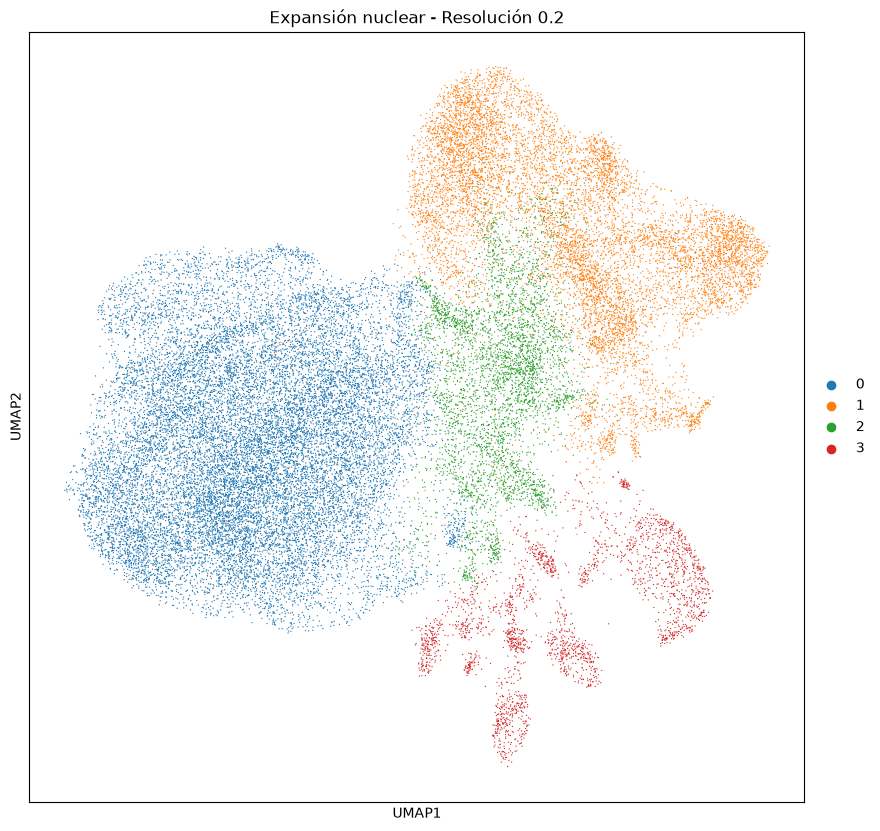

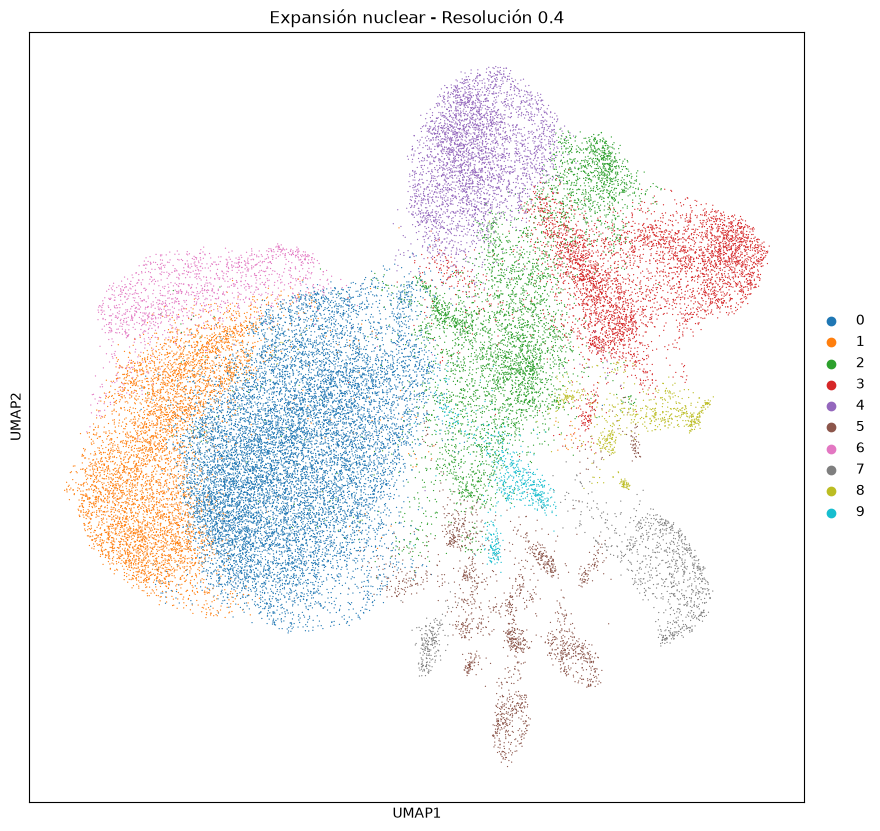

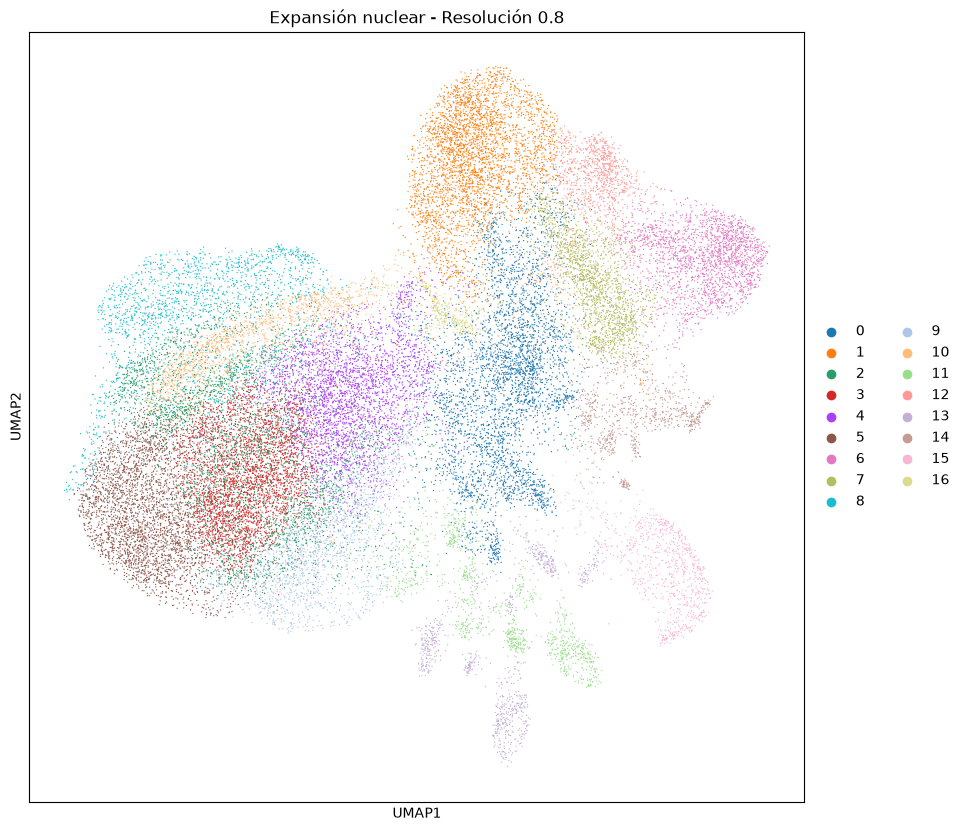

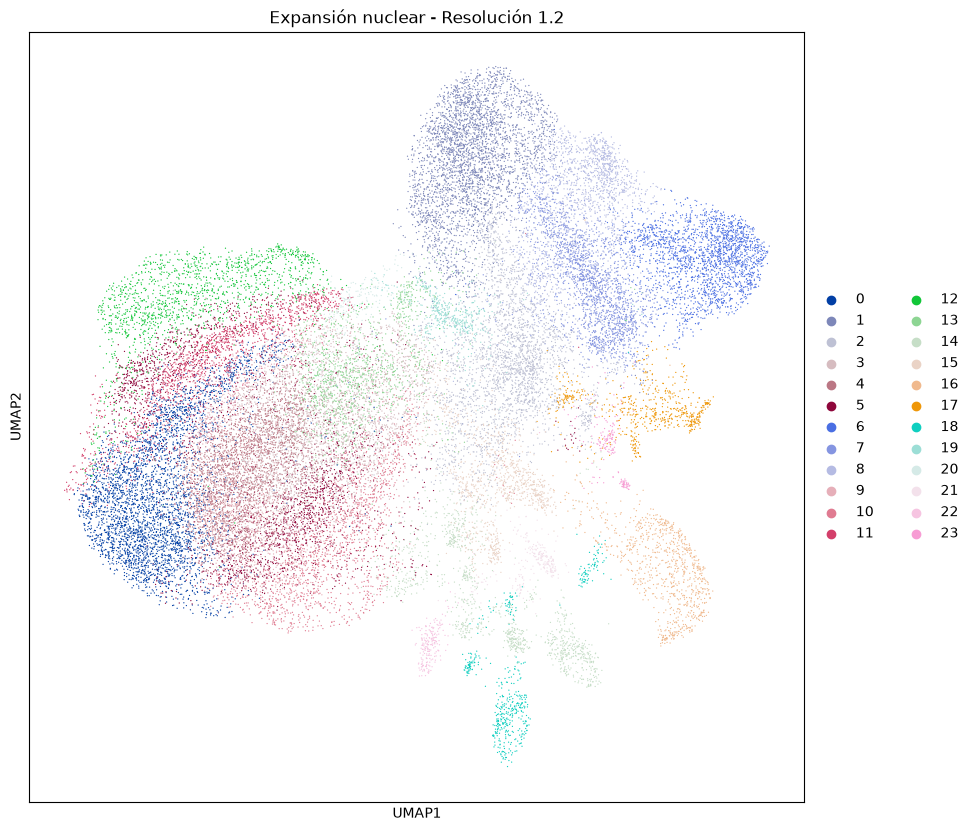

Calculando PCA, KNN y clústeres para Cellpose...


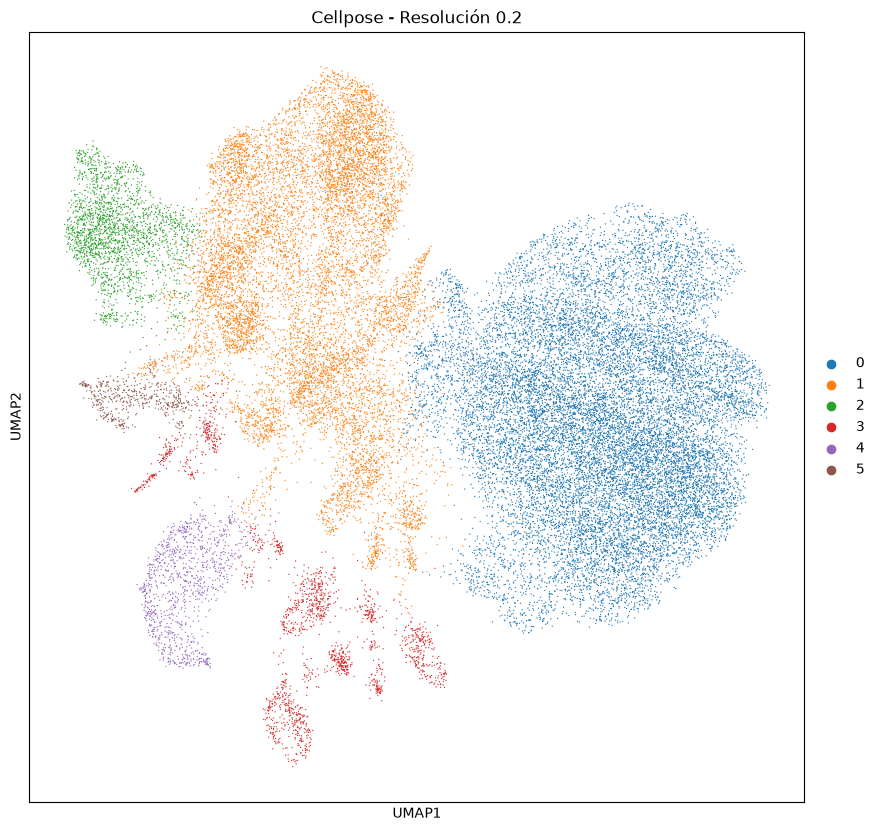

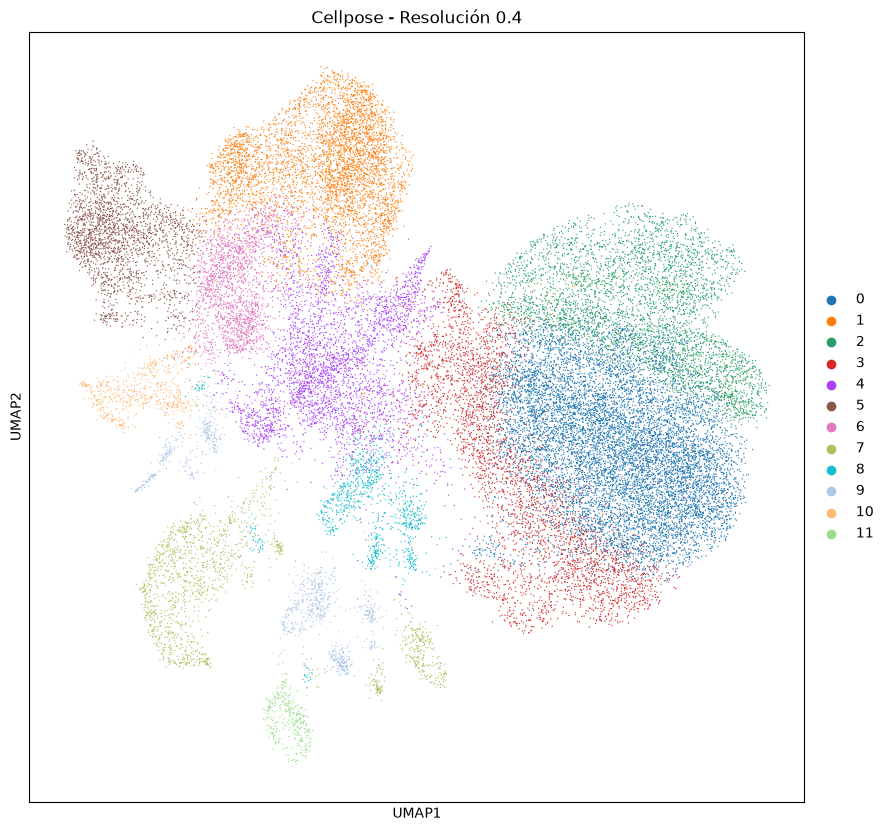

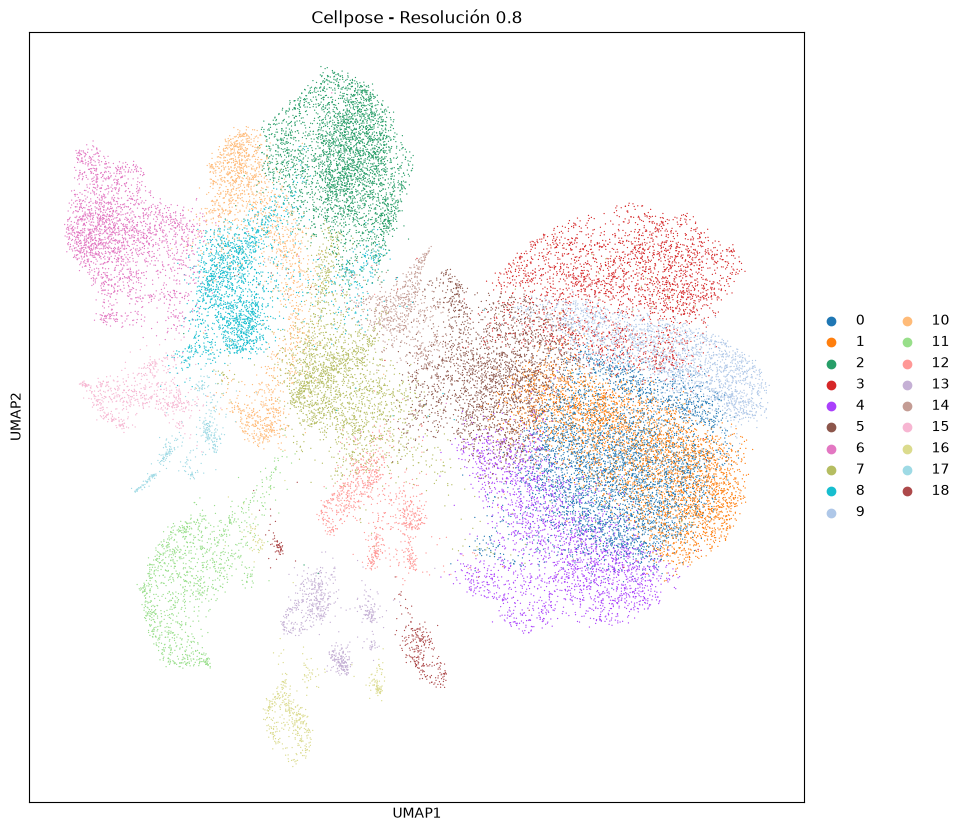

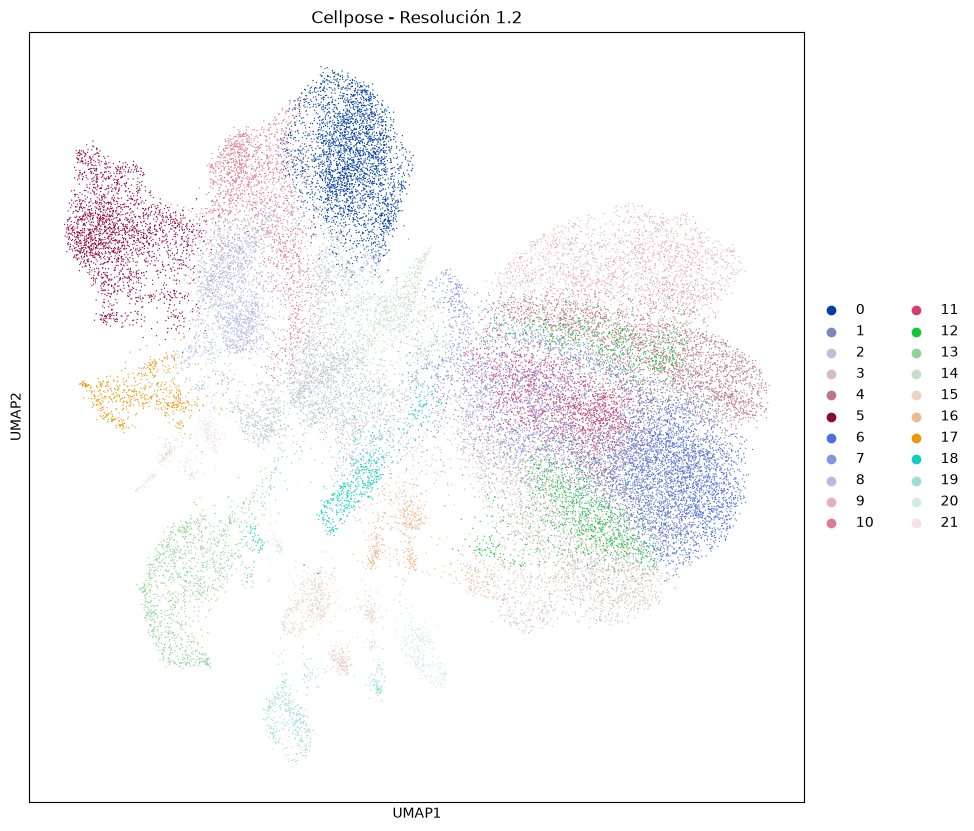

Calculando PCA, KNN y clústeres para Baysor (sin prior)...


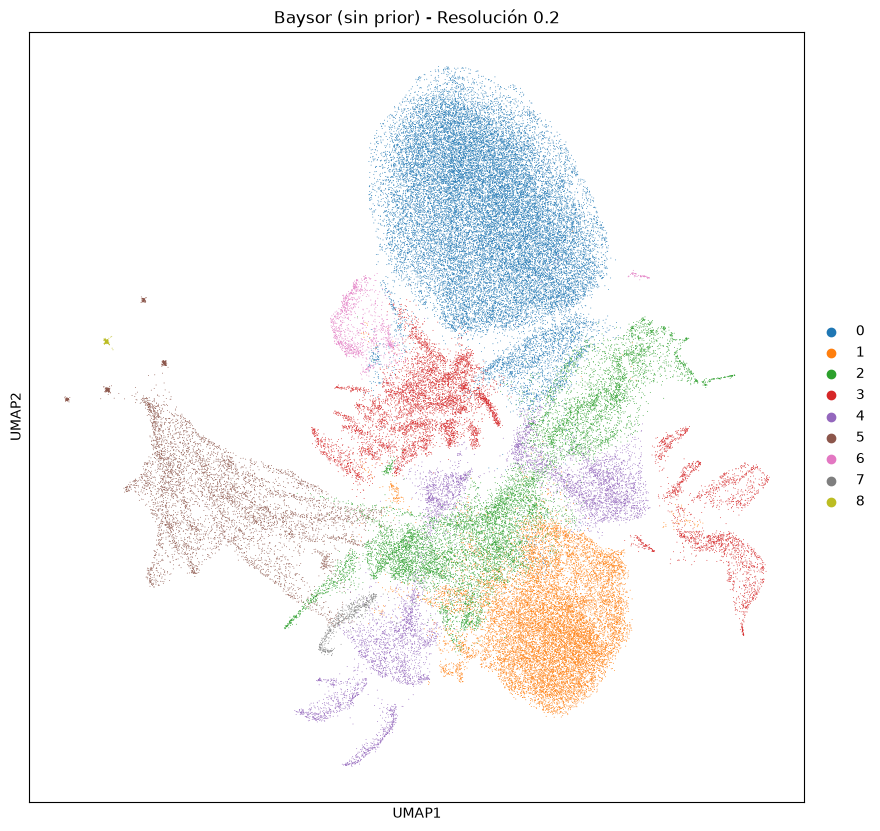

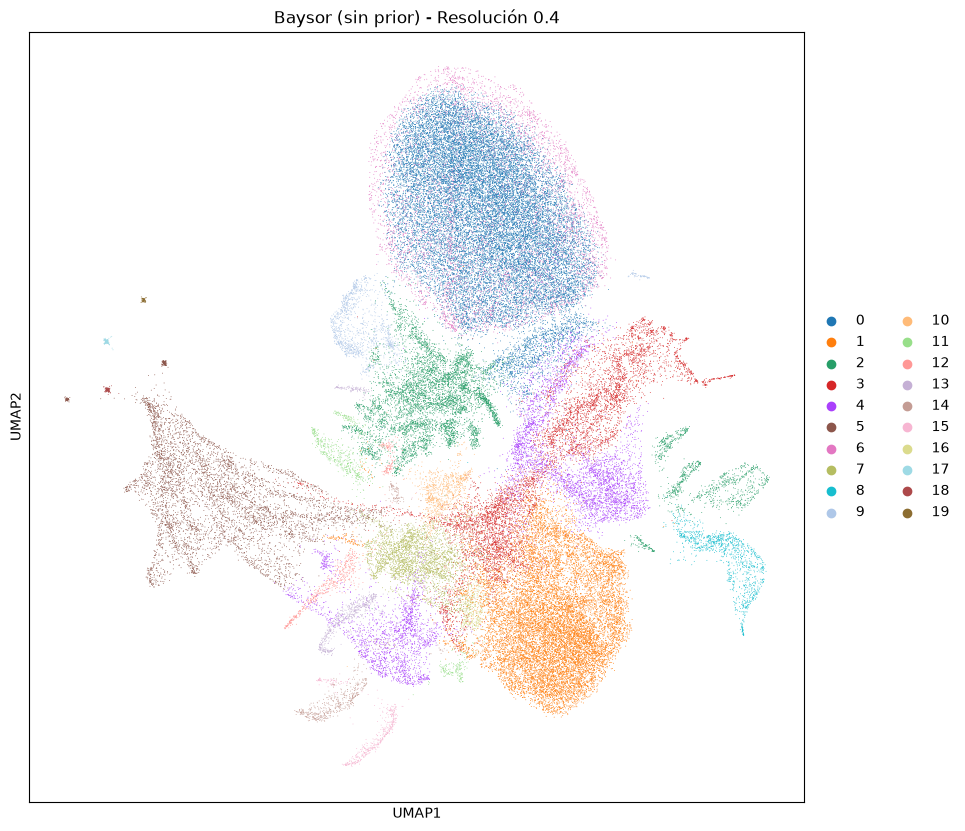

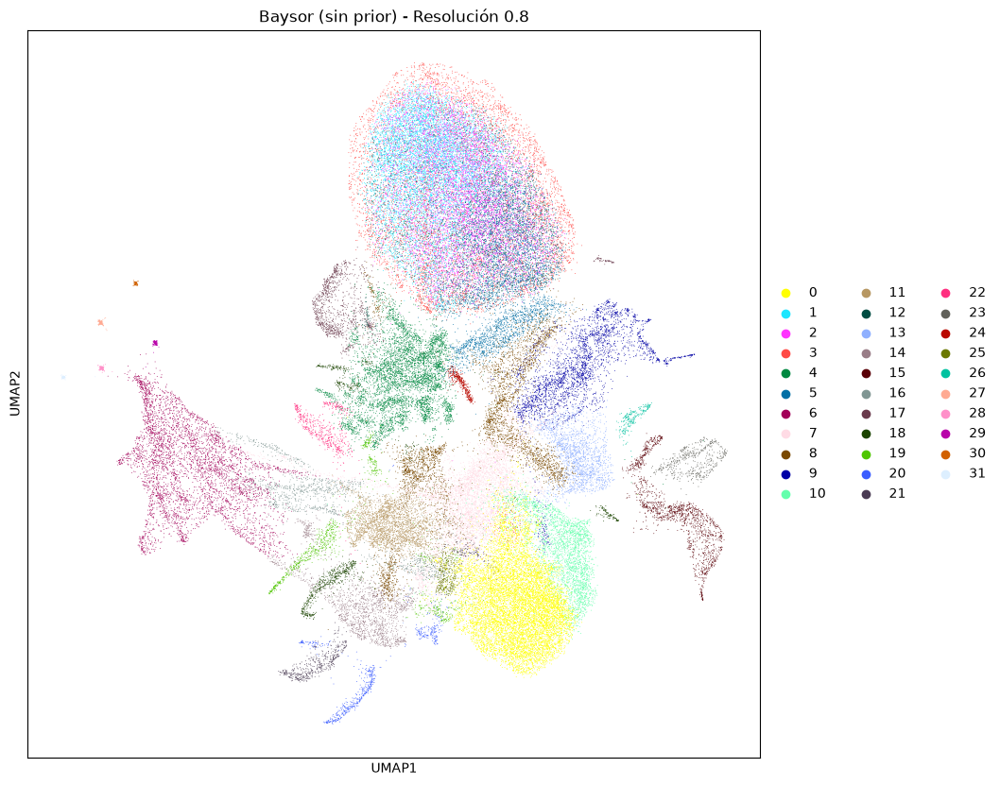

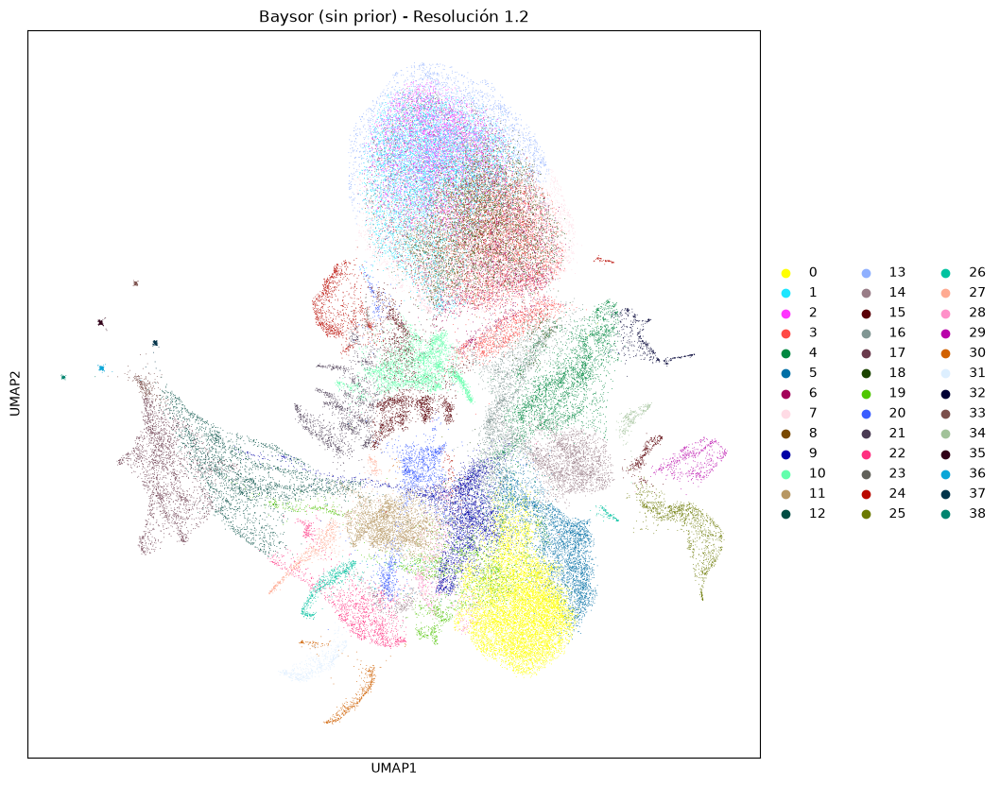

Calculando PCA, KNN y clústeres para Baysor (prior nuclear)...


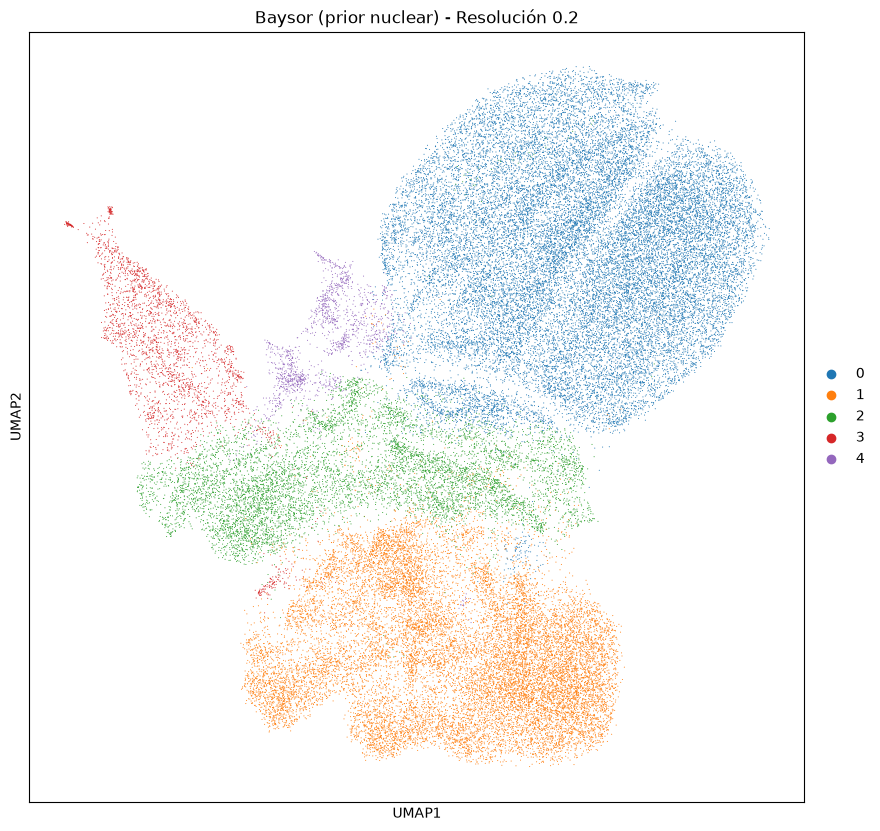

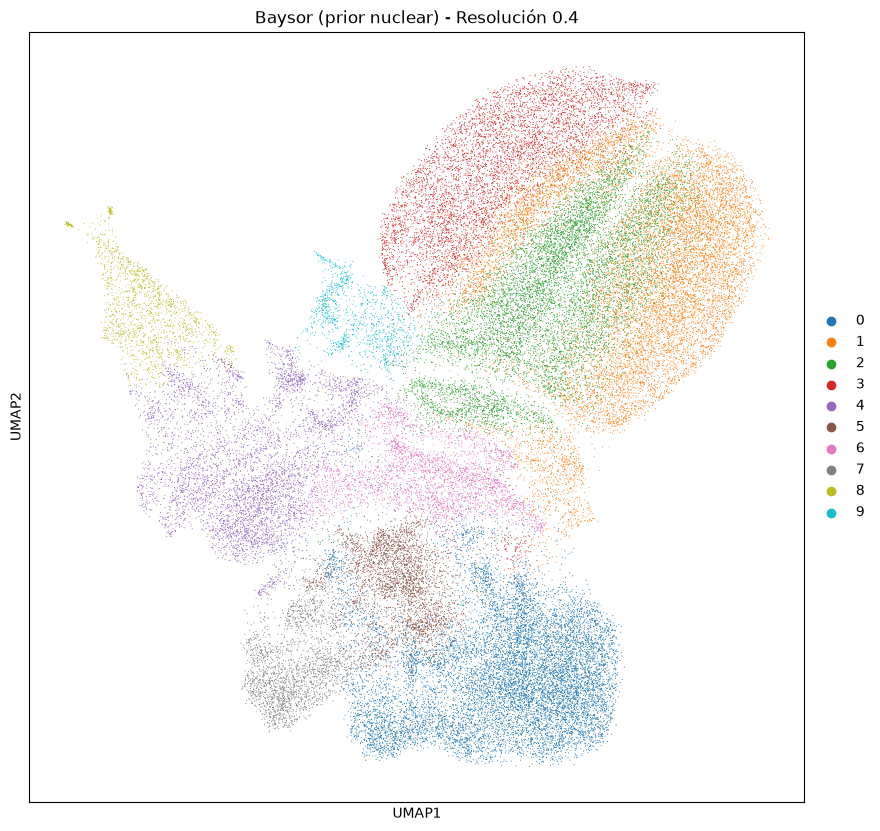

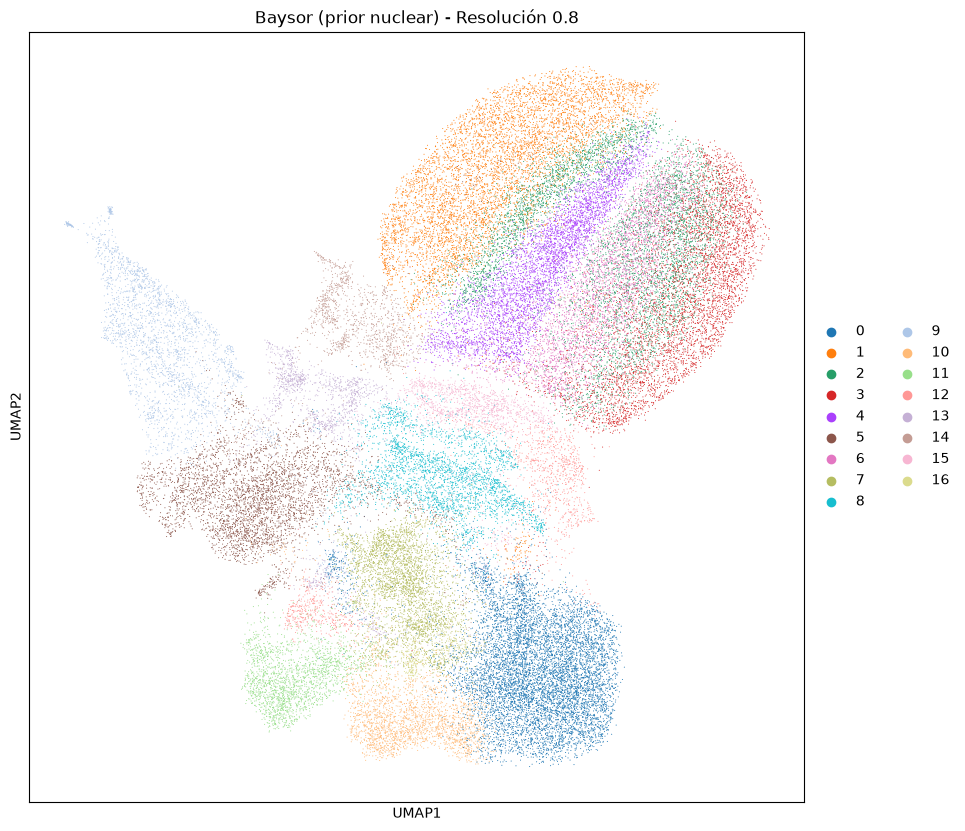

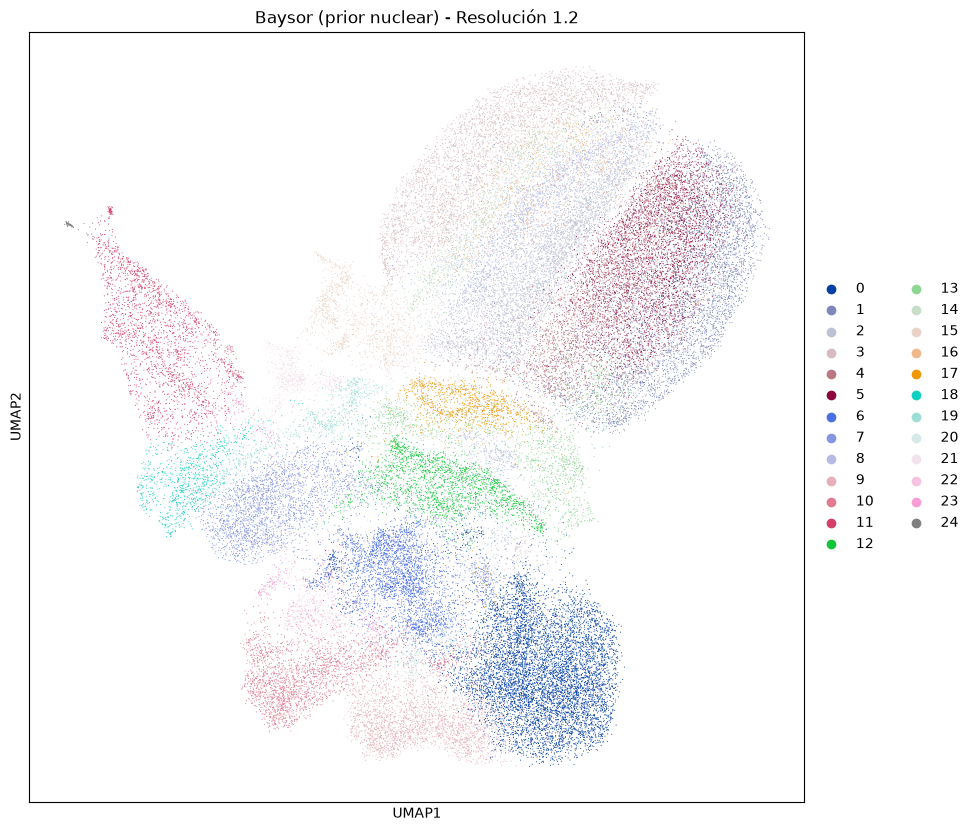

Calculando PCA, KNN y clústeres para Baysor (prior celular)...


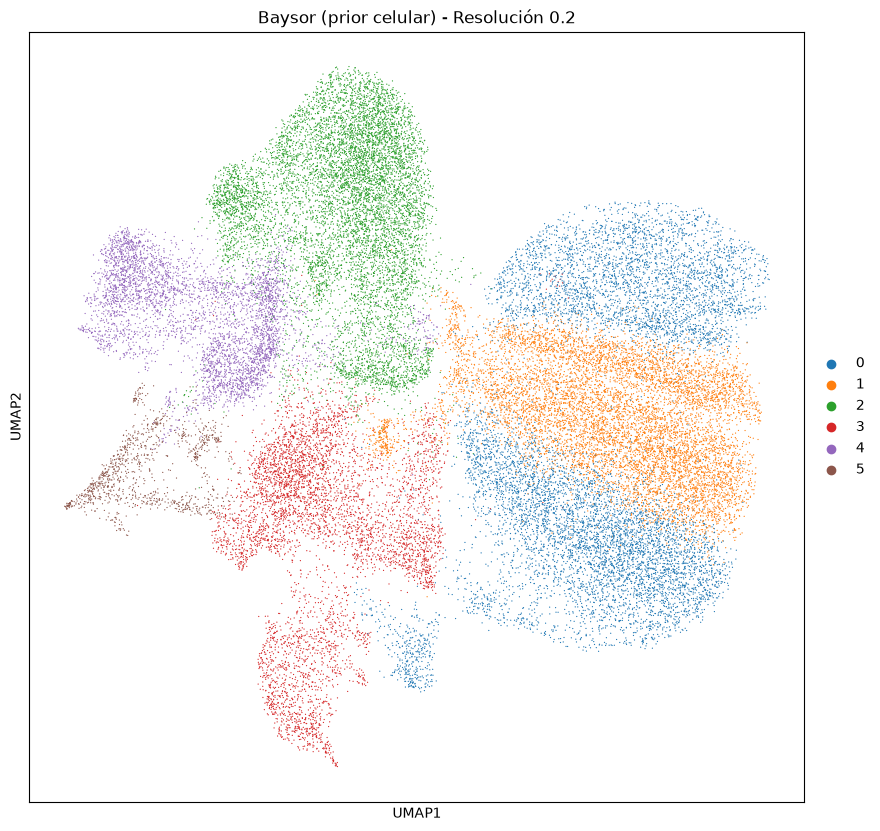

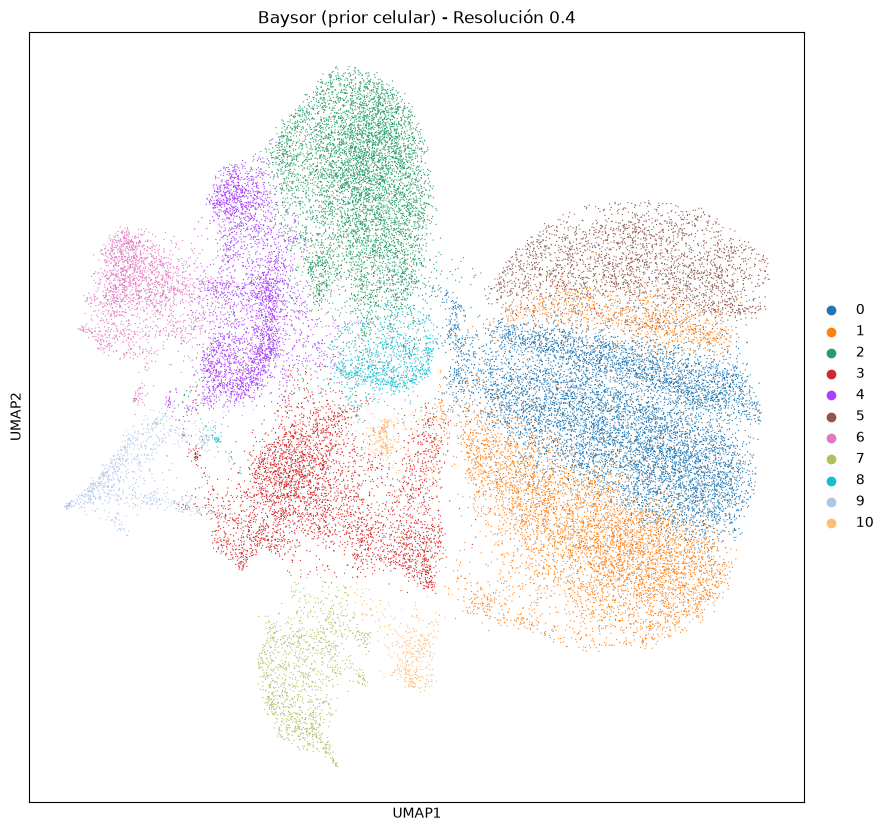

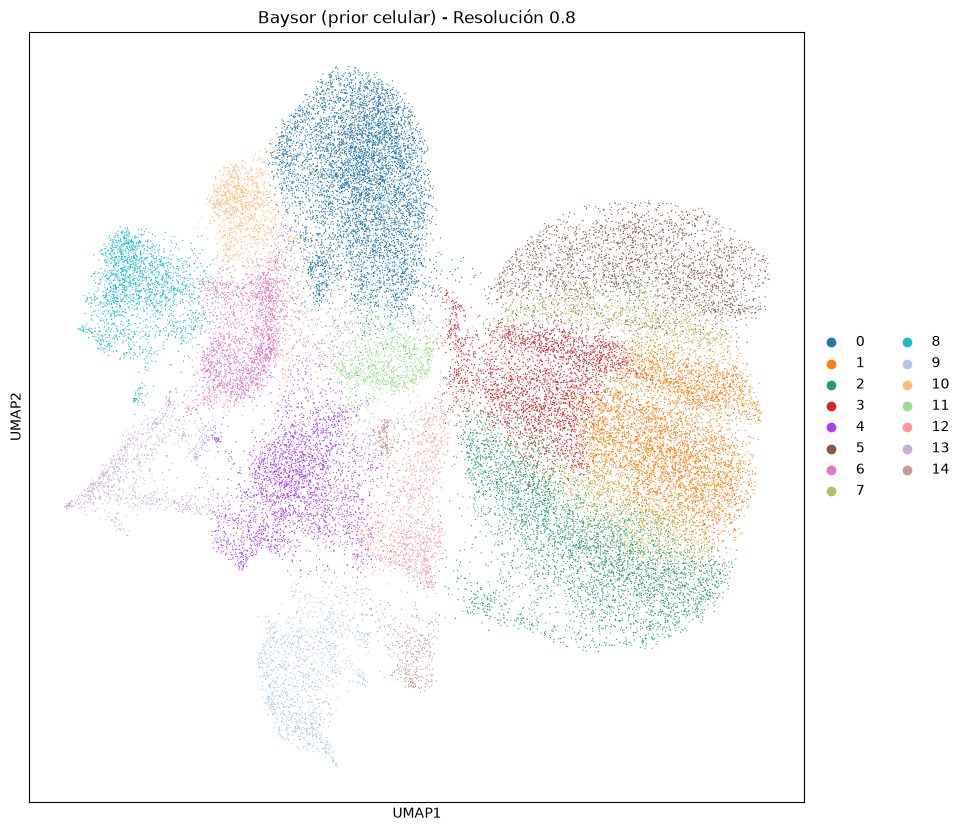

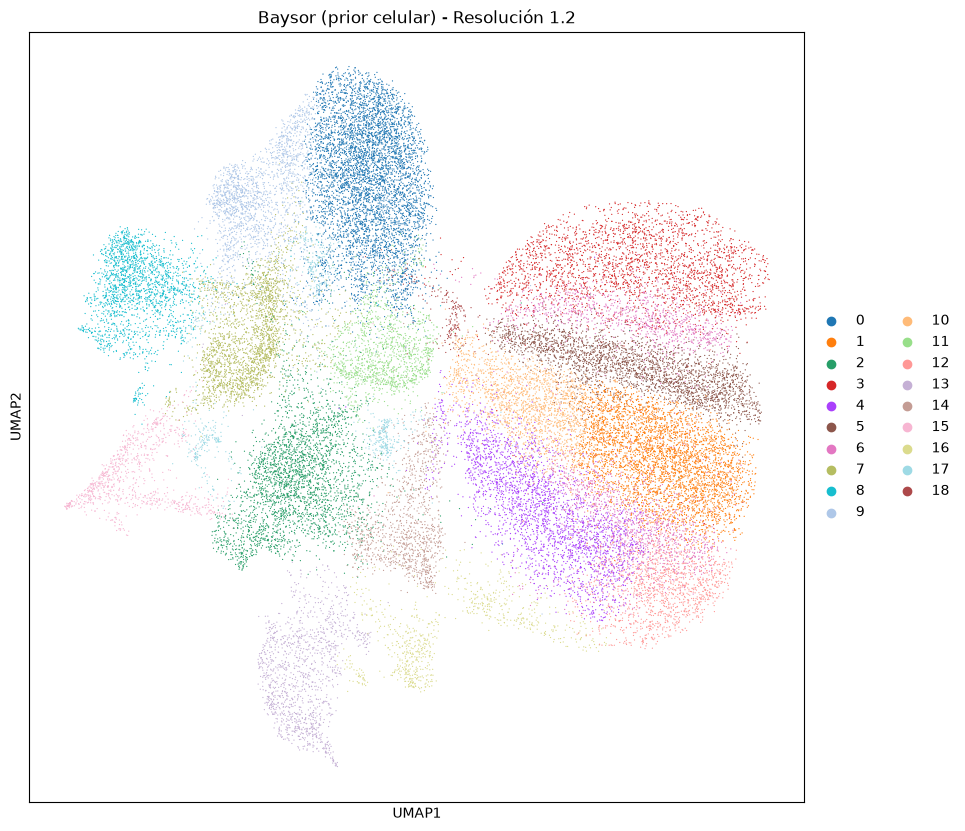

In [6]:
r_state = 23 # Fijamos la semilla aleatoria para que los resultados sean reproducibles.

# La resolución del gráfico de Leiden es un parámetro que controla el tamaño de los clústeres detectados.
# Valores más bajos producen un menor número de clústeres, más grandes, mientras que valores
# más altos producen un mayor número de clústeres, más pequeños. Definimos tres resoluciones diferentes
# para explorar cómo afecta a la agrupación de las células.
res_dict = {
    "leiden_res0_2": 0.2,
    "leiden_res0_4": 0.4,
    "leiden_res0_8": 0.8,
    "leiden_res1_2": 1.2
    }

# Creamos un diccionario para iterar sobre las tablas de cada método de segmentación:
adata_dict = {
    "Xenium": sdata_normalized.tables["table_xenium_default"],
    "Expansión nuclear": sdata_normalized.tables["table_nucleus_expanded"],
    "Cellpose": sdata_normalized.tables["table_cellpose"],
    "Baysor (sin prior)": sdata_normalized.tables["table_baysor_no_prior"],
    "Baysor (prior nuclear)": sdata_normalized.tables["table_baysor_nuclear_mask_prior"],
    "Baysor (prior celular)": sdata_normalized.tables["table_baysor_cellpose_cito_prior"]
}

for method_name, adata in adata_dict.items():
    print(f"Calculando PCA, KNN y clústeres para {method_name}...")

    # Rehacemos el PCA con 20 componentes principales.
    sc.tl.pca(adata, n_comps=20)

    # Calculamos los grafos de vecindad (K-Nearest Neighbors). Definimos un valor de 35 vecinos para cada célula,
    # ya que es un valor intermedio que permite capturar la estructura local de los datos sin ser demasiado sensible al ruido,
    # previo a la generación del gráfico de UMAP y la agrupación de células en clústeres mediante el algoritmo de Leiden.
    sc.pp.neighbors(adata, n_neighbors=35, n_pcs=20, random_state=r_state)

    # UMAP
    sc.tl.umap(adata, random_state=r_state)

    # Clustering (gráfico de Leiden). Iteramos para realizar un gráfico de Leiden para cada resolución definida en res_dict:
    for key, resolution in res_dict.items():
        # Realizamos el clustering.
        # key_added define el nombre de la columna que se añadirá a adata.obs con los resultados del clustering.
        sc.tl.leiden(adata, resolution=resolution, random_state=r_state, key_added=key)
        
        # Preparamos el título del gráfico de Leiden:
        plot_title = f"{method_name} - Resolución {resolution}"

        # Ploteamos el gráfico de Leiden y lo guardamos en un archivo .tiff
        fig, ax = plt.subplots(figsize=(10, 10))
        sc.pl.umap(adata, color=key, ax=ax, title=plot_title, show=False)
        filename = method_name.lower().replace(" ", "_").replace("(", "").replace(")", "") # Adecuamos para nombrar archivos
        fig.savefig(GRAPHS_CLUSTERING_DIR / f"{filename}_{key}.tiff", dpi=300, bbox_inches='tight')
        plt.show()
        plt.close(fig)

Generando panel comparativo para resolución 0.2...


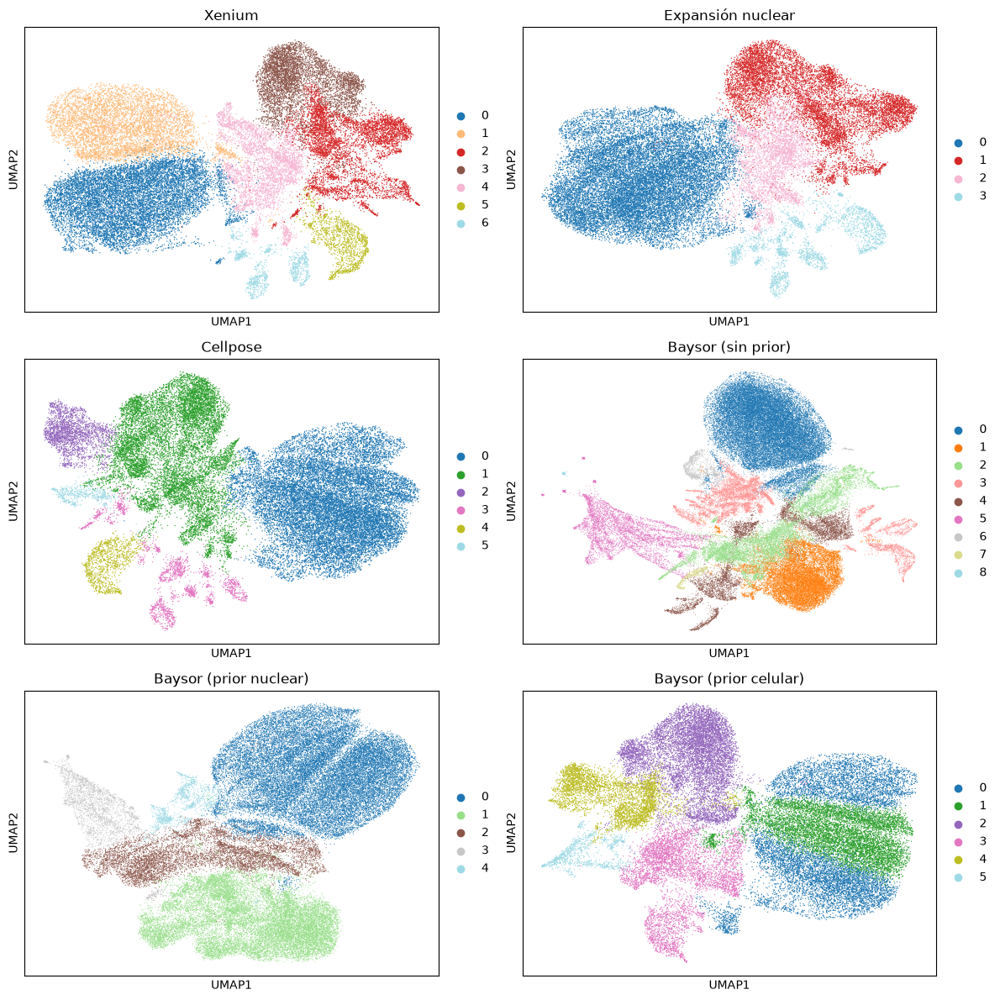

Generando panel comparativo para resolución 0.4...


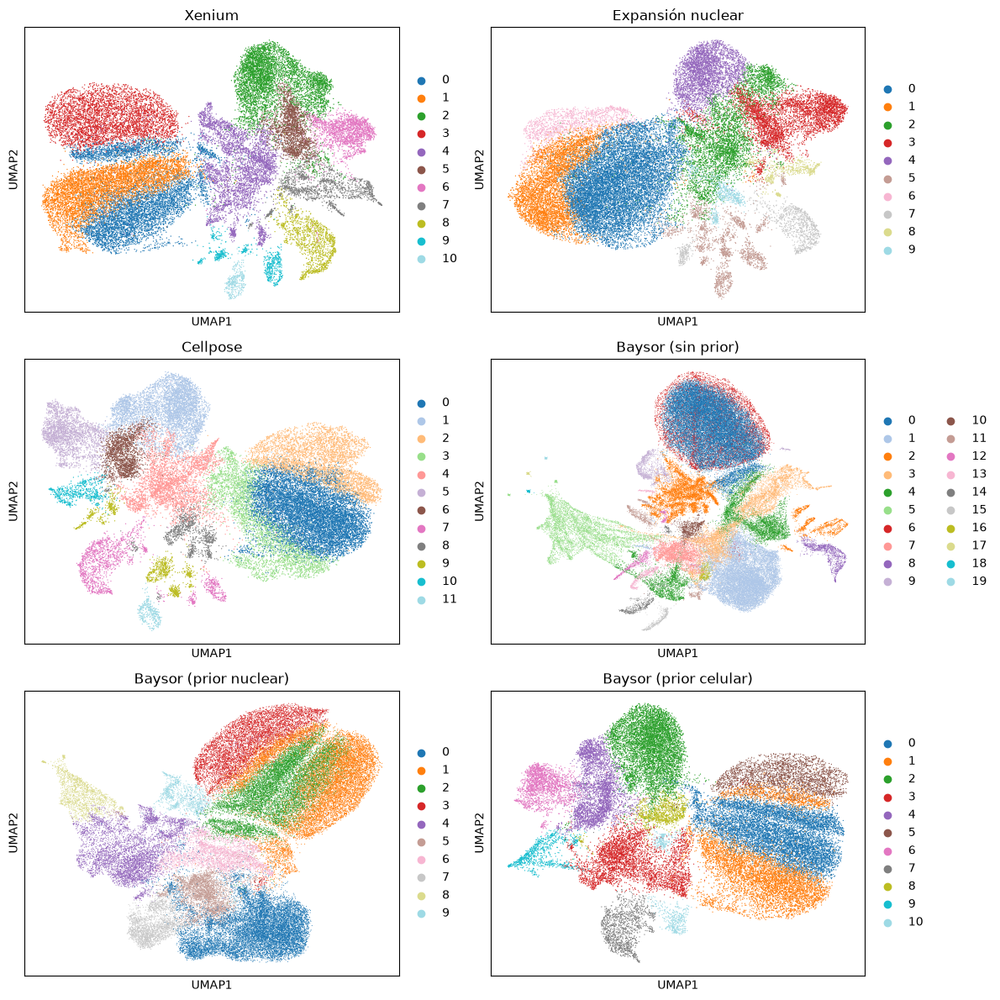

Generando panel comparativo para resolución 0.8...


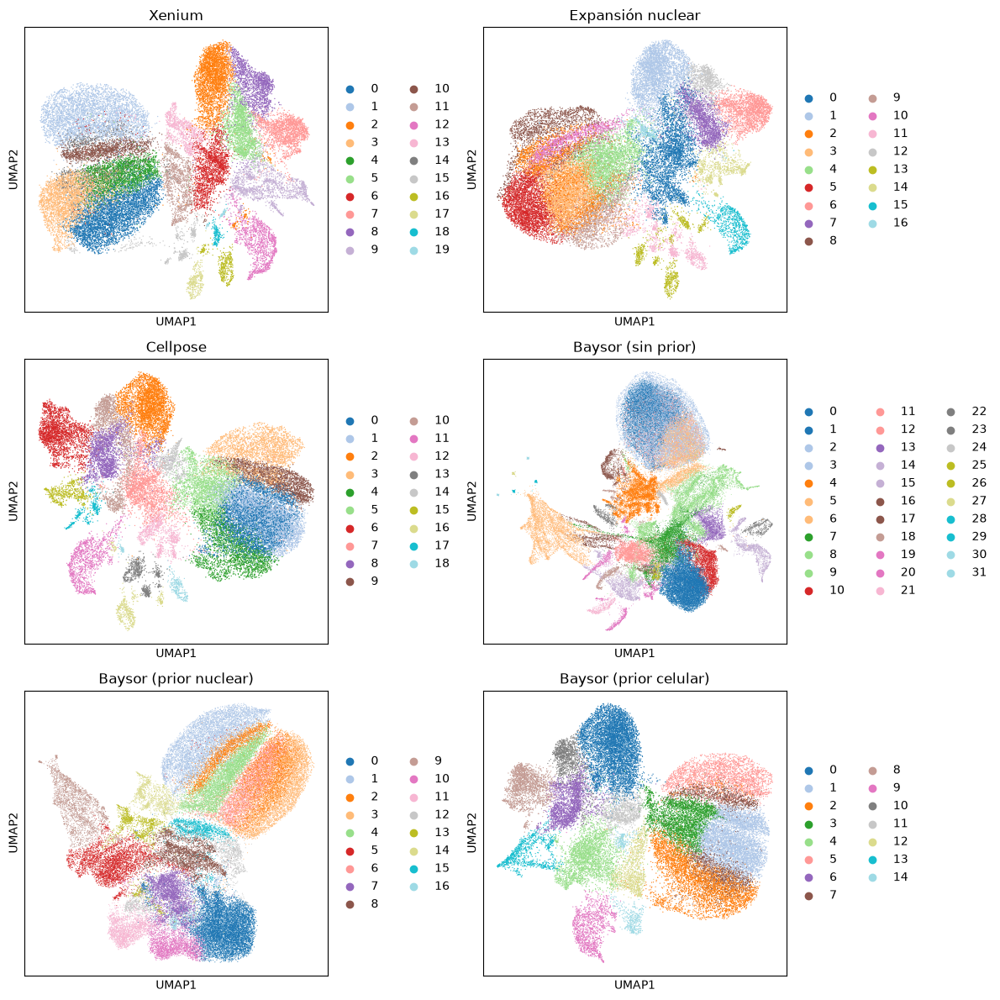

Generando panel comparativo para resolución 1.2...


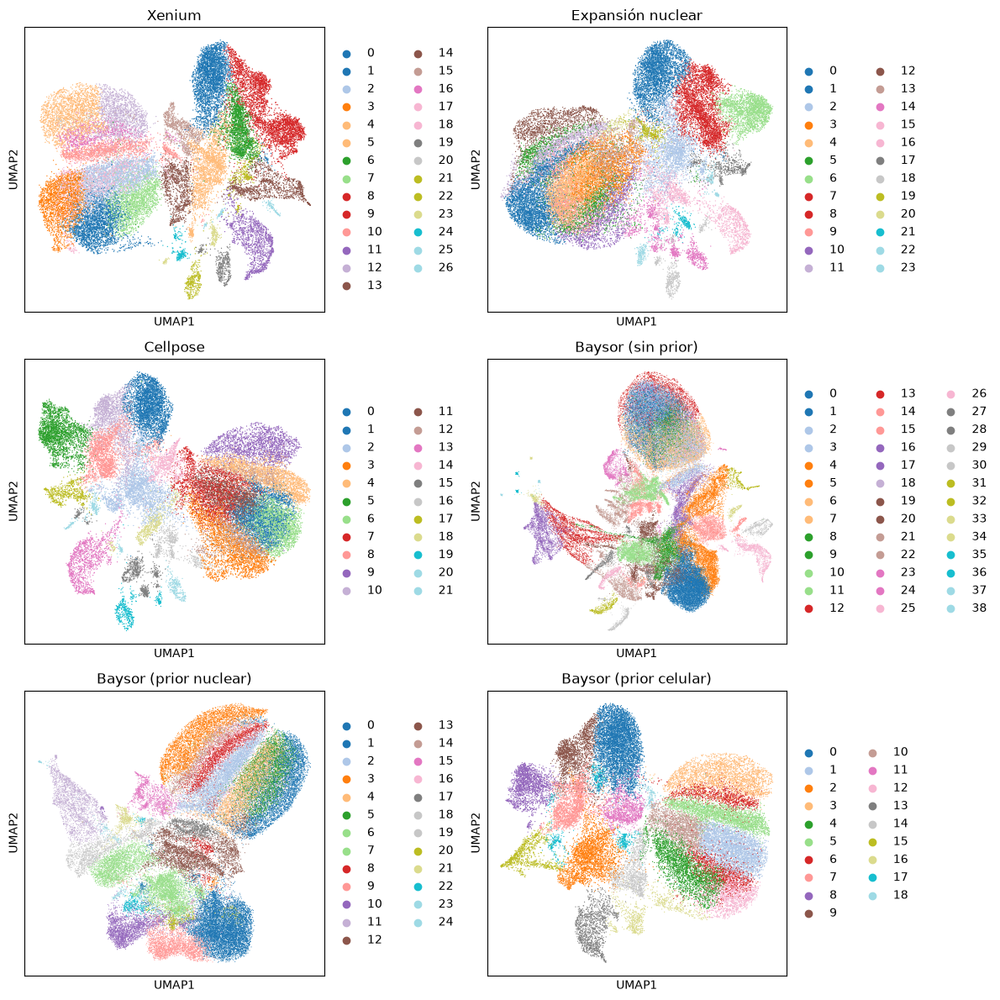

In [10]:
# Generamos una gráfica comparativa de los gráficos de Leiden para cada resolución para facilitar la comparación visual.
for key, resolution in res_dict.items():
    print(f"Generando panel comparativo para resolución {resolution}...")
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 12))
    axes = axes.flatten() # Aplanamos el array de ejes para iterar fácilmente

    # Iteramos sobre el diccionario adata_dict creado anteriormente (y usamos enumerate para
    # obtener un índice que nos permita colocar cada gráfico en la posición correcta de la cuadrícula):
    for i, (method_name, adata) in enumerate(adata_dict.items()):
        # Generar gráfica de UMAP coloreando por los clústeres recién calculados
        sc.pl.umap(
            adata, 
            color=key, 
            ax=axes[i], 
            show=False, 
            title=method_name,
            palette="tab20"
        )

    # Ajustamos los márgenes y mostramos el panel final
    plt.tight_layout()
    fig.savefig(GRAPHS_CLUSTERING_DIR / f"{key}_comparison.tiff", dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

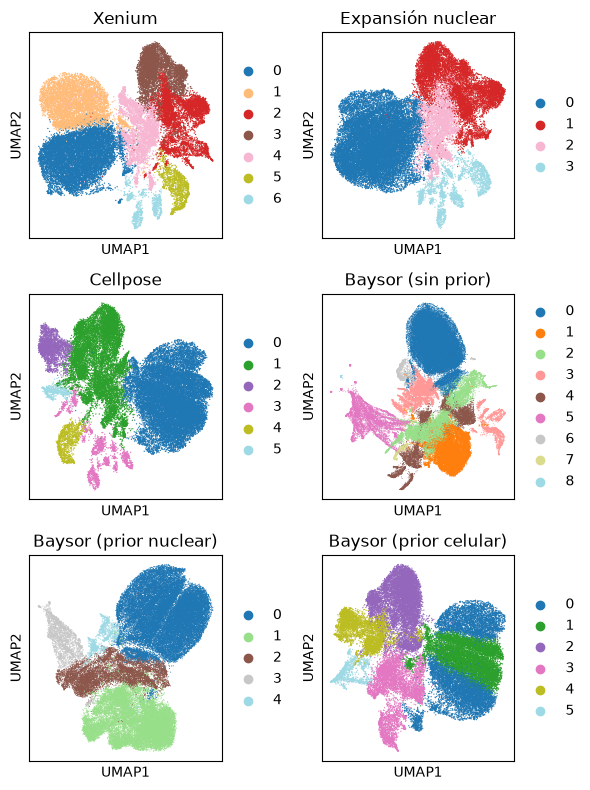

In [11]:
# Gráfica de tamaño reducido para el manuscrito para la resolución 0.2:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(6, 8))
axes = axes.flatten() # Aplanamos el array de ejes para iterar fácilmente

# Iteramos sobre el diccionario adata_dict creado anteriormente (y usamos enumerate para
# obtener un índice que nos permita colocar cada gráfico en la posición correcta de la cuadrícula):
for i, (method_name, adata) in enumerate(adata_dict.items()):
    # Generar gráfica de UMAP coloreando por los clústeres recién calculados
    sc.pl.umap(
        adata, 
        color="leiden_res0_2", 
        ax=axes[i], 
        show=False, 
        title=method_name,
        palette="tab20"
    )

# Ajustamos los márgenes y mostramos el panel final
plt.tight_layout()
fig.savefig(GRAPHS_CLUSTERING_DIR / "leiden_res0_2_comparison_manuscript_ver.tiff", dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

Las resoluciones más altas parecen fragmentar los clústeres grandes en otros más pequeños que, en la mayoría de los casos no se encuentran claramente separados entre ellos,o incluso se mezclan entre sí. En [Rose y cols. (2026)](https://doi.org/10.64898/2026.04.16.718947) analizan también el *Silhouette Coefficient*, como medida de la similitud de la célula con su clúster y su diferencia con los otros clústeres. Medir este parámetro a nivel global nos permite comprobar cómo de bien han sido asignadas las células a distintos clústeres según el algoritmo empleado. Para medir de manera cuantitativa las diferencias en el *clustering* entre los distintos métodos de segmentación y resoluciones, podemos calcular este parámetro, usando la función `silhouette_samples` del módulo `sklearn`. El coeficiente generado varía entre -1 (la célula ha sido incorrectamente asignada al clúster) y +1 (la célula pertenece claramente al clúster al que ha sido asignada y se diferencia bien de los demás clústeres). Valores cercanos a 0 indican que los clústeres se están solapando.

Si medimos la distribución del coeficiente (*Silhouette Width*) para cada método de segmentación, podemos hacernos una idea de si ese método produce por lo general clústeres bien diferenciados unos de otros (la distribución tiende a +1) o los clústeres están mal asignados o se combinan entre ellos (la distribución tiende a -1).


--- Procesando resolución 0.2 (leiden_res0_2) ---
Calculando siluetas para Xenium...
Calculando siluetas para Expansión nuclear...
Calculando siluetas para Cellpose...
Calculando siluetas para Baysor (sin prior)...
Calculando siluetas para Baysor (prior nuclear)...
Calculando siluetas para Baysor (prior celular)...


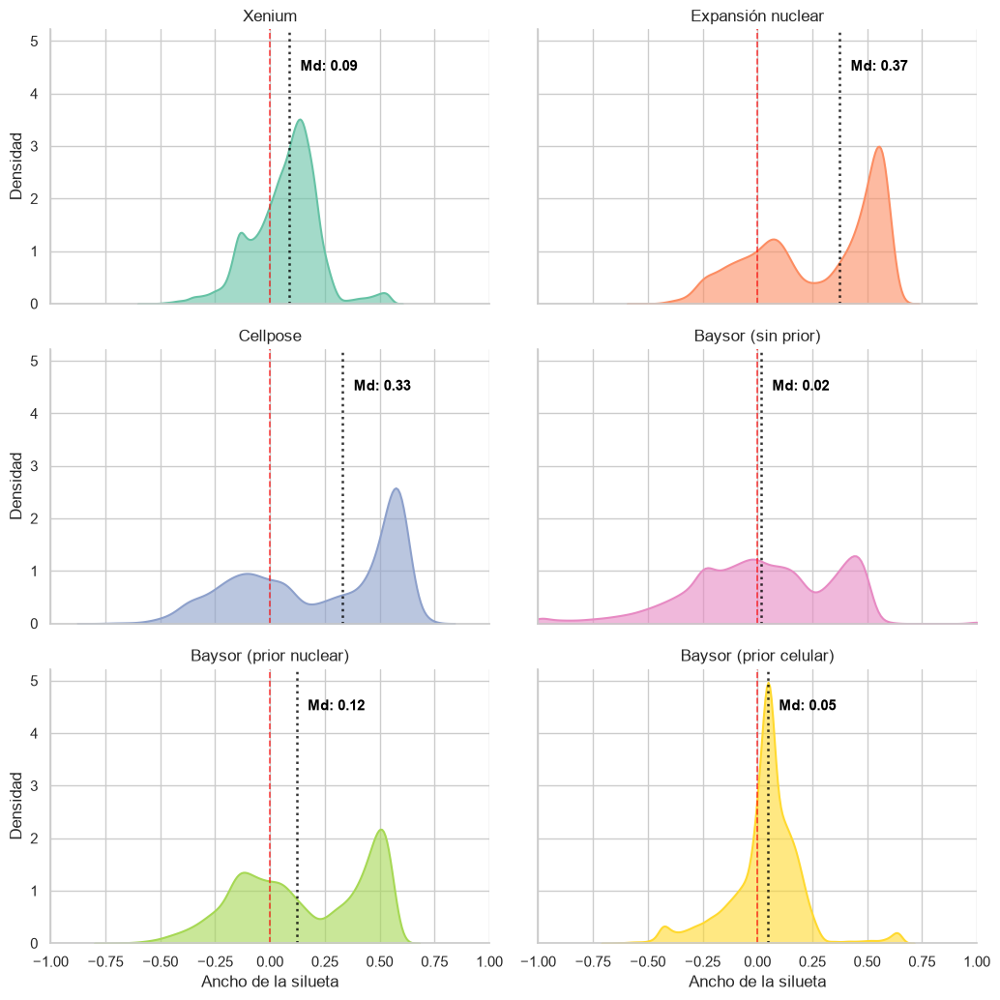


--- Procesando resolución 0.4 (leiden_res0_4) ---
Calculando siluetas para Xenium...
Calculando siluetas para Expansión nuclear...
Calculando siluetas para Cellpose...
Calculando siluetas para Baysor (sin prior)...
Calculando siluetas para Baysor (prior nuclear)...
Calculando siluetas para Baysor (prior celular)...


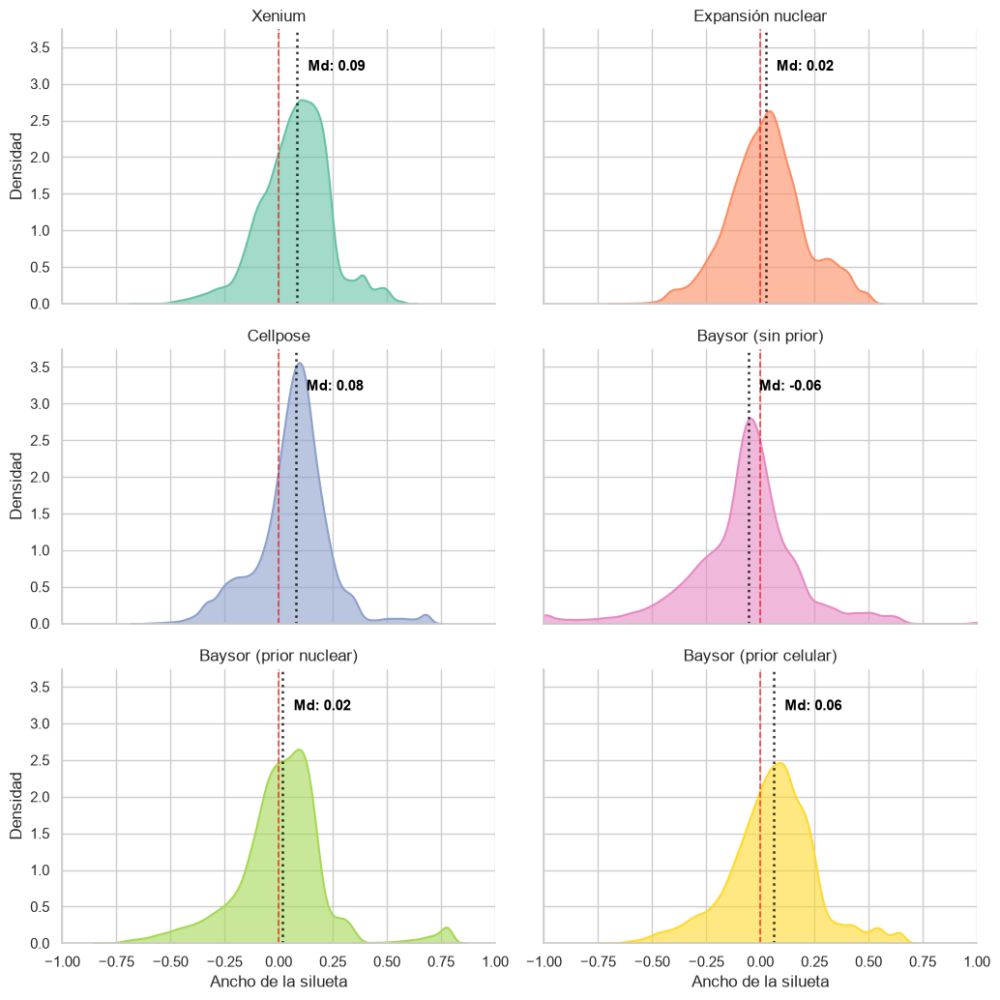


--- Procesando resolución 0.8 (leiden_res0_8) ---
Calculando siluetas para Xenium...
Calculando siluetas para Expansión nuclear...
Calculando siluetas para Cellpose...
Calculando siluetas para Baysor (sin prior)...
Calculando siluetas para Baysor (prior nuclear)...
Calculando siluetas para Baysor (prior celular)...


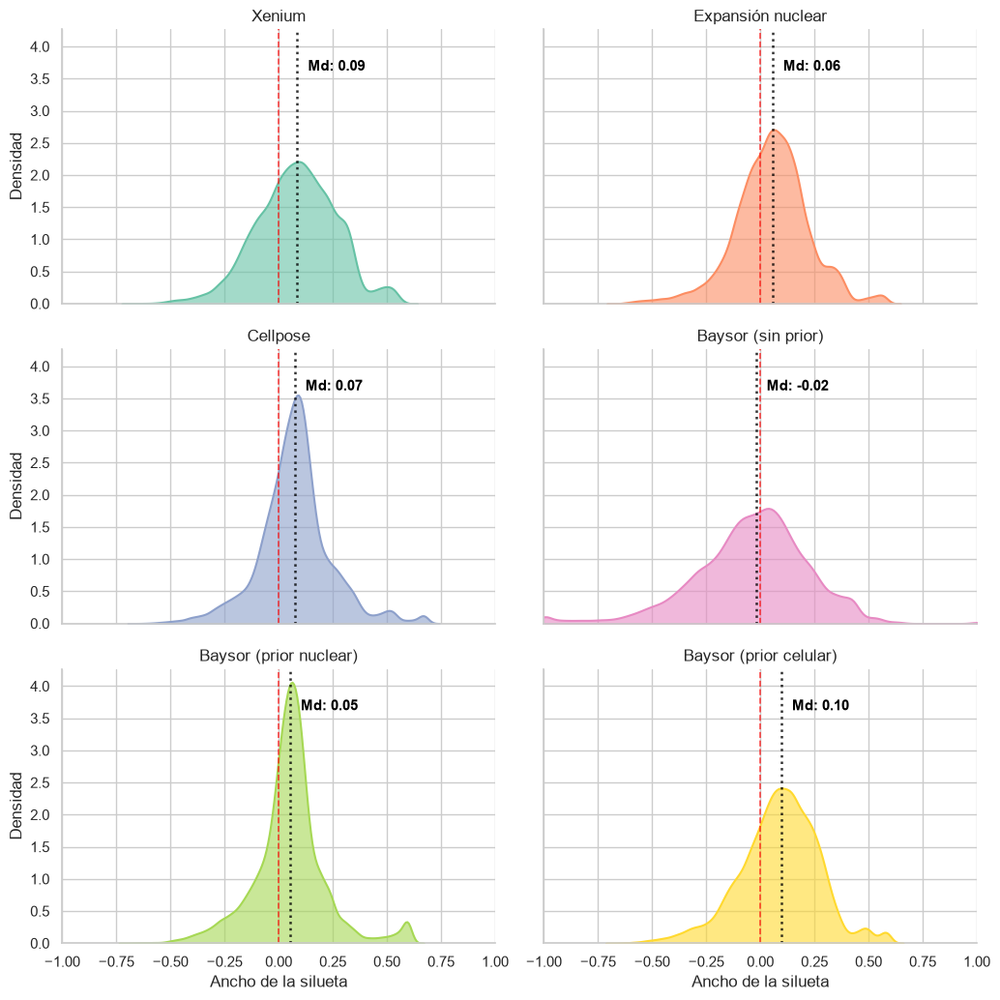


--- Procesando resolución 1.2 (leiden_res1_2) ---
Calculando siluetas para Xenium...
Calculando siluetas para Expansión nuclear...
Calculando siluetas para Cellpose...
Calculando siluetas para Baysor (sin prior)...
Calculando siluetas para Baysor (prior nuclear)...
Calculando siluetas para Baysor (prior celular)...


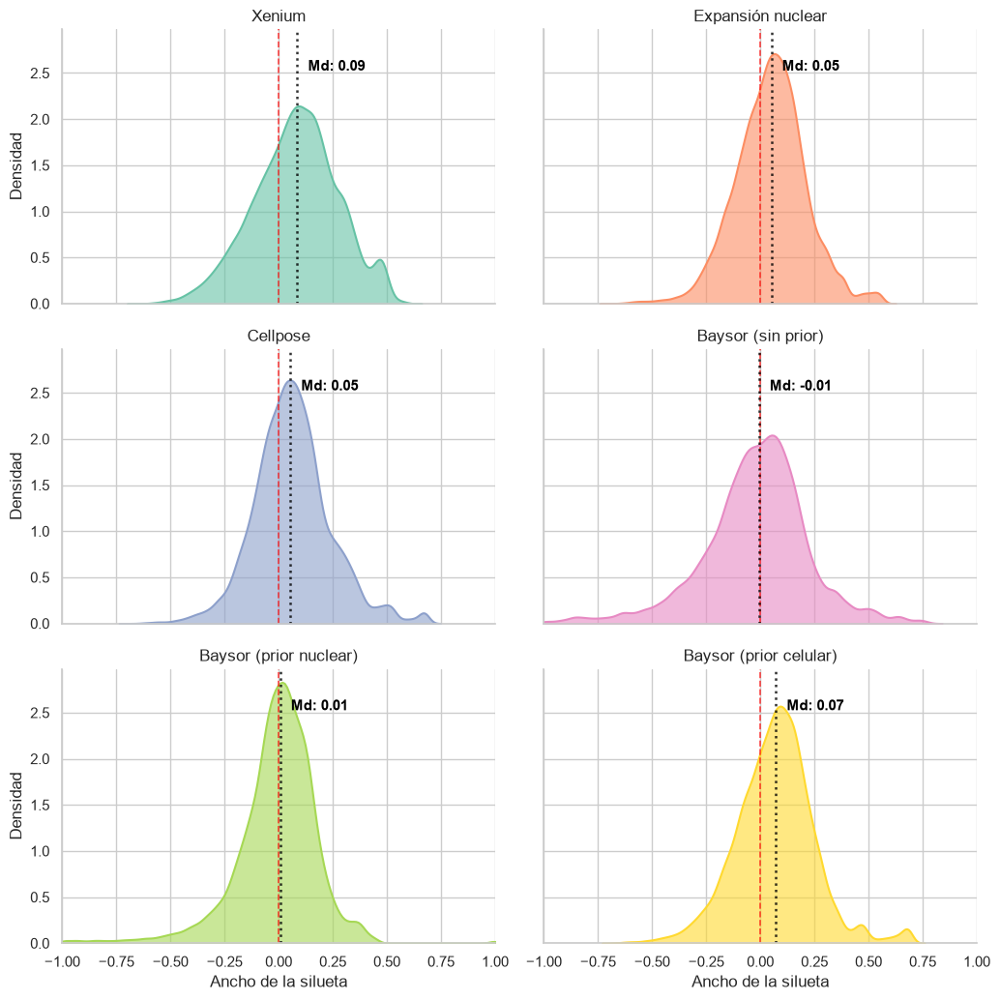

In [ ]:
# Definimos el tema de los gráficos y la paleta de colores:
sns.set_theme(style="whitegrid")
palette = sns.color_palette("Set2", n_colors=6)

# Iteramos sobre el diccionario de resoluciones creado anteriormente, que contiene
# los nombres de las columnas de clústeres:
for cluster_key, resolution in res_dict.items():
    print(f"\n--- Procesando resolución {resolution} ({cluster_key}) ---")
    
    # Creamos una lista vacía para almacenar los DataFrames de cada método:
    df_list = []

    # Iteramos sobre el diccionario de métodos de segmentación:
    for method_name, adata in adata_dict.items():
        print(f"Calculando Silhouette Width para {method_name}...")
        # Tenemos que aportar a la función silhouette_samples() la posición de las células en el espacio de componentes principales (X_pca)
        # y las etiquetas que indican a qué clúster pertenece cada célula (labels).
        X_pca = adata.obsm["X_pca"]
        labels = adata.obs[cluster_key]

        # Calculamos los valores de silueta para cada célula:
        sil_widths = silhouette_samples(X_pca, labels)
        
        # Guardamos el valor individual en los metadatos de la célula, usando
        # una columna distinta para cada resolución:
        adata.obs[f"silhouette_width_{cluster_key}"] = sil_widths

        # Creamos un DataFrame temporal para almacenar los resultados de cada método:
        temp_df = pd.DataFrame({
            "Silhouette Width": sil_widths,
            "Method": method_name
        })

        # Añadimos el DataFrame temporal a la lista de DataFrames:
        df_list.append(temp_df)

    # Tras iterar sobre todos los métodos, concatenamos los DataFrames de la lista en un único DataFrame en formato largo,
    # que contiene en una columna los valores de silueta de cada célula y en otra columna el nombre del método correspondiente:
    df_silhouette = pd.concat(df_list, ignore_index=True)

    # Procedemos a realizar el gráfico de densidad de los valores de silueta para cada método,
    # usando FacetGrid de Seaborn, que nos permite crear un gráfico de densidad para cada método en un panel separado.
    g = sns.FacetGrid(
        df_silhouette, 
        col="Method", # Cada gráfico corresponde a un método de segmentación.
        col_wrap=2, # Dos columnas por fila.
        col_order=list(adata_dict.keys()), # Ordenamos los gráficos siguiendo el mismo orden de siempre.
        hue="Method", # Un color distinto para cada método.
        palette=palette,
        sharex=True, # Compartimos el eje x entre todos los paneles.
        sharey=True, # Lo mismo para el eje y.
        height=3.5, # Altura de cada panel.
        aspect=1.5 # Relación de aspecto de cada panel.
    )

    # Añadimos el gráfico de densidad a cada panel, con relleno y transparencia:
    g.map(sns.kdeplot, "Silhouette Width", fill=True, common_norm=False, alpha=0.6, linewidth=1.5)
    g.set_titles(col_template="{col_name}")
    g.set_axis_labels("Silhouette Width", "Densidad")

    # Añadimos líneas verticales para indicar la mediana de cada distribución y el valor 0, que es el límite entre clústeres bien definidos y mal definidos.
    for ax, method_name in zip(g.axes.flat, list(adata_dict.keys())):
        ax.axvline(x=0, color="red", linestyle="--", linewidth=1.2, alpha=0.7)

        # Calculamos la mediana de los valores y dibujamos una línea vertical que pase por ella:
        median_val = df_silhouette[df_silhouette["Method"] == method_name]["Silhouette Width"].median()
        ax.axvline(x=median_val, color="black", linestyle=":", linewidth=1.8, alpha=0.8)

        # Dibujamos un texto que indique el valor de la mediana:
        y_max = ax.get_ylim()[1]
        ax.text(median_val + 0.05, y_max * 0.85, f"Md: {median_val:.2f}", color="black", fontsize=11, fontweight="bold")
        ax.set_xlim(-1, 1)

    plt.tight_layout()
    output_file = GRAPHS_CLUSTERING_DIR / f"silhouette_density_medians_{cluster_key}.tiff"
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()



Procedemos a calcular diferencias estadísticas en el proceso de *clustering* de los distintos métodos de segmentación.

In [14]:
# Número de clusters

# Creamos un DataFrame vacío para almacenar las estadísticas de clustering:
df_clustering_stats = pd.DataFrame(index=adata_dict.keys())

# Creamos un diccionario para mapear los nombres de las resoluciones a descripciones que usaremos en la tabla:
res_descript_dict = {
    "leiden_res0_2": "Resolución 0.2",
    "leiden_res0_4": "Resolución 0.4",
    "leiden_res0_8": "Resolución 0.8",
    "leiden_res1_2": "Resolución 1.2"
}

# Iteramos sobre el diccionario de resoluciones:
for res, description in res_descript_dict.items():
    # Creamos una lista vacía para almacenar el número de clústeres detectados por cada método:
    n_clusters_list = []

    # Contamos el número de clústeres generados por cada método en la resolución actual y lo añadimos a la lista:
    for method_name, adata in adata_dict.items():
        n_clusters = adata.obs[res].nunique()
        n_clusters_list.append(n_clusters)
    
    # Guardamos la lista de resultados en el Dataframe global:
    df_clustering_stats[f"Nº de clusters ({description})"] = n_clusters_list

# Comprobamos la tabla global:
df_clustering_stats

,Nº de clusters (Resolución 0.2),Nº de clusters (Resolución 0.4),Nº de clusters (Resolución 0.8),Nº de clusters (Resolución 1.2)
Xenium,7,11,20,27
Expansión nuclear,4,10,17,24
Cellpose,6,12,19,22
Baysor (sin prior),9,20,32,39
Baysor (prior nuclear),5,10,17,25
Baysor (prior celular),6,11,15,19


In [15]:
# Test de normalidad de la distribución de siluetas para cada resolución de Leiden

# Creamos una lista con cada columna a testear:
sil_width_list = ["silhouette_width_leiden_res0_2", "silhouette_width_leiden_res0_4", "silhouette_width_leiden_res0_8", "silhouette_width_leiden_res1_2"]

# Creamos un diccionario para almacenar los resultados de los tests de normalidad de cada resolución:
normaltest_results_clustering_dict = {}

# Realizamos el test usando la función anndata_normaltest() que hemos definido previamente:
for item in sil_width_list:
    normaltest_results_clustering_dict[item] = anndata_normaltest(adata_dict, item, TABLES_CLUSTERING_DIR)

Resultados del test de normalidad para "silhouette_width_leiden_res0_2"
                        Score del test  p-valor Sigue una distribución normal
Método de segmentación                                                       
Xenium                      856.730835      0.0                            NO
Expansión nuclear         33180.500000      0.0                            NO
Cellpose                  52637.902344      0.0                            NO
Baysor (sin prior)         2138.061768      0.0                            NO
Baysor (prior nuclear)    46071.808594      0.0                            NO
Baysor (prior celular)     2767.122314      0.0                            NO
Resultados guardados en "results/statistics/clustering/tables/silhouette_width_leiden_res0_2_normaltest.csv"
Resultados del test de normalidad para "silhouette_width_leiden_res0_4"
                        Score del test       p-valor  \
Método de segmentación                                 
Xenium     

In [ ]:
# Calculamos medianas y [Q1, Q3] del ancho de silueta para cada método y resolución y lo guardamos en el Data Frame global.

# Primero creamos un diccionario de mapeo donde asignamos el texto descriptivo de cada resultado
# a su columna correspondiente que hemos almacenado en la sección .obs de cada tabla:
res_sil_width_descriptions_dict = {
    "silhouette_width_leiden_res0_2": "Silhouette Width (resolución 0.2)",
    "silhouette_width_leiden_res0_4": "Silhouette Width (resolución 0.4)",
    "silhouette_width_leiden_res0_8": "Silhouette Width (resolución 0.8)",
    "silhouette_width_leiden_res1_2": "Silhouette Width (resolución 1.2)"
}

# Iteramos sobre la lista de columnas:
for item in sil_width_list:
    # Calculamos medianas y [Q1, Q3]:
    results = anndata_median_results(adata_dict, item)

    # Buscamos en el diccionario de mapeo la descripción correspondiente:
    text = res_sil_width_descriptions_dict.get(item)

    # Añadimos la fila con el texto correspondiente al Data Frame global:
    df_clustering_stats[text] = results

# Comprobamos:
df_clustering_stats

,Nº de clusters (Resolución 0.2),Nº de clusters (Resolución 0.4),Nº de clusters (Resolución 0.8),Nº de clusters (Resolución 1.2),Ancho de silueta (resolución 0.2),Ancho de silueta (resolución 0.4),Ancho de silueta (resolución 0.8),Ancho de silueta (resolución 1.2)
Xenium,7,11,20,27,0.09 [-0.02 - 0.16],0.09 [-0.02 - 0.18],0.09 [-0.04 - 0.21],0.09 [-0.05 - 0.21]
Expansión nuclear,4,10,17,24,0.37 [0.03 - 0.53],0.02 [-0.09 - 0.13],0.06 [-0.05 - 0.15],0.05 [-0.06 - 0.15]
Cellpose,6,12,19,22,0.33 [-0.08 - 0.56],0.08 [-0.01 - 0.15],0.07 [-0.01 - 0.15],0.05 [-0.05 - 0.16]
Baysor (sin prior),9,20,32,39,0.02 [-0.21 - 0.29],-0.06 [-0.19 - 0.04],-0.02 [-0.19 - 0.12],-0.01 [-0.15 - 0.12]
Baysor (prior nuclear),5,10,17,25,0.12 [-0.10 - 0.45],0.02 [-0.09 - 0.12],0.05 [-0.02 - 0.12],0.01 [-0.09 - 0.10]
Baysor (prior celular),6,11,15,19,0.05 [-0.02 - 0.12],0.06 [-0.06 - 0.17],0.10 [-0.02 - 0.21],0.07 [-0.04 - 0.17]


In [17]:
# Análisis estadístico

# Creamos un diccionario para almacenar los resultados de los análisis estadísticos:
statistics_results_clustering_dict = {}

for item in sil_width_list:
    statistics_results_clustering_dict[item] = anndata_statistics(adata_dict, item, TABLES_CLUSTERING_DIR)

Análisis estadístico de "silhouette_width_leiden_res0_2"
         Método vs Xenium  P-valor corregido  Diferencias significativas  \
0       Expansión nuclear                0.0                        True   
1                Cellpose                0.0                        True   
2      Baysor (sin prior)                0.0                        True   
3  Baysor (prior nuclear)                0.0                        True   
4  Baysor (prior celular)                0.0                        True   

   Dif. medianas (silhouette_width_leiden_res0_2)  Delta de Cliff  \
0                                        0.286640        0.412344   
1                                        0.243394        0.283632   
2                                       -0.071269       -0.097811   
3                                        0.033731        0.145865   
4                                       -0.040591       -0.153805   

  Magnitud del efecto  
0               Medio  
1             Pequeño  

Independientemente de la resolución empleada todos los métodos muestran una distribución que tiende a valores positivos, a excepción de Baysor sin *prior*, que presenta invariablemente distribuciones que tienden a 0 o valores negativos.

Dado que la única resolución en la que no se producen solapamientos visibles ni clústeres que pertenecen al mismo agrupamiento es la más pequeña (`0.2`), seleccionamos esta como la más adecuada para comparar los métodos.

In [ ]:
# Creamos una tabla resumen de los resultados de clustering:

df_clustering_results = pd.DataFrame(index=list(adata_dict.keys()))

df_clustering_results["Nº de clusters"] = df_clustering_stats["Nº de clusters (Resolución 0.2)"]
df_clustering_results["Silhouette Width"] = df_clustering_stats["Silhouette Width (resolución 0.2)"]

# Guardamos los resultados:
df_clustering_results.to_csv(TABLES_CLUSTERING_DIR / f"clustering_results.csv")

df_clustering_results

,Nº de clusters,Ancho de la silueta
Xenium,7,0.09 [-0.02 - 0.16]
Expansión nuclear,4,0.37 [0.03 - 0.53]
Cellpose,6,0.33 [-0.08 - 0.56]
Baysor (sin prior),9,0.02 [-0.21 - 0.29]
Baysor (prior nuclear),5,0.12 [-0.10 - 0.45]
Baysor (prior celular),6,0.05 [-0.02 - 0.12]


In [ ]:
# Finalmente, guardamos el objeto con todos los resultados de clustering y siluetas en un nuevo almacén .zarr:
sdata_normalized.write(SDATA_CLUSTERING_PATH, overwrite=True)

# 10. Anotación de tipos celulares

Tras generar los clústeres, podemos emplear una serie de genes marcadores para definir los distintos tipos celulares que se esperan encontrar en el tejido observado. En el tutorial de [Harpy](https://harpy.readthedocs.io/en/latest/tutorials/general/Harpy_xenium_transcriptomics_subset.html#annotating-clusters) definen un diccionario, basado en la lista de genes indicada en el propio [set de datos](https://www.10xgenomics.com/datasets/xenium-prime-ffpe-human-ovarian-cancer) (en el archivo "Supplemental: Gene Groups (CSV)"), que determina los marcadores de 18 subpoblaciones celulares distintas. Dado que al emplear una menor resolución hemos obtenido un número de clústeres inferior, lo ideal sería agrupar esas subpoblaciones en un número inferior de grupos, para ver si existen diferencias entre los distintos métodos a la hora de asignar células a esos grupos. Por ejemplo, si un método ha dividido un grupo en varios clústeres (lo que indica que es capaz de diferenciar subgrupos celulares de manera más eficaz), o si un mismo grupo aparece en varios clústeres (indicando *spillover* de marcadores entre los distintos grupos celulares, y por lo tanto, una peor segmentación).

En base a esto, definimos un diccionario que nos permita identificar 4 grupos celulares distintos: células tumorales; fibroblastos del estoma; células vasculares y de tejido muscular liso; y células inmunitarias.

In [ ]:
sdata_clustering = sd.read_zarr(SDATA_CLUSTERING_PATH)

no parent found for <ome_zarr.reader.Label object at 0x78112c1a7f50>: None
no parent found for <ome_zarr.reader.Label object at 0x78112c1a5b20>: None
no parent found for <ome_zarr.reader.Label object at 0x78112c2a8680>: None
no parent found for <ome_zarr.reader.Label object at 0x78112c27bf20>: None


In [4]:

# Nuevo diccionario basado en el mostrado en el tutorial y agrupado en 4 grandes grupos celulares
broad_markers_dict = {
    "Células tumorales": [
        # Marcadores tumorales clásicos y de hipoxia
        "MUC16", "PRKCI", "PLXNB1", "CP", "VEGFA", "SLC2A1", "NDRG1", "CLDN1",
        # Marcadores de proliferación tumoral
        "TOP2A", "BIRC5", "CDK1", "CENPF", "TPX2", "STMN1", "MYBL2"
    ],
    "Fibroblastos del estroma": [
        # Matriz extracelular y fibroblastos asociados a cáncer (CAFs)
        "LUM", "BGN", "COL5A1", "COL5A2", "COL11A1", "MMP14", 
        "CTHRC1", "THBS2", "LOXL1", "CDH11", "SERPINE1", "C7"
    ],
    "Células vasculares y de músculo liso": [
        # Músculo liso
        "MYH11", "CNN1", "C11orf96",
        # Endotelio y Pericitos
        "PECAM1", "FLT1", "PLVAP", "PTPRB", "CD93", "EGFL7", "AQP1", "EPAS1",
        "PDGFRB", "RGS5", "COL4A1", "HEYL"
    ],
    "Células inmunitarias": [
        # Linaje Mieloide / Macrófagos
        "C1QC", "MS4A6A", "AIF1", "FCGR2A", "ITGB2", "CD14", "MSR1",
        # Linaje Linfoide (Células T y NK)
        "TRAC", "CD8A", "TRBC1", "CD52"
    ]
}

En primer lugar, podemos comprobar que marcadores de cada tipo celular aparecen en cada clúster mediante matrixplots, que crean un heatmap en función de la expresión de cada gen para cada clúster. La escala de color indica la expresión relativa del gen dentro de cada clúster en comparación con los demás clústeres, y se calcula tomando los valores medios de expresión de dicho gen para cada clúster y haciendo una normalización Min-Max, situando el valor entre 0 y 1.

Generando Matrixplot de Xenium...


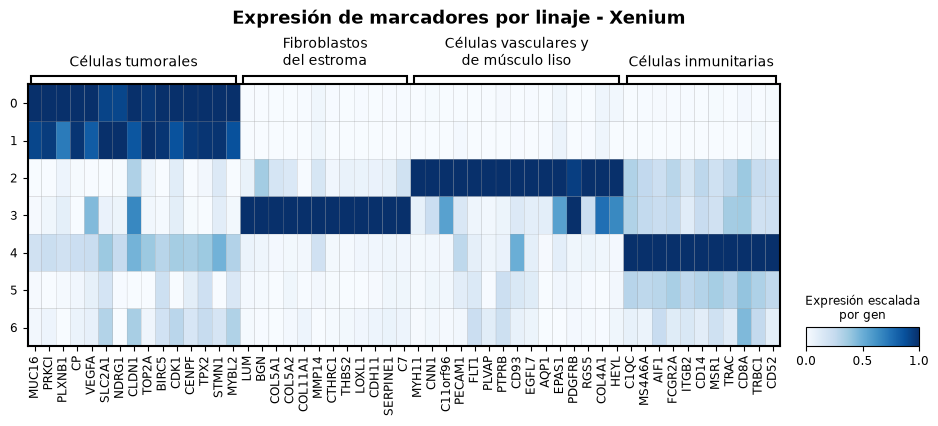

Generando Matrixplot de Expansión nuclear...


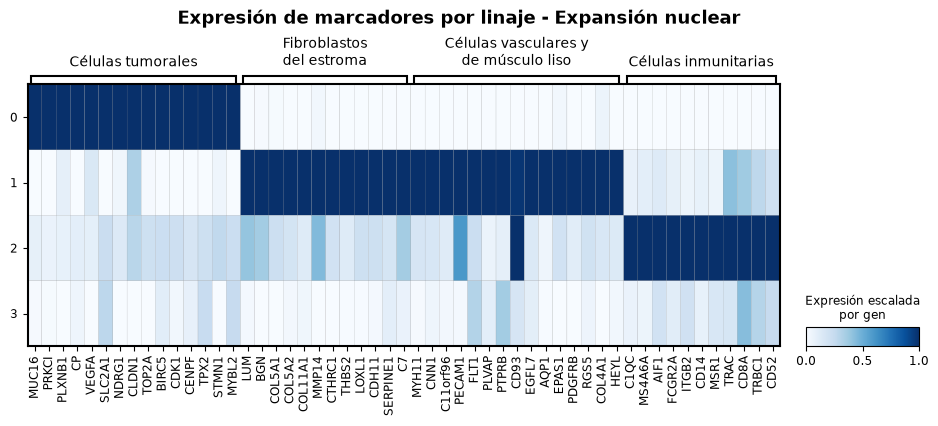

Generando Matrixplot de Cellpose...


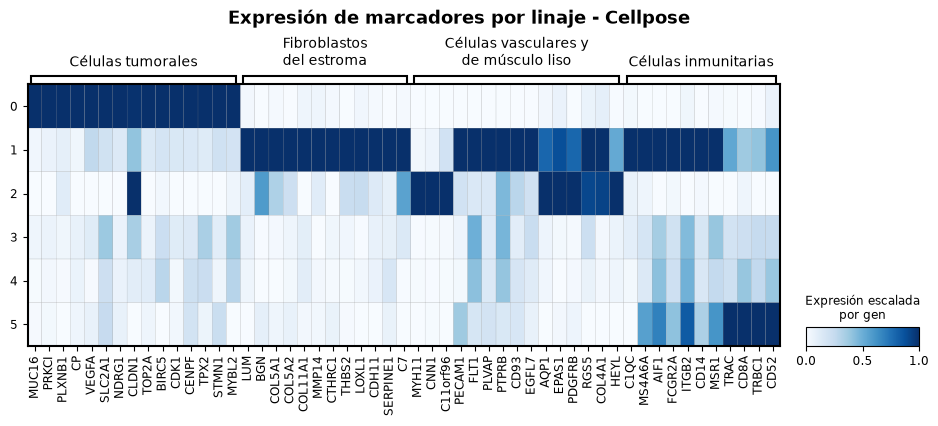

Generando Matrixplot de Baysor (sin prior)...


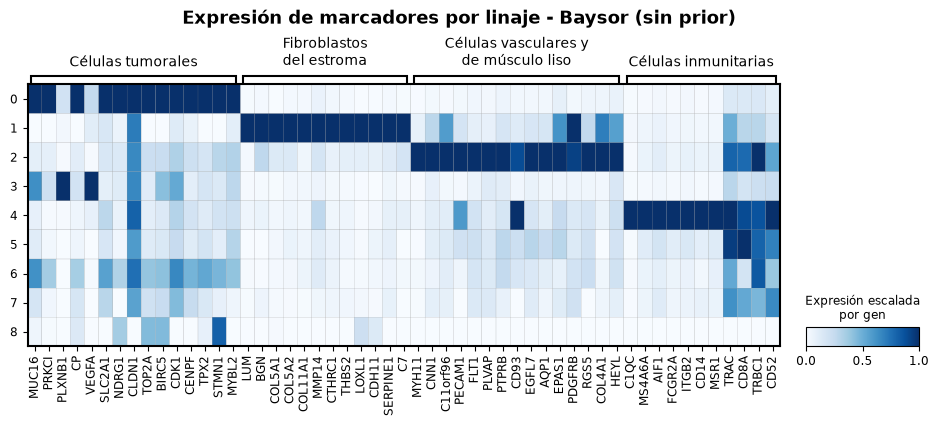

Generando Matrixplot de Baysor (prior nuclear)...


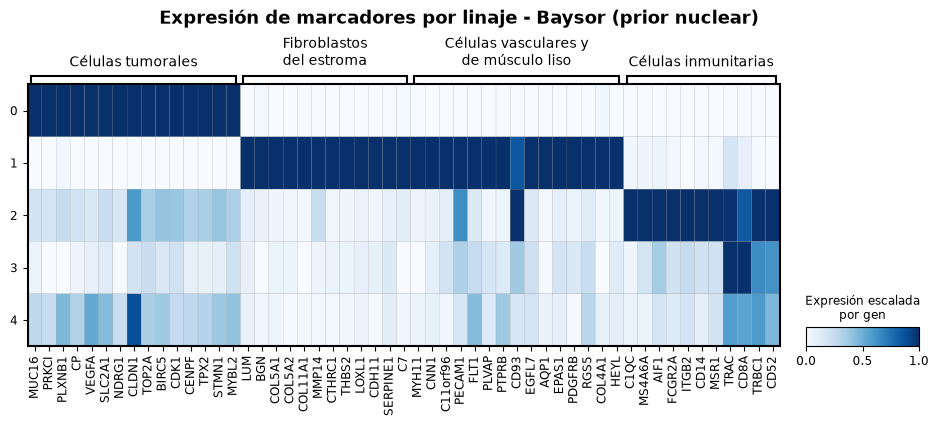

Generando Matrixplot de Baysor (prior celular)...


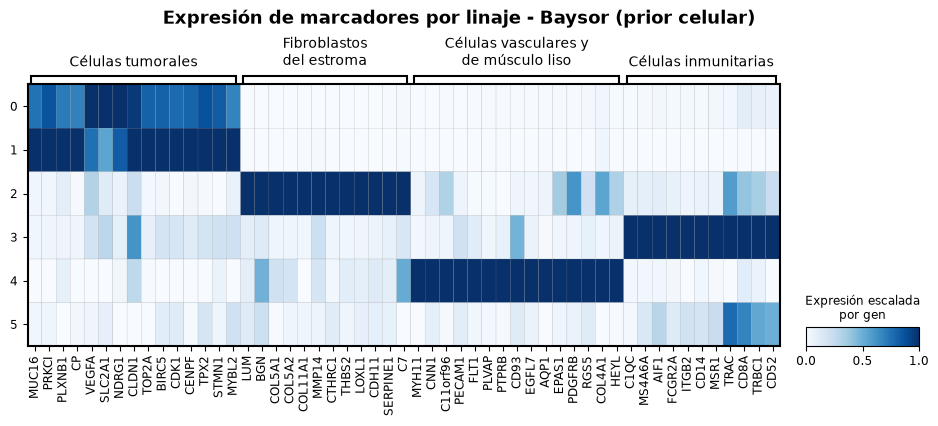

In [ ]:
# Creamos un diccionario para iterar sobre las tablas de cada método de segmentación:
adata_dict = {
    "Xenium": sdata_clustering.tables["table_xenium_default"],
    "Expansión nuclear": sdata_clustering.tables["table_nucleus_expanded"],
    "Cellpose": sdata_clustering.tables["table_cellpose"],
    "Baysor (sin prior)": sdata_clustering.tables["table_baysor_no_prior"],
    "Baysor (prior nuclear)": sdata_clustering.tables["table_baysor_nuclear_mask_prior"],
    "Baysor (prior celular)": sdata_clustering.tables["table_baysor_cellpose_cito_prior"]
}

# Creamos un diccionario para ajustar visualmente los nombres de los linajes celulares
# dentro del plot, añadiendo saltos de línea en nombres largos. El contenido es el mismo
# que el diccionario original de marcadores filtrados:
broad_markers_plot = {
    "Células tumorales": broad_markers_dict["Células tumorales"],
    "Fibroblastos\ndel estroma": broad_markers_dict["Fibroblastos del estroma"],
    "Células vasculares y\nde músculo liso": broad_markers_dict["Células vasculares y de músculo liso"],
    "Células inmunitarias": broad_markers_dict["Células inmunitarias"]
}

# Bucle para generar y guardar los matrixplots iterando sobre las tablas:
for method_name, adata in adata_dict.items():
    print(f"Generando Matrixplot de {method_name}...")
    
    # Generamos el Matrixplot, aportando el diccionario con los marcadores filtrados, agrupando las células usando la columna de clústeres
    # de Leiden con resolución 0.2, y asignando un mapa de colores azul para representar la expresión escalada de cada gen.
    sc.pl.matrixplot(
        adata,
        var_names=broad_markers_plot,
        groupby="leiden_res0_2",
        cmap="Blues",
        standard_scale="var",
        colorbar_title="Expresión escalada\npor gen",
        var_group_rotation=0,
        figsize=(11.5, 3.4),
        show=False 
    )
    # Añadimos un título a cada gráfico
    plt.suptitle(
        f"Expresión de marcadores por linaje - {method_name}", 
        y=1.1, 
        fontsize=13, 
        weight="bold"
    )

    # Guardamos el gráfico en un archivo .tiff
    filename = method_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    output_file = GRAPHS_CELL_ANNOTATION_DIR / f"matrixplot_linajes_{filename}.tiff"
    
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close('all')

En los Matrixplots podemos comprobar a simple vista si los marcadores correspondientes a cada linaje celular se han distribuido bien en clústeres definidos o si están repartidos entre varios clústeres, y también si un mismo clúster contiene más de un tipo celular, simplificando la realidad.

Otra manera de comparar las anotaciones celulares de los distintos métodos es determinar el tipo celular más probable para cada célula generada en la segmentación, y posteriormente comparar los porcentajes de cada tipo celular detectados para cada método. Para asignar un linaje a cada célula, podemos usar la función `score_genes` de `scanpy`. Esta función se basa en el paper de [Tirosh et al. (2016)](https://doi.org/10.1126/science.aad0501) y para cada célula calcula un score que indica cuánto se expresan los marcadores especificados por encima del nivel basal esperado por azar en esa célula, de la siguiente manera:
- Calcula la expresión media de todos los genes marcadores del linaje celular a determinar. Teniendo en cuenta que la matriz de conteos ya ha sido normalizada y log-transformada, el promedio de expresión suele tener un rango pequeño (entre 0 y 4, como se vio en el apartado de la normalización).
- Ordena todos los genes de la matriz de conteos en función de la abundancia global de transcritos, y lo divide en intervalos (por defecto, 25 intervalos o *bins* distintos).
- Para cada gen marcador, selecciona un conjunto de genes al azar que pertenezcan al mismo intervalo de abundancia (los genes control).
- Finalmente, calcula el score, restando la expresión media de los genes control a la media de los marcadores.

Si el valor del score es menor a 0 o cercano a 0, significa que los marcadores para ese linaje no se expresan más que el ruido de fondo aleatorio de la célula, y por lo tanto la célula no pertenece a ese linaje celular.

Si repetimos este cálculo con el conjunto de genes marcadores de los 4 linajes celulares seleccionados, podemos escoger el linaje con el score más alto y determinarlo como el tipo celular predicho. 

En caso de no obtener un score superior a 0 (o el valor que asignemos al umbral) para ninguno de los linajes, el tipo celular se determina como "sin asignar". Este límite, sin embargo, es necesario decidirlo en función de la distribución de scores que se obtenga, y fijarlo igual para todos los métodos de segmentación.

In [11]:
# Primero, para cada método de segmentación, vamos a calcular los scores por célula para cada uno de los 4 linajes celulares que hemos definido.
# Iteramos sobre el diccionario de tablas:
r_state = 23

for method_name, adata in adata_dict.items():
    print(f"Calculando scores para {method_name}...")

    # Calculamos el score de cada uno de los 4 linajes definidos en broad_markers_dict:
    for cell_type, genes in broad_markers_dict.items():
        
        score_col = f"score {cell_type}" # Nombre de la columna que contendrá los scores para cada linaje

        # La función score_genes() calcula el score en función de la lista de genes aportada, y almacena
        # el resultado en una nueva columna del objeto adata.obs con el nombre definido en score_col.
        sc.tl.score_genes(
            adata, 
            gene_list=genes, 
            score_name=score_col, 
            use_raw=False,
            random_state=r_state
        )


Calculando scores para Xenium...
Calculando scores para Expansión nuclear...
Calculando scores para Cellpose...
Calculando scores para Baysor (sin prior)...
Calculando scores para Baysor (prior nuclear)...
Calculando scores para Baysor (prior celular)...


Vamos a comprobar la distribución de los scores máximos obtenidos para cada célula en uno de los métodos a modo de ejemplo. De esta manera, podemos comprobar si hay una distinción clara entre las células que presentan una identidad clara y las que no, y establecer ahí el umbral de score por debajo del cual determinaremos que esa célula no tiene un linaje concreto asignado (de los 4 que hemos definido).

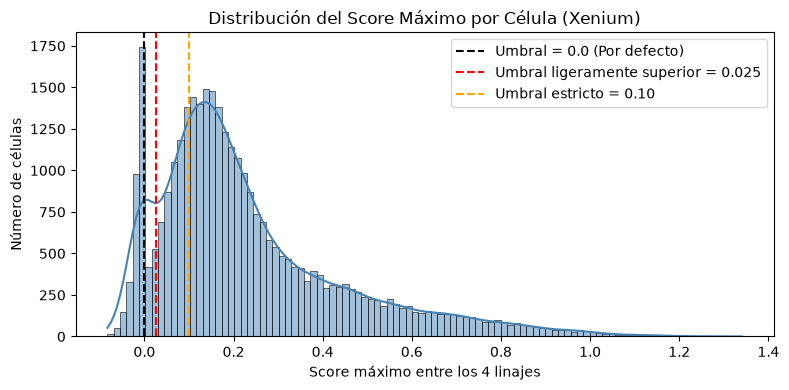

Umbral <= 0.000 -> 9.65% de células 'Sin asignar'
Umbral <= 0.025 -> 11.95% de células 'Sin asignar'
Umbral <= 0.050 -> 15.59% de células 'Sin asignar'
Umbral <= 0.100 -> 27.57% de células 'Sin asignar'
Umbral <= 0.150 -> 42.87% de células 'Sin asignar'


In [12]:
# Extraemos los scores ya calculados en el control de referencia (Xenium)
adata_xenium = adata_dict["Xenium"]
score_cols = [f"score {ct}" for ct in broad_markers_dict.keys()]
max_scores_xenium = adata_xenium.obs[score_cols].max(axis=1)

# Creamos el histograma del score máximo por célula
plt.figure(figsize=(8, 4))
sns.histplot(max_scores_xenium, bins=100, kde=True, color="steelblue")
plt.axvline(0.0, color="black", linestyle="--", label="Umbral = 0.0 (Por defecto)")
plt.axvline(0.025, color="red", linestyle="--", label="Umbral ligeramente superior = 0.025")
plt.axvline(0.10, color="orange", linestyle="--", label="Umbral estricto = 0.10")
plt.title("Distribución del Score Máximo por Célula (Xenium)")
plt.xlabel("Score máximo entre los 4 linajes")
plt.ylabel("Número de células")
plt.legend()
plt.tight_layout()
plt.show()

# Comprobamos cuántas células quedan "Sin asignar" con cada corte
for th in [0.0, 0.025, 0.05, 0.10, 0.15]:
    pct_unassigned = (max_scores_xenium <= th).mean() * 100
    print(f"Umbral <= {th:.3f} -> {pct_unassigned:.2f}% de células 'Sin asignar'")

Se observa una distribución bimodal, con un pico elevado de células situadas en torno a 0 (no tienen un linaje claramente definido), y un segundo pico con una distribución más amplia (células con un linaje celular definido). El punto de corte más adecuado entre ambas distribuciones se sitúa en 0.025, valor que definiremos como el umbral.

A continuación, asignamos a cada célula un linaje en función del score máximo que haya conseguido, y si ninguno de los scores que ha recibido es superior al umbral, entonces la etiquetamos como "Sin asignar".

Tras esto, podemos guardar los números y porcentajes de células asignadas a cada linaje según el método de segmentación, para poder comprobar las diferencias respecto al método control.

In [13]:
# Creamos una lista con los nombres de las columnas que contienen los scores, siguiendo
# la misma nomenclatura:
score_columns = [f"score {ct}" for ct in broad_markers_dict.keys()]

# Definimos dos diccionarios, para almacenar número y porcentajes de células
# asignadas a cada linaje y sin asignar:
counts_dict = {}
percentages_dict = {}

# Volvemos a iterar sobre las tablas de los distintos métodos de segmentación:
for method_name, adata in adata_dict.items():
    # Extraemos las columnas correspondientes a los scores en un DataFrame:
    scores_df = adata.obs[score_columns]
    
    # Para cada fila (célula), determinamos el linaje con el score más alto y lo asignamos a una nueva columna "predicted_cell_type" en adata.obs.
    # idxmax(axis=1) devuelve directamente el nombre de la columna ganadora en cada célula;
    # con .str.replace quitamos el prefijo "score " para quedarnos con el nombre limpio del linaje.
    adata.obs["predicted_cell_type"] = (
        scores_df.idxmax(axis=1).str.replace("score ", "", regex=False)
    )
    
    # Etiquetamos aquellas células que estén por debajo del umbral como "Sin asignar":
    mask_unassigned = scores_df.max(axis=1) <= 0.025
    adata.obs.loc[mask_unassigned, "predicted_cell_type"] = "Sin asignar"
    
    # Convertimos a categórico los valores.
    adata.obs["predicted_cell_type"] = adata.obs["predicted_cell_type"].astype("category")
    
    # Guardamos conteos y porcentajes para la tabla resumen
    counts = adata.obs["predicted_cell_type"].value_counts()
    counts_dict[method_name] = counts
    percentages_dict[method_name] = (counts / len(adata.obs)) * 100

# Mostramos y guardamos las tablas comparativas
df_counts = pd.DataFrame(counts_dict).fillna(0).astype(int)
FILE_PATH = TABLES_CELL_ANNOTATION_DIR / "cell_annotation_counts.csv"
df_counts.to_csv(FILE_PATH)

df_pct = pd.DataFrame(percentages_dict).fillna(0).round(2)
FILE_PATH = TABLES_CELL_ANNOTATION_DIR / "cell_annotation_percentages.csv"
df_pct.to_csv(FILE_PATH)

display(df_counts)
display(df_pct)

,Xenium,Expansión nuclear,Cellpose,Baysor (sin prior),Baysor (prior nuclear),Baysor (prior celular)
predicted_cell_type,,,,,,
Células inmunitarias,3973,4208,4328,6887,5679,4496
Células tumorales,15965,17567,16664,29193,24822,17255
Células vasculares y de músculo liso,4036,4237,4334,7682,6006,4586
Fibroblastos del estroma,5387,6535,6080,14304,11869,8283
Sin asignar,3985,3420,3571,17536,6844,3394


,Xenium,Expansión nuclear,Cellpose,Baysor (sin prior),Baysor (prior nuclear),Baysor (prior celular)
predicted_cell_type,,,,,,
Células inmunitarias,11.91,11.70,12.37,9.11,10.28,11.83
Células tumorales,47.88,48.84,47.64,38.61,44.95,45.39
Células vasculares y de músculo liso,12.10,11.78,12.39,10.16,10.88,12.06
Fibroblastos del estroma,16.15,18.17,17.38,18.92,21.49,21.79
Sin asignar,11.95,9.51,10.21,23.20,12.39,8.93


Finalmente, podemos calcular cuánto difieren las predicciones de los tipos celulares de cada método respecto al método control calculando la distancia de Jensen-Shannon. Esta métrica mide la distancia entre dos distribuciones de probabilidades, de manera que un valor de 0 indica que ambas distribuciones son idénticas, y un valor de 1 indica que ambas distribuciones son completamente distintas. Cuanto menor sea la distancia de Jensen-Shannon, por lo tanto, más parecidas serán las clasificaciones del método de segmentación concreto a las del método control.

In [16]:
# Para calcular la distancia de Jensen-Shannon necesitamos las probabilidades de cada
# categoría o linaje en el método control (Xenium) y en el método a comparar. Estos valores
# los guardamos en df_pct (en forma de porcentaje, hay que dividir entre 100).
baseline_prop = df_pct["Xenium"].values / 100.0
js_dist_results = [] # Creamos una lista vacía para guardar los resultados.

# Iteramos sobre las asignaciones celulares de cada método de segmentación:
for method_name in df_pct.columns:
    if method_name == "Xenium":
        continue
    method_prop = df_pct[method_name].values / 100.0
    
    # Calculamos la distancia de Jensen-Shannon
    js_dist = jensenshannon(baseline_prop, method_prop)
    
    js_dist_results.append({
        "Método": method_name,
        "Distancia de Jensen-Shannon": round(js_dist, 4),
    })

# Guardamos los resultados en un DataFrame
df_js_dist = pd.DataFrame(js_dist_results)
FILE_PATH = TABLES_CELL_ANNOTATION_DIR / "jensen_shannon_distance.csv"
df_js_dist.to_csv(FILE_PATH)
display(df_js_dist)

,Método,Distancia de Jensen-Shannon
0,Expansión nuclear,0.0321
1,Cellpose,0.0221
2,Baysor (sin prior),0.1164
3,Baysor (prior nuclear),0.0511
4,Baysor (prior celular),0.0580


Por último, podemos representar cómo se distribuyen los distintos tipos celulares en el UMAP y comprobar visualmente como difieren de los clústeres originales para cada método de segmentación:

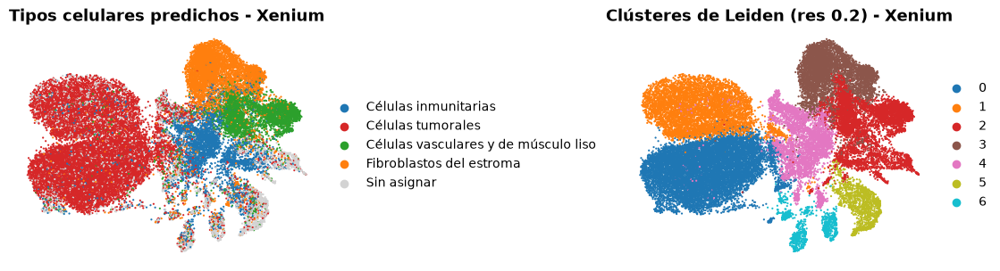

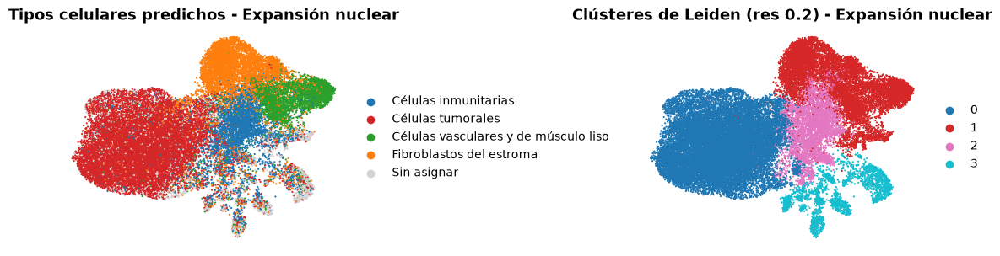

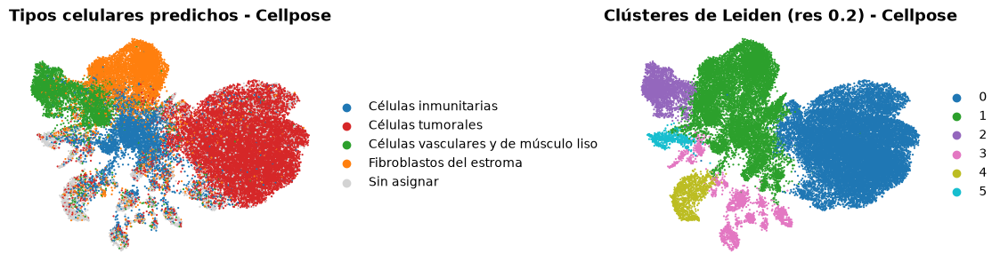

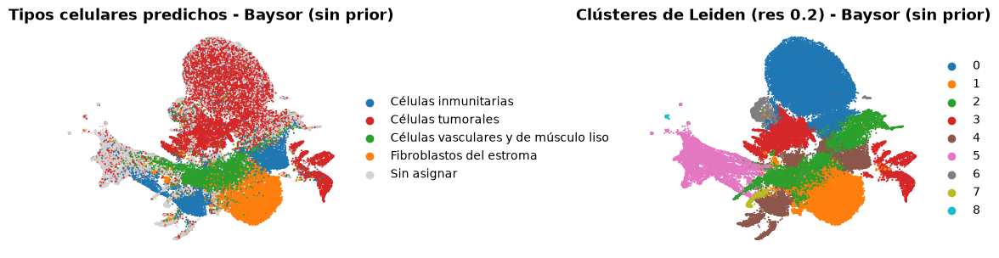

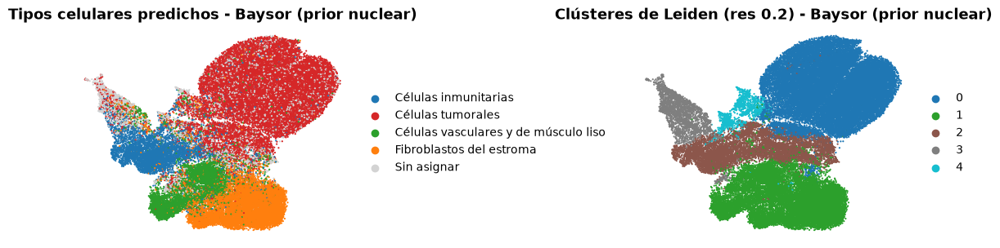

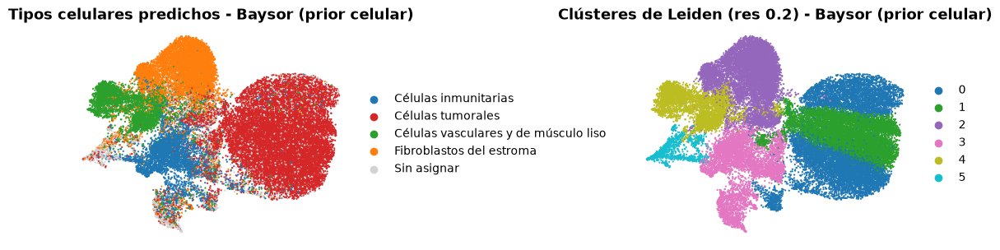

In [21]:
# Definimos una paleta de colores fija para que cada tipo celular tenga 
# siempre el mismo color en los 6 métodos de segmentación:
palette_cell_types = {
    "Células tumorales": "#d62728",                    # Rojo
    "Fibroblastos del estroma": "#ff7f0e",             # Naranja
    "Células vasculares y de músculo liso": "#2ca02c", # Verde
    "Células inmunitarias": "#1f77b4",                 # Azul
    "Sin asignar": "#d3d3d3"                           # Gris claro
}

for method_name, adata in adata_dict.items():

 # Generamos la figura comparativa de UMAP (Anotación celular vs Leiden)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))

    # Colocamos en el panel superior el UMAP coloreado por los tipos celulares predichos:
    sc.pl.umap(
        adata,
        color="predicted_cell_type",
        palette=palette_cell_types,
        legend_loc="right margin",
        frameon=False,
        size=10,
        ax=axes[0],
        show=False,
    )
    axes[0].set_title(f"Tipos celulares predichos - {method_name}", fontsize=13, weight="bold")

    # Colocamos en el panel inferior el UMAP coloreado por clústeres de Leiden (res 0.2)
    sc.pl.umap(
        adata,
        color="leiden_res0_2",
        palette="tab10",
        legend_loc="right margin",
        frameon=False,
        size=10,
        ax=axes[1],
        show=False,
    )
    axes[1].set_title(f"Clústeres de Leiden (res 0.2) - {method_name}", fontsize=13, weight="bold")

    plt.tight_layout(pad=2.0)

    # Guardamos en un archivo .tiff el gráfico comparativo de UMAP para cada método de segmentación:
    filename = method_name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    output_file = GRAPHS_CELL_ANNOTATION_DIR / f"umap_linajes_vs_leiden_{filename}.tiff"
    
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close('all')